In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel(r"C:\Users\Anish kumar tiwari\Downloads\twitter_disaster (1).xlsx")

In [3]:
df.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [4]:
df.shape

(7613, 5)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        7613 non-null   int64 
 1   keyword   7552 non-null   str   
 2   location  5079 non-null   object
 3   text      7613 non-null   str   
 4   target    7613 non-null   int64 
dtypes: int64(2), object(1), str(2)
memory usage: 1.1+ MB


In [7]:
df.isnull().sum()

id             0
keyword       61
location    2534
text           0
target         0
dtype: int64

In [8]:
(df.isnull().sum() / len(df)) * 100

id           0.000000
keyword      0.801261
location    33.285170
text         0.000000
target       0.000000
dtype: float64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df['target'].value_counts()

target
0    4342
1    3271
Name: count, dtype: int64

In [11]:
df['target'].value_counts(normalize=True) * 100

target
0    57.034021
1    42.965979
Name: proportion, dtype: float64

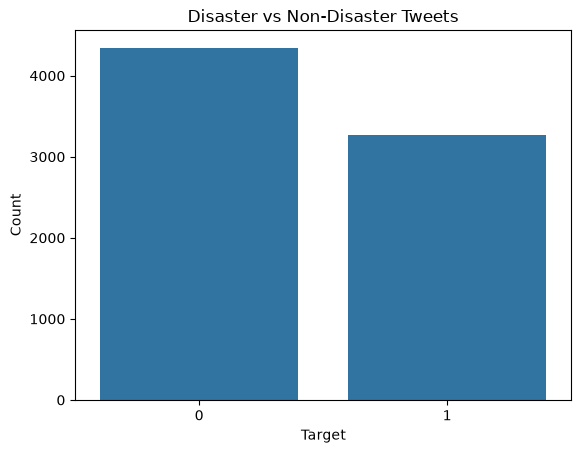

In [12]:
sns.countplot(x='target', data=df)

plt.title('Disaster vs Non-Disaster Tweets')
plt.xlabel('Target')
plt.ylabel('Count')

plt.show()

In [13]:
df['text_length'] = df['text'].str.len()

In [14]:
df[['text', 'text_length']].head()

,text,text_length
0,Our Deeds are the Reason of this #earthquake M...,69
1,Forest fire near La Ronge Sask. Canada,38
2,All residents asked to 'shelter in place' are ...,133
3,"13,000 people receive #wildfires evacuation or...",65
4,Just got sent this photo from Ruby #Alaska as ...,87


In [15]:
df['text_length'].describe()

count    7613.000000
mean      101.681203
std        34.352859
min         7.000000
25%        78.000000
50%       107.000000
75%       134.000000
max       190.000000
Name: text_length, dtype: float64

In [16]:
df.groupby('target')['text_length'].mean()


target
0     96.296868
1    108.828493
Name: text_length, dtype: float64

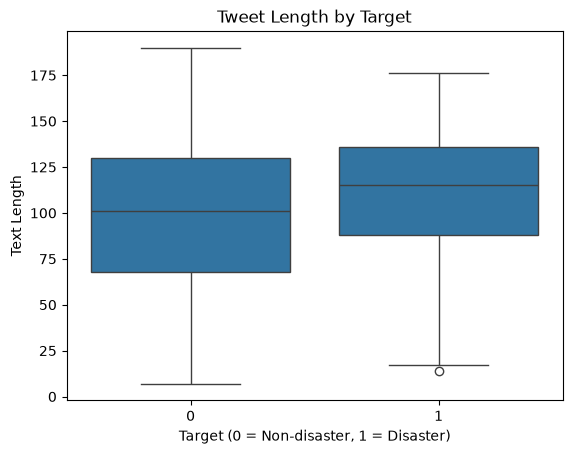

In [17]:
sns.boxplot(x='target', y='text_length', data=df)

plt.title('Tweet Length by Target')
plt.xlabel('Target (0 = Non-disaster, 1 = Disaster)')
plt.ylabel('Text Length')

plt.show()

In [18]:
df.groupby('target')['text_length'].mean()

target
0     96.296868
1    108.828493
Name: text_length, dtype: float64

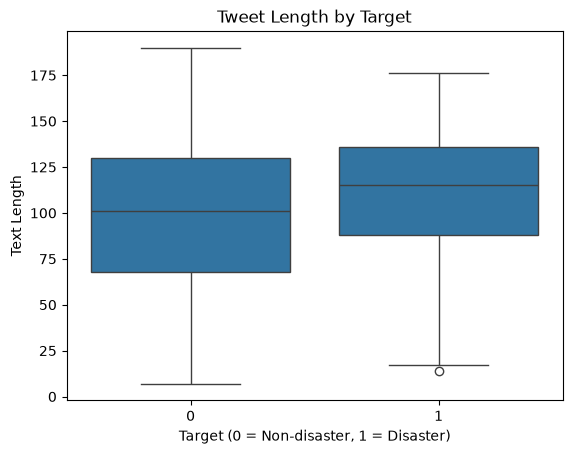

In [19]:
sns.boxplot(x='target', y='text_length', data=df)

plt.title('Tweet Length by Target')
plt.xlabel('Target (0 = Non-disaster, 1 = Disaster)')
plt.ylabel('Text Length')

plt.show()

In [20]:
df['keyword'].value_counts().head(10)

keyword
fatalities     45
armageddon     42
deluge         42
body%20bags    41
damage         41
harm           41
sinking        41
collided       40
evacuate       40
fear           40
Name: count, dtype: int64

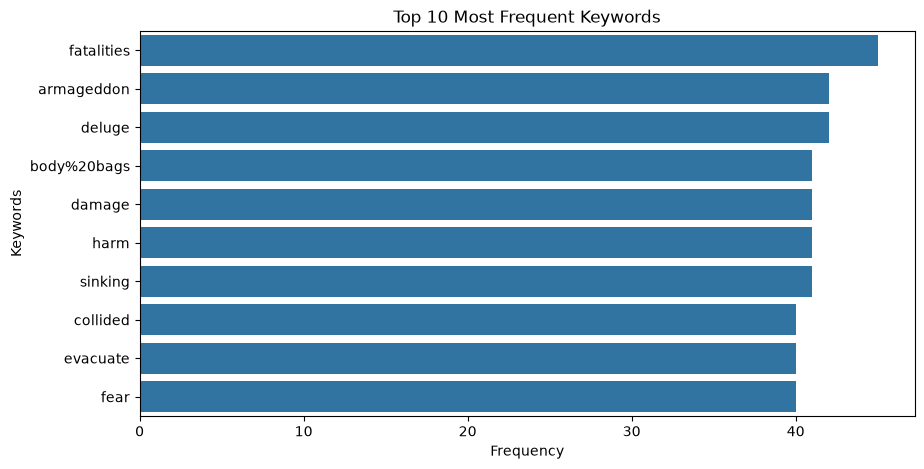

In [21]:
top_keywords = df['keyword'].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(x=top_keywords.values,
            y=top_keywords.index)

plt.title('Top 10 Most Frequent Keywords')
plt.xlabel('Frequency')
plt.ylabel('Keywords')

plt.show()

In [22]:
df.groupby(['keyword', 'target']).size().unstack(fill_value=0)

target,0,1
keyword,,
ablaze,23,13
accident,11,24
aftershock,34,0
airplane%20accident,5,30
ambulance,18,20
...,...,...
wounded,11,26
wounds,23,10
wreck,30,7


In [23]:
disaster_keywords = df[df['target'] == 1]['keyword']

disaster_keywords.value_counts().head(10)

keyword
derailment           39
outbreak             39
wreckage             39
debris               37
oil%20spill          37
typhoon              37
evacuated            32
rescuers             32
suicide%20bomb       32
suicide%20bombing    32
Name: count, dtype: int64

In [24]:
non_disaster_keywords = df[df['target'] == 0]['keyword']

non_disaster_keywords.value_counts().head(10)

keyword
body%20bags    40
armageddon     37
harm           37
deluge         36
ruin           36
wrecked        36
explode        35
fear           35
siren          35
twister        35
Name: count, dtype: int64

In [25]:
non_disaster_keywords = df[df['target'] == 0]['keyword']

non_disaster_keywords.value_counts().head(10)


keyword
body%20bags    40
armageddon     37
harm           37
deluge         36
ruin           36
wrecked        36
explode        35
fear           35
siren          35
twister        35
Name: count, dtype: int64

In [26]:
disaster_keywords = df.loc[df['target'] == 1, 'keyword']

disaster_keywords.value_counts().head(10)

keyword
derailment           39
outbreak             39
wreckage             39
debris               37
oil%20spill          37
typhoon              37
evacuated            32
rescuers             32
suicide%20bomb       32
suicide%20bombing    32
Name: count, dtype: int64

In [27]:
df['location'].value_counts().head(10)

location
USA                105
New York            73
United States       50
London              46
Nigeria             32
Canada              30
UK                  27
Los Angeles, CA     26
India               24
Mumbai              22
Name: count, dtype: int64

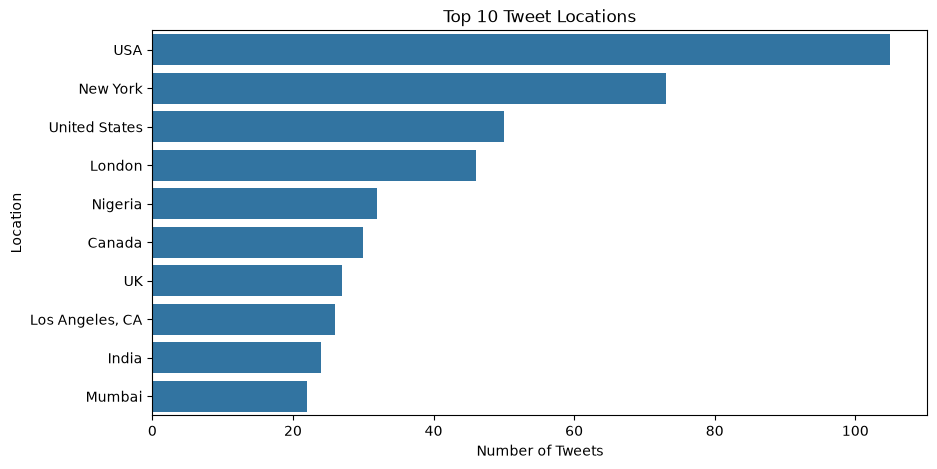

In [28]:
top_locations = df['location'].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(x=top_locations.values, y=top_locations.index)

plt.title('Top 10 Tweet Locations')
plt.xlabel('Number of Tweets')
plt.ylabel('Location')

plt.show()

In [29]:
top_locations = df['location'].value_counts().head(10).index

location_analysis = df[df['location'].isin(top_locations)]

In [30]:
location_clean = location_analysis['location'].astype('string')

pd.crosstab(location_clean, location_analysis['target'])

target,0,1
location,,
Canada,17,13
India,4,20
London,30,16
"Los Angeles, CA",18,8
Mumbai,3,19
New York,56,17
Nigeria,6,26
UK,11,16
USA,38,67


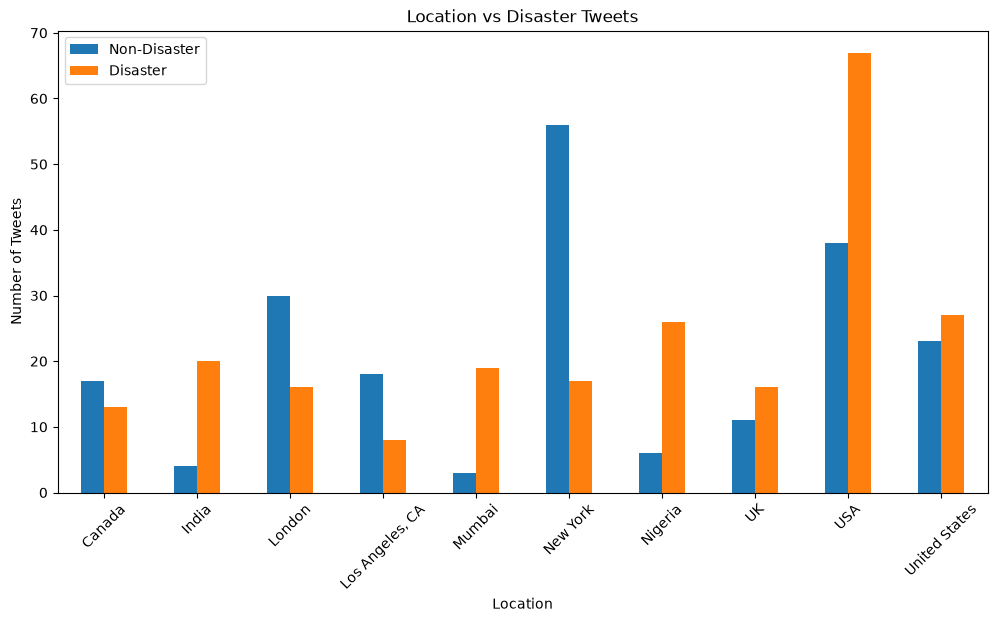

In [31]:
location_table = pd.crosstab(
    location_clean,
    location_analysis['target']
)

location_table.plot(kind='bar', figsize=(12, 6))

plt.title('Location vs Disaster Tweets')
plt.xlabel('Location')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=45)
plt.legend(['Non-Disaster', 'Disaster'])

plt.show()

In [32]:
df[['text', 'target']].head(10)

,text,target
0,Our Deeds are the Reason of this #earthquake M...,1
1,Forest fire near La Ronge Sask. Canada,1
2,All residents asked to 'shelter in place' are ...,1
3,"13,000 people receive #wildfires evacuation or...",1
4,Just got sent this photo from Ruby #Alaska as ...,1
5,#RockyFire Update => California Hwy. 20 closed...,1
6,#flood #disaster Heavy rain causes flash flood...,1
7,I'm on top of the hill and I can see a fire in...,1
8,There's an emergency evacuation happening now ...,1
9,I'm afraid that the tornado is coming to our a...,1


In [33]:
df[df['target'] == 1]['text'].head(10)

0    Our Deeds are the Reason of this #earthquake M...
1               Forest fire near La Ronge Sask. Canada
2    All residents asked to 'shelter in place' are ...
3    13,000 people receive #wildfires evacuation or...
4    Just got sent this photo from Ruby #Alaska as ...
5    #RockyFire Update => California Hwy. 20 closed...
6    #flood #disaster Heavy rain causes flash flood...
7    I'm on top of the hill and I can see a fire in...
8    There's an emergency evacuation happening now ...
9    I'm afraid that the tornado is coming to our a...
Name: text, dtype: str

In [34]:
df[df['target'] == 0]['text'].head(10)

15                  What's up man?
16                   I love fruits
17                Summer is lovely
18               My car is so fast
19    What a goooooooaaaaaal!!!!!!
20          this is ridiculous....
21               London is cool ;)
22                     Love skiing
23           What a wonderful day!
24                        LOOOOOOL
Name: text, dtype: str

In [35]:
df[df['target'] == 1]['text'].head(10)

0    Our Deeds are the Reason of this #earthquake M...
1               Forest fire near La Ronge Sask. Canada
2    All residents asked to 'shelter in place' are ...
3    13,000 people receive #wildfires evacuation or...
4    Just got sent this photo from Ruby #Alaska as ...
5    #RockyFire Update => California Hwy. 20 closed...
6    #flood #disaster Heavy rain causes flash flood...
7    I'm on top of the hill and I can see a fire in...
8    There's an emergency evacuation happening now ...
9    I'm afraid that the tornado is coming to our a...
Name: text, dtype: str

In [36]:
df['has_url'] = df['text'].str.contains(
    r'http\S+|www\S+', regex=True
)

df['has_url'].value_counts()

has_url
True     3976
False    3637
Name: count, dtype: int64

In [37]:
df['has_hashtag'] = df['text'].str.contains('#')

df['has_hashtag'].value_counts()

has_hashtag
False    5852
True     1761
Name: count, dtype: int64

In [38]:
df['has_mention'] = df['text'].str.contains('@')

df['has_mention'].value_counts()

has_mention
False    5574
True     2039
Name: count, dtype: int64

In [39]:
df['has_special_char'] = df['text'].str.contains(
    r'[^a-zA-Z0-9\s]', regex=True
)

df['has_special_char'].value_counts()

has_special_char
True     7278
False     335
Name: count, dtype: int64

In [40]:
special_tweets = df[df['has_special_char'] == True]

special_tweets[['text', 'target']].head(10)

,text,target
0,Our Deeds are the Reason of this #earthquake M...,1
1,Forest fire near La Ronge Sask. Canada,1
2,All residents asked to 'shelter in place' are ...,1
3,"13,000 people receive #wildfires evacuation or...",1
4,Just got sent this photo from Ruby #Alaska as ...,1
5,#RockyFire Update => California Hwy. 20 closed...,1
6,#flood #disaster Heavy rain causes flash flood...,1
7,I'm on top of the hill and I can see a fire in...,1
8,There's an emergency evacuation happening now ...,1
9,I'm afraid that the tornado is coming to our a...,1


In [41]:
df['has_html_entity'] = df['text'].str.contains(
    r'&amp;|&lt;|&gt;|&#\d+;', regex=True
)

df['has_html_entity'].value_counts()

has_html_entity
False    7254
True      359
Name: count, dtype: int64

In [42]:
html_tweets = df[df['has_html_entity'] == True]

html_tweets[['text', 'target']].head(10)

,text,target
62,Rene Ablaze &amp; Jacinta - Secret 2k13 (Falle...,0
64,#NowPlaying: Rene Ablaze &amp; Ian Buff - Magn...,0
67,I can't have kids cuz I got in a bicycle accid...,0
70,http://t.co/GKYe6gjTk5 Had a #personalinjury a...,0
83,#TruckCrash Overturns On #FortWorth Interstate...,1
124,&gt;&gt; $15 Aftershock : Protect Yourself and...,0
171,Early wake up call from my sister begging me t...,1
195,when you don't know which way an ambulance is ...,1
257,@willienelson We need help! Horses will die!Pl...,1
260,The annihilation of Jeb Christie &amp; Kasich ...,0


In [43]:
import html

In [44]:
df['decoded_text'] = df['text'].apply(html.unescape)

In [45]:
df[['text', 'decoded_text']].head(10)

,text,decoded_text
0,Our Deeds are the Reason of this #earthquake M...,Our Deeds are the Reason of this #earthquake M...
1,Forest fire near La Ronge Sask. Canada,Forest fire near La Ronge Sask. Canada
2,All residents asked to 'shelter in place' are ...,All residents asked to 'shelter in place' are ...
3,"13,000 people receive #wildfires evacuation or...","13,000 people receive #wildfires evacuation or..."
4,Just got sent this photo from Ruby #Alaska as ...,Just got sent this photo from Ruby #Alaska as ...
5,#RockyFire Update => California Hwy. 20 closed...,#RockyFire Update => California Hwy. 20 closed...
6,#flood #disaster Heavy rain causes flash flood...,#flood #disaster Heavy rain causes flash flood...
7,I'm on top of the hill and I can see a fire in...,I'm on top of the hill and I can see a fire in...
8,There's an emergency evacuation happening now ...,There's an emergency evacuation happening now ...
9,I'm afraid that the tornado is coming to our a...,I'm afraid that the tornado is coming to our a...


In [46]:
df.loc[
    df['has_html_entity'] == True,
    ['text', 'decoded_text']
].head(10)

,text,decoded_text
62,Rene Ablaze &amp; Jacinta - Secret 2k13 (Falle...,Rene Ablaze & Jacinta - Secret 2k13 (Fallen Sk...
64,#NowPlaying: Rene Ablaze &amp; Ian Buff - Magn...,#NowPlaying: Rene Ablaze & Ian Buff - Magnitud...
67,I can't have kids cuz I got in a bicycle accid...,I can't have kids cuz I got in a bicycle accid...
70,http://t.co/GKYe6gjTk5 Had a #personalinjury a...,http://t.co/GKYe6gjTk5 Had a #personalinjury a...
83,#TruckCrash Overturns On #FortWorth Interstate...,#TruckCrash Overturns On #FortWorth Interstate...
124,&gt;&gt; $15 Aftershock : Protect Yourself and...,>> $15 Aftershock : Protect Yourself and Profi...
171,Early wake up call from my sister begging me t...,Early wake up call from my sister begging me t...
195,when you don't know which way an ambulance is ...,when you don't know which way an ambulance is ...
257,@willienelson We need help! Horses will die!Pl...,@willienelson We need help! Horses will die!Pl...
260,The annihilation of Jeb Christie &amp; Kasich ...,The annihilation of Jeb Christie & Kasich is l...


In [47]:
(df['text'] != df['decoded_text']).sum()

np.int64(359)

In [48]:
df['text_no_url'] = df['decoded_text'].str.replace(
    r'http\S+|www\S+',
    '',
    regex=True
)

In [49]:
df[['decoded_text', 'text_no_url']].head(10)

,decoded_text,text_no_url
0,Our Deeds are the Reason of this #earthquake M...,Our Deeds are the Reason of this #earthquake M...
1,Forest fire near La Ronge Sask. Canada,Forest fire near La Ronge Sask. Canada
2,All residents asked to 'shelter in place' are ...,All residents asked to 'shelter in place' are ...
3,"13,000 people receive #wildfires evacuation or...","13,000 people receive #wildfires evacuation or..."
4,Just got sent this photo from Ruby #Alaska as ...,Just got sent this photo from Ruby #Alaska as ...
5,#RockyFire Update => California Hwy. 20 closed...,#RockyFire Update => California Hwy. 20 closed...
6,#flood #disaster Heavy rain causes flash flood...,#flood #disaster Heavy rain causes flash flood...
7,I'm on top of the hill and I can see a fire in...,I'm on top of the hill and I can see a fire in...
8,There's an emergency evacuation happening now ...,There's an emergency evacuation happening now ...
9,I'm afraid that the tornado is coming to our a...,I'm afraid that the tornado is coming to our a...


In [50]:
df['text_no_url'].str.contains(
    r'http\S+|www\S+',
    regex=True
).sum()

np.int64(0)

In [51]:
df['text_no_mention'] = df['text_no_url'].str.replace(
    r'@\w+',
    '',
    regex=True
)

In [52]:
df[['text', 'text_no_mention']].head(10)

,text,text_no_mention
0,Our Deeds are the Reason of this #earthquake M...,Our Deeds are the Reason of this #earthquake M...
1,Forest fire near La Ronge Sask. Canada,Forest fire near La Ronge Sask. Canada
2,All residents asked to 'shelter in place' are ...,All residents asked to 'shelter in place' are ...
3,"13,000 people receive #wildfires evacuation or...","13,000 people receive #wildfires evacuation or..."
4,Just got sent this photo from Ruby #Alaska as ...,Just got sent this photo from Ruby #Alaska as ...
5,#RockyFire Update => California Hwy. 20 closed...,#RockyFire Update => California Hwy. 20 closed...
6,#flood #disaster Heavy rain causes flash flood...,#flood #disaster Heavy rain causes flash flood...
7,I'm on top of the hill and I can see a fire in...,I'm on top of the hill and I can see a fire in...
8,There's an emergency evacuation happening now ...,There's an emergency evacuation happening now ...
9,I'm afraid that the tornado is coming to our a...,I'm afraid that the tornado is coming to our a...


In [53]:
df['text_no_mention'].str.contains(
    r'@\w+',
    regex=True
).sum()

np.int64(0)

In [54]:
df['text_no_mention'].str.contains(
    r'[^a-zA-Z0-9\s]',
    regex=True
).sum()

np.int64(6509)

In [55]:
df['text_no_mention'].str.contains(
    r'@\w+',
    regex=True
).sum()

np.int64(0)

In [56]:
df['text_no_hashtag'] = df['text_no_mention'].str.replace(
    '#',
    '',
    regex=False
)

In [57]:
df[['text_no_mention', 'text_no_hashtag']].head(15)

,text_no_mention,text_no_hashtag
0,Our Deeds are the Reason of this #earthquake M...,Our Deeds are the Reason of this earthquake Ma...
1,Forest fire near La Ronge Sask. Canada,Forest fire near La Ronge Sask. Canada
2,All residents asked to 'shelter in place' are ...,All residents asked to 'shelter in place' are ...
3,"13,000 people receive #wildfires evacuation or...","13,000 people receive wildfires evacuation ord..."
4,Just got sent this photo from Ruby #Alaska as ...,Just got sent this photo from Ruby Alaska as s...
5,#RockyFire Update => California Hwy. 20 closed...,RockyFire Update => California Hwy. 20 closed ...
6,#flood #disaster Heavy rain causes flash flood...,flood disaster Heavy rain causes flash floodin...
7,I'm on top of the hill and I can see a fire in...,I'm on top of the hill and I can see a fire in...
8,There's an emergency evacuation happening now ...,There's an emergency evacuation happening now ...
9,I'm afraid that the tornado is coming to our a...,I'm afraid that the tornado is coming to our a...


In [58]:
df['text_lower'] = df['text_no_hashtag'].str.lower()

In [59]:
df[['text_no_hashtag', 'text_lower']].head(15)

,text_no_hashtag,text_lower
0,Our Deeds are the Reason of this earthquake Ma...,our deeds are the reason of this earthquake ma...
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask. canada
2,All residents asked to 'shelter in place' are ...,all residents asked to 'shelter in place' are ...
3,"13,000 people receive wildfires evacuation ord...","13,000 people receive wildfires evacuation ord..."
4,Just got sent this photo from Ruby Alaska as s...,just got sent this photo from ruby alaska as s...
5,RockyFire Update => California Hwy. 20 closed ...,rockyfire update => california hwy. 20 closed ...
6,flood disaster Heavy rain causes flash floodin...,flood disaster heavy rain causes flash floodin...
7,I'm on top of the hill and I can see a fire in...,i'm on top of the hill and i can see a fire in...
8,There's an emergency evacuation happening now ...,there's an emergency evacuation happening now ...
9,I'm afraid that the tornado is coming to our a...,i'm afraid that the tornado is coming to our a...


In [60]:
df['text_clean'] = df['text_lower'].str.replace(
    r'[^a-zA-Z0-9\s]',
    ' ',
    regex=True
)

In [61]:
df[['text_lower', 'text_clean']].head(15)

,text_lower,text_clean
0,our deeds are the reason of this earthquake ma...,our deeds are the reason of this earthquake ma...
1,forest fire near la ronge sask. canada,forest fire near la ronge sask canada
2,all residents asked to 'shelter in place' are ...,all residents asked to shelter in place are ...
3,"13,000 people receive wildfires evacuation ord...",13 000 people receive wildfires evacuation ord...
4,just got sent this photo from ruby alaska as s...,just got sent this photo from ruby alaska as s...
5,rockyfire update => california hwy. 20 closed ...,rockyfire update california hwy 20 closed ...
6,flood disaster heavy rain causes flash floodin...,flood disaster heavy rain causes flash floodin...
7,i'm on top of the hill and i can see a fire in...,i m on top of the hill and i can see a fire in...
8,there's an emergency evacuation happening now ...,there s an emergency evacuation happening now ...
9,i'm afraid that the tornado is coming to our a...,i m afraid that the tornado is coming to our a...


In [62]:
df['text_clean'].str.contains(
    r'[^a-zA-Z0-9\s]',
    regex=True
).sum()

np.int64(0)

In [63]:
df['text_clean'] = df['text_clean'].str.replace(
    r'\s+',
    ' ',
    regex=True
).str.strip()

In [64]:
df[['text', 'text_clean']].head(15)

,text,text_clean
0,Our Deeds are the Reason of this #earthquake M...,our deeds are the reason of this earthquake ma...
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask canada
2,All residents asked to 'shelter in place' are ...,all residents asked to shelter in place are be...
3,"13,000 people receive #wildfires evacuation or...",13 000 people receive wildfires evacuation ord...
4,Just got sent this photo from Ruby #Alaska as ...,just got sent this photo from ruby alaska as s...
5,#RockyFire Update => California Hwy. 20 closed...,rockyfire update california hwy 20 closed in b...
6,#flood #disaster Heavy rain causes flash flood...,flood disaster heavy rain causes flash floodin...
7,I'm on top of the hill and I can see a fire in...,i m on top of the hill and i can see a fire in...
8,There's an emergency evacuation happening now ...,there s an emergency evacuation happening now ...
9,I'm afraid that the tornado is coming to our a...,i m afraid that the tornado is coming to our area


In [65]:
(df['text_clean'].str.len() == 0).sum()

np.int64(0)

In [66]:
df['word_count'] = df['text_clean'].apply(
    lambda x: len(x.split())
)

In [67]:
df[['text_clean', 'word_count']].head(10)

,text_clean,word_count
0,our deeds are the reason of this earthquake ma...,13
1,forest fire near la ronge sask canada,7
2,all residents asked to shelter in place are be...,22
3,13 000 people receive wildfires evacuation ord...,9
4,just got sent this photo from ruby alaska as s...,16
5,rockyfire update california hwy 20 closed in b...,16
6,flood disaster heavy rain causes flash floodin...,14
7,i m on top of the hill and i can see a fire in...,16
8,there s an emergency evacuation happening now ...,13
9,i m afraid that the tornado is coming to our area,11


In [68]:
df['word_count'].describe()

count    7613.000000
mean       14.223302
std         6.100580
min         1.000000
25%        10.000000
50%        14.000000
75%        18.000000
max        34.000000
Name: word_count, dtype: float64

In [69]:
df.groupby('target')['word_count'].mean()

target
0    14.046522
1    14.457964
Name: word_count, dtype: float64

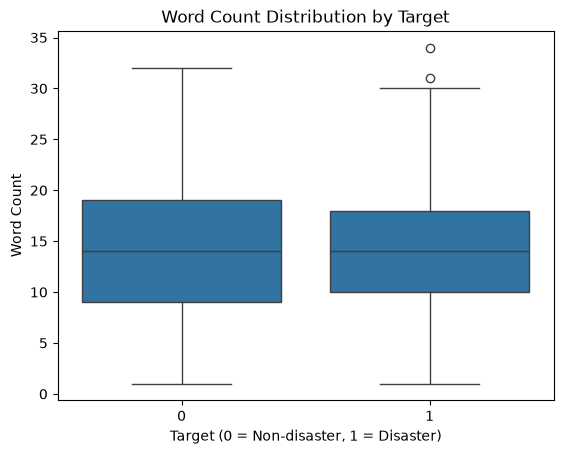

In [70]:
sns.boxplot(x='target', y='word_count', data=df)

plt.title('Word Count Distribution by Target')
plt.xlabel('Target (0 = Non-disaster, 1 = Disaster)')
plt.ylabel('Word Count')

plt.show()

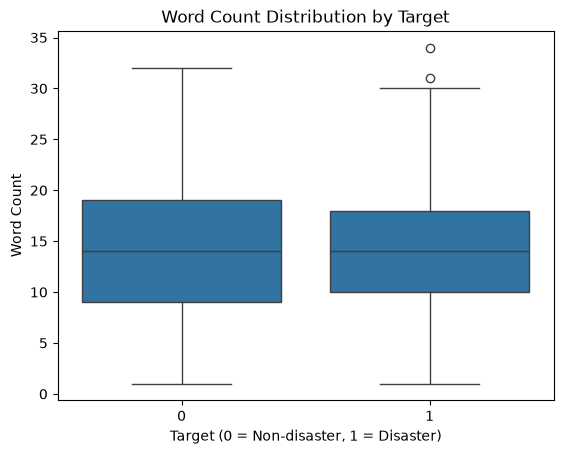

In [71]:
sns.boxplot(x='target', y='word_count', data=df)

plt.title('Word Count Distribution by Target')
plt.xlabel('Target (0 = Non-disaster, 1 = Disaster)')
plt.ylabel('Word Count')

plt.show()

In [72]:
df.groupby('target')['word_count'].mean()

target
0    14.046522
1    14.457964
Name: word_count, dtype: float64

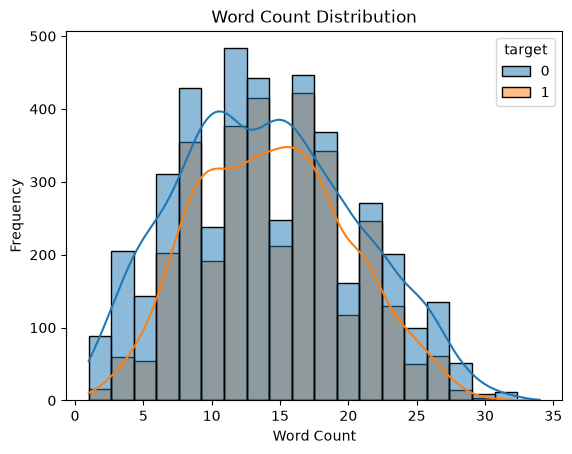

In [73]:
sns.histplot(
    data=df,
    x='word_count',
    hue='target',
    bins=20,
    kde=True
)

plt.title('Word Count Distribution')
plt.xlabel('Word Count')
plt.ylabel('Frequency')

plt.show()

In [74]:
df['tokens'] = df['text_clean'].apply(
    lambda x: x.split()
)

In [75]:
df[['text_clean', 'tokens']].head(10)

,text_clean,tokens
0,our deeds are the reason of this earthquake ma...,"[our, deeds, are, the, reason, of, this, earth..."
1,forest fire near la ronge sask canada,"[forest, fire, near, la, ronge, sask, canada]"
2,all residents asked to shelter in place are be...,"[all, residents, asked, to, shelter, in, place..."
3,13 000 people receive wildfires evacuation ord...,"[13, 000, people, receive, wildfires, evacuati..."
4,just got sent this photo from ruby alaska as s...,"[just, got, sent, this, photo, from, ruby, ala..."
5,rockyfire update california hwy 20 closed in b...,"[rockyfire, update, california, hwy, 20, close..."
6,flood disaster heavy rain causes flash floodin...,"[flood, disaster, heavy, rain, causes, flash, ..."
7,i m on top of the hill and i can see a fire in...,"[i, m, on, top, of, the, hill, and, i, can, se..."
8,there s an emergency evacuation happening now ...,"[there, s, an, emergency, evacuation, happenin..."
9,i m afraid that the tornado is coming to our area,"[i, m, afraid, that, the, tornado, is, coming,..."


In [76]:
df['tokens'].iloc[0]

['our',
 'deeds',
 'are',
 'the',
 'reason',
 'of',
 'this',
 'earthquake',
 'may',
 'allah',
 'forgive',
 'us',
 'all']

In [77]:
from collections import Counter


In [78]:
all_words = []

for tokens in df['tokens']:
    all_words.extend(tokens)

In [79]:
word_freq = Counter(all_words)

word_freq.most_common(20)

[('the', 3281),
 ('a', 2209),
 ('in', 1989),
 ('to', 1949),
 ('of', 1830),
 ('i', 1780),
 ('and', 1427),
 ('s', 995),
 ('is', 950),
 ('you', 905),
 ('for', 896),
 ('on', 862),
 ('x0089', 782),
 ('it', 779),
 ('my', 679),
 ('that', 625),
 ('with', 574),
 ('at', 543),
 ('by', 527),
 ('t', 511)]

In [80]:
df[df['text_clean'].str.contains(
    'x0089',
    regex=False
)][['text', 'text_clean', 'target']].head(10)

,text,text_clean,target
38,Barbados #Bridgetown JAMAICA _x0089_ÛÒ Two car...,barbados bridgetown jamaica x0089 two cars set...,1
52,SANTA CRUZ _x0089_ÛÓ Head of the St Elizabeth ...,santa cruz x0089 head of the st elizabeth poli...,0
71,#stlouis #caraccidentlawyer Speeding Among Top...,stlouis caraccidentlawyer speeding among top c...,0
87,RT nAAYf: First accident in years. Turning ont...,rt naayf first accident in years turning onto ...,1
104,320 [IR] ICEMOON [AFTERSHOCK] | http://t.co/yN...,320 ir icemoon aftershock dubstep trapmusic dn...,0
106,320 [IR] ICEMOON [AFTERSHOCK] | http://t.co/vA...,320 ir icemoon aftershock dubstep trapmusic dn...,0
114,320 [IR] ICEMOON [AFTERSHOCK] | http://t.co/M4...,320 ir icemoon aftershock dubstep trapmusic dn...,0
115,320 [IR] ICEMOON [AFTERSHOCK] | http://t.co/vA...,320 ir icemoon aftershock dubstep trapmusic dn...,0
116,320 [IR] ICEMOON [AFTERSHOCK] | http://t.co/e1...,320 ir icemoon aftershock dubstep trapmusic dn...,0
118,320 [IR] ICEMOON [AFTERSHOCK] | http://t.co/TH...,320 ir icemoon aftershock dubstep trapmusic dn...,0


In [81]:
import nltk

from nltk.corpus import stopwords

nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

print("Total stopwords:", len(stop_words))
print("Example stopwords:", list(stop_words)[:20])

[nltk_data] Downloading package stopwords to C:\Users\Anish kumar
[nltk_data]     tiwari\AppData\Roaming\nltk_data...


Total stopwords: 198
Example stopwords: ["he'll", 'or', "you'd", 'he', "i'd", 'nor', 'only', 'because', 'shan', 'did', 'below', 'me', 'up', 'own', 'theirs', "we've", "don't", 'again', 'off', "they'd"]


[nltk_data]   Unzipping corpora\stopwords.zip.


In [82]:
df[df['text_clean'].str.contains(
    'x0089',
    regex=False
)][['text', 'text_clean', 'target']].head(10)

,text,text_clean,target
38,Barbados #Bridgetown JAMAICA _x0089_ÛÒ Two car...,barbados bridgetown jamaica x0089 two cars set...,1
52,SANTA CRUZ _x0089_ÛÓ Head of the St Elizabeth ...,santa cruz x0089 head of the st elizabeth poli...,0
71,#stlouis #caraccidentlawyer Speeding Among Top...,stlouis caraccidentlawyer speeding among top c...,0
87,RT nAAYf: First accident in years. Turning ont...,rt naayf first accident in years turning onto ...,1
104,320 [IR] ICEMOON [AFTERSHOCK] | http://t.co/yN...,320 ir icemoon aftershock dubstep trapmusic dn...,0
106,320 [IR] ICEMOON [AFTERSHOCK] | http://t.co/vA...,320 ir icemoon aftershock dubstep trapmusic dn...,0
114,320 [IR] ICEMOON [AFTERSHOCK] | http://t.co/M4...,320 ir icemoon aftershock dubstep trapmusic dn...,0
115,320 [IR] ICEMOON [AFTERSHOCK] | http://t.co/vA...,320 ir icemoon aftershock dubstep trapmusic dn...,0
116,320 [IR] ICEMOON [AFTERSHOCK] | http://t.co/e1...,320 ir icemoon aftershock dubstep trapmusic dn...,0
118,320 [IR] ICEMOON [AFTERSHOCK] | http://t.co/TH...,320 ir icemoon aftershock dubstep trapmusic dn...,0


In [83]:
df['text'].str.contains(
    r'_x[0-9A-Fa-f]{4}_',
    regex=True
).sum()

np.int64(614)

In [84]:
import re
from collections import Counter

encoding_patterns = []

for tweet in df['text']:
    matches = re.findall(
        r'_x[0-9A-Fa-f]{4}_',
        tweet
    )
    encoding_patterns.extend(matches)

Counter(encoding_patterns).most_common(20)

[('_x0089_', 797), ('_x009d_', 44)]

In [85]:
for pattern in ['_x0089_', '_x009d_']:

    result = df[df['text'].str.contains(
        pattern,
        regex=False,
        na=False
    )]

    print("Pattern:", pattern)
    print("Total tweets:", len(result))
    print("\nTarget distribution:")
    print(result['target'].value_counts())
    print("-" * 40)

Pattern: _x0089_
Total tweets: 614

Target distribution:
target
0    315
1    299
Name: count, dtype: int64
----------------------------------------
Pattern: _x009d_
Total tweets: 42

Target distribution:
target
0    22
1    20
Name: count, dtype: int64
----------------------------------------


In [86]:
for pattern in ['_x0089_', '_x009d_']:

    print("\nPattern:", pattern)

    sample = df.loc[
        df['text'].str.contains(
            pattern,
            regex=False,
            na=False
        ),
        ['text', 'target']
    ].head(5)

    print(sample.to_string(index=False))


Pattern: _x0089_
                                                                                                                                                    text  target
Barbados #Bridgetown JAMAICA _x0089_ÛÒ Two cars set ablaze: SANTA CRUZ _x0089_ÛÓ Head of the St Elizabeth Police Superintende...  http://t.co/wDUEaj8Q4J       1
            SANTA CRUZ _x0089_ÛÓ Head of the St Elizabeth Police Superintendent Lanford Salmon has r ... - http://t.co/vplR5Hka2u http://t.co/SxHW2TNNLf       0
                      Set our hearts ablaze and every city was a gift And every skyline was like a kiss upon the lips @_x0089_Û_ https://t.co/cYoMPZ1A0Z       0
       #stlouis #caraccidentlawyer Speeding Among Top Causes of Teen Accidents https://t.co/k4zoMOF319 https://t.co/S2kXVM0cBA Car Accident tee_x0089_Û_       0
    RT nAAYf: First accident in years. Turning onto Chandanee Magu from near MMA. Taxi rammed into me while I was halfway turned. Everyone conf_x0089_Û_       1

Pattern: _x009d

In [87]:
import re
from collections import Counter

encoding_fragments = []

for tweet in df['text']:
    matches = re.findall(r'Û.', tweet)
    encoding_fragments.extend(matches)

Counter(encoding_fragments).most_common(20)

[('Û_', 400),
 ('Ûª', 191),
 ('ÛÏ', 69),
 ('Û÷', 49),
 ('ÛÒ', 45),
 ('ÛÓ', 33),
 ('Û¢', 7)]

In [88]:
patterns = ['Û_', 'Ûª', 'ÛÏ', 'Û÷', 'ÛÒ', 'ÛÓ', 'Û¢']

for pattern in patterns:
    print("\n" + "=" * 60)
    print("PATTERN:", pattern)

    sample = df.loc[
        df['text'].str.contains(pattern, regex=False, na=False),
        ['text', 'target']
    ].head(3)

    print(sample.to_string(index=False))


PATTERN: Û_
                                                                                                                                                text  target
                  Set our hearts ablaze and every city was a gift And every skyline was like a kiss upon the lips @_x0089_Û_ https://t.co/cYoMPZ1A0Z       0
   #stlouis #caraccidentlawyer Speeding Among Top Causes of Teen Accidents https://t.co/k4zoMOF319 https://t.co/S2kXVM0cBA Car Accident tee_x0089_Û_       0
RT nAAYf: First accident in years. Turning onto Chandanee Magu from near MMA. Taxi rammed into me while I was halfway turned. Everyone conf_x0089_Û_       1

PATTERN: Ûª
                                                                                                                                                           text  target
Horrible Accident Man Died In Wings Of _x0089_ÛÏAirplane_x0089_Û_x009d_ 29-07-2015. WTF You Can_x0089_Ûªt Believe Your EYES _x0089_ÛÒ... http://t.co/6fFyLAjWpS       1
          

In [91]:

df['text_encoding_test'] = df['text']

# Restore apostrophes
df['text_encoding_test'] = df['text_encoding_test'].str.replace(
    '_x0089_Ûª', "'", regex=False
)

# Remove Excel encoding markers
df['text_encoding_test'] = df['text_encoding_test'].str.replace(
    r'_x[0-9A-Fa-f]{4}_', ' ', regex=True
)

# Remove remaining corrupted fragments
df['text_encoding_test'] = df['text_encoding_test'].str.replace(
    r'Û.', ' ', regex=True
)

# Normalize extra spaces
df['text_encoding_test'] = (
    df['text_encoding_test']
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)


In [92]:
for i in range(5):
    print("ORIGINAL:", df.loc[i, 'text'])
    print("CANDIDATE:", df.loc[i, 'text_encoding_test'])
    print("-" * 80)

ORIGINAL: Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all
CANDIDATE: Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all
--------------------------------------------------------------------------------
ORIGINAL: Forest fire near La Ronge Sask. Canada
CANDIDATE: Forest fire near La Ronge Sask. Canada
--------------------------------------------------------------------------------
ORIGINAL: All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected
CANDIDATE: All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected
--------------------------------------------------------------------------------
ORIGINAL: 13,000 people receive #wildfires evacuation orders in California 
CANDIDATE: 13,000 people receive #wildfires evacuation orders in California
--------------------------------------------------------

In [93]:
mask = df['text'].str.contains(
    r'_x[0-9A-Fa-f]{4}_|Û.',
    regex=True,
    na=False
)

comparison = df.loc[
    mask,
    ['text', 'text_encoding_test', 'target']
].head(10)

print(comparison.to_string(index=False))

                                                                                                                                                    text                                                                                                                          text_encoding_test  target
Barbados #Bridgetown JAMAICA _x0089_ÛÒ Two cars set ablaze: SANTA CRUZ _x0089_ÛÓ Head of the St Elizabeth Police Superintende...  http://t.co/wDUEaj8Q4J         Barbados #Bridgetown JAMAICA Two cars set ablaze: SANTA CRUZ Head of the St Elizabeth Police Superintende... http://t.co/wDUEaj8Q4J       1
            SANTA CRUZ _x0089_ÛÓ Head of the St Elizabeth Police Superintendent Lanford Salmon has r ... - http://t.co/vplR5Hka2u http://t.co/SxHW2TNNLf          SANTA CRUZ Head of the St Elizabeth Police Superintendent Lanford Salmon has r ... - http://t.co/vplR5Hka2u http://t.co/SxHW2TNNLf       0
                      Set our hearts ablaze and every city was a gift And every skyline was like 

In [94]:
# Check remaining Excel encoding markers
remaining_excel = df['text_encoding_test'].str.contains(
    r'_x[0-9A-Fa-f]{4}_',
    regex=True,
    na=False
).sum()

# Check remaining Û fragments
remaining_u = df['text_encoding_test'].str.contains(
    'Û',
    regex=False,
    na=False
).sum()

# Count tweets changed by candidate cleaning
changed_tweets = (
    df['text'] != df['text_encoding_test']
).sum()

print("Remaining Excel markers:", remaining_excel)
print("Remaining Û fragments:", remaining_u)
print("Tweets changed:", changed_tweets)

Remaining Excel markers: 0
Remaining Û fragments: 0
Tweets changed: 1471


In [95]:
changed_rows = df[df['text'] != df['text_encoding_test']]

sample = changed_rows[
    ['text', 'text_encoding_test', 'target']
].sample(15, random_state=42)

print(sample.to_string(index=False))

                                                                                                                                                          text                                                                                                                          text_encoding_test  target
               Nearly 35 years after their release from captivity legislation is being introduced in Congress to compensate 53_x0089_Û_ http://t.co/NCjLXzFWaa      Nearly 35 years after their release from captivity legislation is being introduced in Congress to compensate 53 http://t.co/NCjLXzFWaa       0
I love The body shop_x0089_Ûªs bags??\n\n#cutekitten #catsofinstagram #summerinsweden #katt #katterpÌ´instagram #dumle #dagens_x0089_Û_ http://t.co/p4ZFXdnbcH  I love The body shop's bags?? #cutekitten #catsofinstagram #summerinsweden #katt #katterpÌ´instagram #dumle #dagens http://t.co/p4ZFXdnbcH       0
                     Investigators say a fatal Virgin Galactic spaceship crash 

In [96]:
print("Original rows:", len(df))
print("Candidate rows:", len(df['text_encoding_test']))

print("\nOriginal target distribution:")
print(df['target'].value_counts().sort_index())

print("\nTarget missing values:")
print(df['target'].isna().sum())

print("\nCandidate text missing values:")
print(df['text_encoding_test'].isna().sum())

print("\nEmpty candidate tweets:")
print((df['text_encoding_test'].str.strip() == '').sum())

Original rows: 7613
Candidate rows: 7613

Original target distribution:
target
0    4342
1    3271
Name: count, dtype: int64

Target missing values:
0

Candidate text missing values:
0

Empty candidate tweets:
0


In [97]:
df['original_length'] = df['text'].str.len()

df['candidate_length'] = df['text_encoding_test'].str.len()

print("Original text length:")
print(df['original_length'].describe())

print("\nCandidate text length:")
print(df['candidate_length'].describe())

print("\nAverage characters removed:",
      (df['original_length'] - df['candidate_length']).mean())

Original text length:
count    7613.000000
mean      101.681203
std        34.352859
min         7.000000
25%        78.000000
50%       107.000000
75%       134.000000
max       190.000000
Name: original_length, dtype: float64

Candidate text length:
count    7613.000000
mean      100.569683
std        33.515501
min         7.000000
25%        77.000000
50%       107.000000
75%       133.000000
max       157.000000
Name: candidate_length, dtype: float64

Average characters removed: 1.1115197688164982


In [98]:
df['chars_removed'] = (
    df['original_length'] - df['candidate_length']
)

print(
    df.groupby('target')['chars_removed']
    .agg(['count', 'mean', 'median', 'max'])
)

        count      mean  median  max
target                              
0        4342  1.028098     0.0   63
1        3271  1.222256     0.0   53


In [99]:
for target_value in [0, 1]:

    print("\nTARGET:", target_value)

    sample = (
        df[df['target'] == target_value]
        .nlargest(5, 'chars_removed')
        [['text', 'text_encoding_test', 'chars_removed']]
    )

    print(sample.to_string(index=False))


TARGET: 0
                                                                                                                                                                                          text                                                                                                                      text_encoding_test  chars_removed
      The Next Financial Crash. _x0089_ÛÏThe Writing is on the Wall_x0089_Û_x009d_. Don_x0089_Ûªt Say _x0089_ÛÏYou Weren_x0089_Ûªt Warned_x0089_Û_x009d_ https://t.co/4PQCMQchnG via @grtvnews               The Next Financial Crash. The Writing is on the Wall . Don't Say You Weren't Warned https://t.co/4PQCMQchnG via @grtvnews             63
Just stop fucking saying _x0089_ÛÏa whole _x0089_Û÷nother_x0089_Û_x009d_. It just sounds fucking stupid. You fucking mean _x0089_ÛÏa whole other_x0089_Û_x009d_. Not a fucking tongue-twister. Just stop fucking saying a whole nother . It just sounds fucking stupid. You fucking mean a whole other . Not a fu

In [100]:
df['text_encoding_v2'] = df['text']

# Restore apostrophes for known contraction/possessive pattern
df['text_encoding_v2'] = df['text_encoding_v2'].str.replace(
    r"_x0089_Ûª(?=(s|t|re|ve|ll|d|m)\b)",
    "'",
    regex=True
)

# Remove remaining Excel encoding markers
df['text_encoding_v2'] = df['text_encoding_v2'].str.replace(
    r'_x[0-9A-Fa-f]{4}_',
    ' ',
    regex=True
)

# Remove remaining known corrupted fragments
df['text_encoding_v2'] = df['text_encoding_v2'].str.replace(
    r'Û.',
    ' ',
    regex=True
)

# Normalize spaces
df['text_encoding_v2'] = df['text_encoding_v2'].str.replace(
    r'\s+',
    ' ',
    regex=True
).str.strip()

In [101]:
for i in [0, 1, 2, 3, 4]:
    print("ORIGINAL:", df.loc[i, 'text'])
    print("OLD:", df.loc[i, 'text_encoding_test'])
    print("NEW:", df.loc[i, 'text_encoding_v2'])
    print("-" * 80)

ORIGINAL: Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all
OLD: Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all
NEW: Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all
--------------------------------------------------------------------------------
ORIGINAL: Forest fire near La Ronge Sask. Canada
OLD: Forest fire near La Ronge Sask. Canada
NEW: Forest fire near La Ronge Sask. Canada
--------------------------------------------------------------------------------
ORIGINAL: All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected
OLD: All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected
NEW: All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected
-------------------------------------------------

In [102]:
for idx in changed_rows.index[:]:
    original = df.loc[idx, 'text']

    if 'first' in original or 'isn' in original or 'Let' in original:
        print("ORIGINAL:", original)
        print("OLD:", df.loc[idx, 'text_encoding_test'])
        print("NEW:", df.loc[idx, 'text_encoding_v2'])
        print("-" * 80)

ORIGINAL: //im gonna beat armageddon as Hsu Hao ????
just got a flawless on my first try
OLD: //im gonna beat armageddon as Hsu Hao ???? just got a flawless on my first try
NEW: //im gonna beat armageddon as Hsu Hao ???? just got a flawless on my first try
--------------------------------------------------------------------------------
ORIGINAL: Let_x0089_Ûªs talk some more about your goof guild Saunders. Come right up here on stage. https://t.co/hkBxxvd9Iw
OLD: Let's talk some more about your goof guild Saunders. Come right up here on stage. https://t.co/hkBxxvd9Iw
NEW: Let's talk some more about your goof guild Saunders. Come right up here on stage. https://t.co/hkBxxvd9Iw
--------------------------------------------------------------------------------
ORIGINAL: I'm the only weapons master here! Let's go in guns blazing!
#Hinatobot
OLD: I'm the only weapons master here! Let's go in guns blazing! #Hinatobot
NEW: I'm the only weapons master here! Let's go in guns blazing! #Hinatobot
--

In [103]:
# Check remaining Excel markers
remaining_excel_v2 = df['text_encoding_v2'].str.contains(
    r'_x[0-9A-Fa-f]{4}_',
    regex=True,
    na=False
).sum()

# Check remaining corrupted fragments
remaining_u_v2 = df['text_encoding_v2'].str.contains(
    'Û',
    regex=False,
    na=False
).sum()

# Verify important apostrophe corrections
print("Remaining Excel markers:", remaining_excel_v2)
print("Remaining Û fragments:", remaining_u_v2)

# Check specific examples
for idx in changed_rows.index:
    original = df.loc[idx, 'text']

    if 'first_x0089_' in original or 'Let_x0089_' in original:
        print("\nORIGINAL:", original)
        print("V2:", df.loc[idx, 'text_encoding_v2'])

Remaining Excel markers: 0
Remaining Û fragments: 0

ORIGINAL: Let_x0089_Ûªs talk some more about your goof guild Saunders. Come right up here on stage. https://t.co/hkBxxvd9Iw
V2: Let's talk some more about your goof guild Saunders. Come right up here on stage. https://t.co/hkBxxvd9Iw

ORIGINAL: Bigamist and his _x0089_Û÷first_x0089_Ûª wife are charged in the deaths of his _x0089_Û÷second_x0089_Ûª pregnant wife her child 8 her mother her nephew 1 and their u_x0089_Û_
V2: Bigamist and his first wife are charged in the deaths of his second pregnant wife her child 8 her mother her nephew 1 and their u

ORIGINAL: Read this already in '14 but it was and remains one of my favorite articles ever. ?'Let_x0089_Ûªs Like Demolish Laundry'? http://t.co/6suPThAece
V2: Read this already in '14 but it was and remains one of my favorite articles ever. ?'Let's Like Demolish Laundry'? http://t.co/6suPThAece

ORIGINAL: #LOL Plymouth (_x0089_Û÷Let_x0089_Ûªs Obliterate Litter_x0089_Ûª) http://t.co/GDrssjb

In [104]:
suspicious_pattern = r'[ÃÂÐÑÌÊå�]'

suspicious_count = df['text_encoding_v2'].str.contains(
    suspicious_pattern,
    regex=True,
    na=False
).sum()

print("Tweets with suspicious characters:", suspicious_count)

suspicious_samples = df.loc[
    df['text_encoding_v2'].str.contains(
        suspicious_pattern,
        regex=True,
        na=False
    ),
    ['text', 'text_encoding_v2', 'target']
].head(15)

print(suspicious_samples.to_string(index=False))

Tweets with suspicious characters: 108
                                                                                                                                                          text                                                                                                                           text_encoding_v2  target
                                                               Police: Arsonist Deliberately Set Black Church In North CarolinaåÊAblaze http://t.co/pcXarbH9An                                            Police: Arsonist Deliberately Set Black Church In North CarolinaåÊAblaze http://t.co/pcXarbH9An       1
                                                                       Horrible Accident |  Man Died In Wings of AirplaneåÊ(29-07-2015) http://t.co/wq3wJsgPHL                                                     Horrible Accident | Man Died In Wings of AirplaneåÊ(29-07-2015) http://t.co/wq3wJsgPHL       1
                      Cop pulls drunk drive

In [105]:
from collections import Counter

suspicious_chars = 'ÃÂÐÑÌÊå�'

char_counts = Counter()

for tweet in df['text_encoding_v2'].dropna():
    for char in tweet:
        if char in suspicious_chars:
            char_counts[char] += 1

print("Suspicious character frequencies:")

for char, count in char_counts.most_common():
    print(repr(char), ":", count)

Suspicious character frequencies:
'å' : 96
'Ê' : 66
'Ì' : 27
'Ñ' : 3
'Â' : 1


In [106]:
characters = ['å', 'Ê', 'Ì', 'Ñ', 'Â']

for char in characters:

    print("\n" + "=" * 70)
    print("CHARACTER:", repr(char))

    sample = df.loc[
        df['text_encoding_v2'].str.contains(
            char, regex=False, na=False
        ),
        ['text', 'text_encoding_v2', 'target']
    ].head(5)

    print(sample.to_string(index=False))


CHARACTER: 'å'
                                                                                                                                    text                                                                                                                         text_encoding_v2  target
                                         Police: Arsonist Deliberately Set Black Church In North CarolinaåÊAblaze http://t.co/pcXarbH9An                                          Police: Arsonist Deliberately Set Black Church In North CarolinaåÊAblaze http://t.co/pcXarbH9An       1
                                                 Horrible Accident |  Man Died In Wings of AirplaneåÊ(29-07-2015) http://t.co/wq3wJsgPHL                                                   Horrible Accident | Man Died In Wings of AirplaneåÊ(29-07-2015) http://t.co/wq3wJsgPHL       1
Cop pulls drunk driver to safety SECONDS before his car is hit by train. http://t.co/tHrhKHOGcUåÊ http://t.co/tZSZmF2qxE via @ViralSpell C

In [107]:
import re

samples = df.loc[
    df['text_encoding_v2'].str.contains(
        'åÊ', regex=False, na=False
    ),
    ['text', 'text_encoding_v2', 'target']
].head(15)

for _, row in samples.iterrows():

    text_value = row['text_encoding_v2']

    print("ORIGINAL:", row['text'])
    print("CONTEXT:", [
        text_value[max(0, m.start()-25):m.end()+25]
        for m in re.finditer('åÊ', text_value)
    ])
    print("TARGET:", row['target'])
    print("-" * 70)

ORIGINAL: Police: Arsonist Deliberately Set Black Church In North CarolinaåÊAblaze http://t.co/pcXarbH9An
CONTEXT: [' Church In North CarolinaåÊAblaze http://t.co/pcXarb']
TARGET: 1
----------------------------------------------------------------------
ORIGINAL: Horrible Accident |  Man Died In Wings of AirplaneåÊ(29-07-2015) http://t.co/wq3wJsgPHL
CONTEXT: ['Died In Wings of AirplaneåÊ(29-07-2015) http://t.co/']
TARGET: 1
----------------------------------------------------------------------
ORIGINAL: Cop pulls drunk driver to safety SECONDS before his car is hit by train. http://t.co/tHrhKHOGcUåÊ http://t.co/tZSZmF2qxE via @ViralSpell
CONTEXT: ['n. http://t.co/tHrhKHOGcUåÊ http://t.co/tZSZmF2qxE v']
TARGET: 1
----------------------------------------------------------------------
ORIGINAL: Cop pulls drunk driver to safety SECONDS before his car is hit by train. http://t.co/C0nKGp6w03åÊ http://t.co/IMWmfDJSSn via @ViralSpell
CONTEXT: ['n. http://t.co/C0nKGp6w03åÊ http://t.co/IMWmfDJSSn

In [108]:
df['text_ae_test'] = df['text_encoding_v2']

# Remove URLs first
df['text_ae_test'] = df['text_ae_test'].str.replace(
    r'https?://\S+|www\.\S+',
    ' ',
    regex=True
)

# Replace the suspected whitespace artifact
df['text_ae_test'] = df['text_ae_test'].str.replace(
    'åÊ',
    ' ',
    regex=False
)

# Normalize whitespace
df['text_ae_test'] = df['text_ae_test'].str.replace(
    r'\s+',
    ' ',
    regex=True
).str.strip()

In [109]:
for idx in df.index[
    df['text_encoding_v2'].str.contains(
        'åÊ', regex=False, na=False
    )
][:10]:

    print("ORIGINAL:", df.loc[idx, 'text'])
    print("BEFORE:", df.loc[idx, 'text_encoding_v2'])
    print("AFTER:", df.loc[idx, 'text_ae_test'])
    print("-" * 70)

ORIGINAL: Police: Arsonist Deliberately Set Black Church In North CarolinaåÊAblaze http://t.co/pcXarbH9An
BEFORE: Police: Arsonist Deliberately Set Black Church In North CarolinaåÊAblaze http://t.co/pcXarbH9An
AFTER: Police: Arsonist Deliberately Set Black Church In North Carolina Ablaze
----------------------------------------------------------------------
ORIGINAL: Horrible Accident |  Man Died In Wings of AirplaneåÊ(29-07-2015) http://t.co/wq3wJsgPHL
BEFORE: Horrible Accident | Man Died In Wings of AirplaneåÊ(29-07-2015) http://t.co/wq3wJsgPHL
AFTER: Horrible Accident | Man Died In Wings of Airplane (29-07-2015)
----------------------------------------------------------------------
ORIGINAL: Cop pulls drunk driver to safety SECONDS before his car is hit by train. http://t.co/tHrhKHOGcUåÊ http://t.co/tZSZmF2qxE via @ViralSpell
BEFORE: Cop pulls drunk driver to safety SECONDS before his car is hit by train. http://t.co/tHrhKHOGcUåÊ http://t.co/tZSZmF2qxE via @ViralSpell
AFTER: Cop pul

In [110]:
print("Original rows:", len(df))

print(
    "Remaining åÊ:",
    df['text_ae_test'].str.contains(
        'åÊ', regex=False, na=False
    ).sum()
)

print(
    "Missing cleaned tweets:",
    df['text_ae_test'].isna().sum()
)

print(
    "Empty cleaned tweets:",
    df['text_ae_test'].eq('').sum()
)

print(
    "Target missing:",
    df['target'].isna().sum()
)

print(
    "Rows after cleaning:",
    len(df)
)

Original rows: 7613
Remaining åÊ: 0
Missing cleaned tweets: 0
Empty cleaned tweets: 0
Target missing: 0
Rows after cleaning: 7613


In [111]:
import re

samples = df.loc[
    df['text_ae_test'].str.contains(
        'ÌÑ', regex=False, na=False
    ),
    ['text', 'text_encoding_v2', 'text_ae_test', 'target']
].head(15)

for _, row in samples.iterrows():

    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_ae_test'])
    print("TARGET:", row['target'])
    print("-" * 70)

ORIGINAL: 5 Seconds of Summer Is my pick for http://t.co/qcHV3JqOVK Fan Army #5SOSFAM http://t.co/gc0uDfnFgg  ÌÑ1
CURRENT: 5 Seconds of Summer Is my pick for Fan Army #5SOSFAM ÌÑ1
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: A young German stormtrooper engaged in the Battle of the Somme 1916. [800 ÌÑ 582 ] http://t.co/yxvMifLvc4
CURRENT: A young German stormtrooper engaged in the Battle of the Somme 1916. [800 ÌÑ 582 ]
TARGET: 1
----------------------------------------------------------------------
ORIGINAL: This was Boston yesterday after an intense hailstorm [X-Post from /r/cityporn] [4608ÌÑ2474] (_x0089_Û_ http://t.co/8E6XuhrBKh http://t.co/Qo190N8UdD
CURRENT: This was Boston yesterday after an intense hailstorm [X-Post from /r/cityporn] [4608ÌÑ2474] (
TARGET: 1
----------------------------------------------------------------------


In [112]:
import re
from collections import Counter

matches = []

for tweet in df['text_ae_test'].dropna():
    found = re.findall(r'.{0,35}ÌÑ.{0,35}', tweet)
    matches.extend(found)

print("Total occurrences:", len(matches))
print("Unique contexts:", len(set(matches)))

for context, count in Counter(matches).most_common(20):
    print(count, ":", context)

Total occurrences: 3
Unique contexts: 3
1 : r Is my pick for Fan Army #5SOSFAM ÌÑ1
1 : the Battle of the Somme 1916. [800 ÌÑ 582 ]
1 : orm [X-Post from /r/cityporn] [4608ÌÑ2474] (


In [113]:
for idx in df.index[
    df['text_ae_test'].str.contains(
        'ÌÑ', regex=False, na=False
    )
]:
    print("ROW INDEX:", idx)
    print("TEXT:", df.loc[idx, 'text_ae_test'])
    print("TARGET:", df.loc[idx, 'target'])
    print("=" * 80)

ROW INDEX: 363
TEXT: 5 Seconds of Summer Is my pick for Fan Army #5SOSFAM ÌÑ1
TARGET: 0
ROW INDEX: 563
TEXT: A young German stormtrooper engaged in the Battle of the Somme 1916. [800 ÌÑ 582 ]
TARGET: 1
ROW INDEX: 4125
TEXT: This was Boston yesterday after an intense hailstorm [X-Post from /r/cityporn] [4608ÌÑ2474] (
TARGET: 1


In [114]:
suspicious_chars = 'ÃÂÐÑÌÊå�'

for char in suspicious_chars:
    count = df['text_ae_test'].str.contains(
        re.escape(char),
        regex=True,
        na=False
    ).sum()

    if count > 0:
        print(repr(char), ":", count)

'Â' : 1
'Ñ' : 3
'Ì' : 26
'å' : 24


In [115]:
samples = df.loc[
    df['text_ae_test'].str.contains(
        'Â', regex=False, na=False
    ),
    ['text', 'text_ae_test', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_ae_test'])
    print("TARGET:", row['target'])
    print("-" * 70)

ORIGINAL: EUROCRISIS Guardian Greece's tax revenues collapse as debt crisis continues: As talks continue over proposed _x0089_âÂ... http://t.co/bBm9sR1wOw
CURRENT: EUROCRISIS Guardian Greece's tax revenues collapse as debt crisis continues: As talks continue over proposed âÂ...
TARGET: 1
----------------------------------------------------------------------


In [116]:
samples = df.loc[
    df['text_ae_test'].str.contains(
        'Ì', regex=False, na=False
    ),
    ['text', 'text_ae_test', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_ae_test'])
    print("TARGET:", row['target'])
    print("-" * 70)
    

ORIGINAL: 5 Seconds of Summer Is my pick for http://t.co/qcHV3JqOVK Fan Army #5SOSFAM http://t.co/gc0uDfnFgg  ÌÑ1
CURRENT: 5 Seconds of Summer Is my pick for Fan Army #5SOSFAM ÌÑ1
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: A young German stormtrooper engaged in the Battle of the Somme 1916. [800 ÌÑ 582 ] http://t.co/yxvMifLvc4
CURRENT: A young German stormtrooper engaged in the Battle of the Somme 1916. [800 ÌÑ 582 ]
TARGET: 1
----------------------------------------------------------------------
ORIGINAL: ?Ìü New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens http://t.co/UooZXauS26 http://t.co/Pw78nblJKy RT en_x0089_Û_
CURRENT: ?Ìü New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens RT en
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: I love The body shop_x0089_Ûªs bags??

#cutekitten #catsofinstagram #summerinsweden #katt #katterpÌ´ins

In [117]:
samples = df.loc[
    df['text_ae_test'].str.contains(
        'å', regex=False, na=False
    ),
    ['text', 'text_ae_test', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_ae_test'])
    print("TARGET:", row['target'])
    print("-" * 70)

ORIGINAL: # handbags Genuine Mulberry Antony Cross Body Messenger Bag Dark Oak Soft Buffalo Leather:  å£279.00End Date: W... http://t.co/FTM4RKl8mN
CURRENT: # handbags Genuine Mulberry Antony Cross Body Messenger Bag Dark Oak Soft Buffalo Leather: å£279.00End Date: W...
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: å¤} New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens http://t.co/UooZXauS26 http://t.co/6MGBizjfgd RT en_x0089_Û_
CURRENT: å¤} New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens RT en
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: å_? New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens http://t.co/zujwUiomb3 http://t.co/YklTFj1FnC
CURRENT: å_? New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens
TARGET: 0
------------------------------------------------------------------

In [118]:
df['text_encoding_v3'] = df['text_ae_test']

encoding_map = {
    'å£': '£',
    'å¡': '°',
    'å¨': '®',
    'å©': '©',
    'å«': '’'
}

for old, new in encoding_map.items():
    df['text_encoding_v3'] = df['text_encoding_v3'].str.replace(
        old, new, regex=False
    )

print("Original rows:", len(df))
print("Updated rows:", len(df))
print("Missing values:", df['text_encoding_v3'].isna().sum())

Original rows: 7613
Updated rows: 7613
Missing values: 0


In [119]:
for old, new in encoding_map.items():

    print(f"\nChecking {old} -> {new}")

    mask = df['text_ae_test'].str.contains(
        old, regex=False, na=False
    )

    for _, row in df.loc[
        mask, ['text_ae_test', 'text_encoding_v3', 'target']
    ].head(5).iterrows():

        print("BEFORE:", row['text_ae_test'])
        print("AFTER:", row['text_encoding_v3'])
        print("TARGET:", row['target'])
        print("-" * 50)


Checking å£ -> £
BEFORE: # handbags Genuine Mulberry Antony Cross Body Messenger Bag Dark Oak Soft Buffalo Leather: å£279.00End Date: W...
AFTER: # handbags Genuine Mulberry Antony Cross Body Messenger Bag Dark Oak Soft Buffalo Leather: £279.00End Date: W...
TARGET: 0
--------------------------------------------------
BEFORE: Unions say they are supportive of 'London' yet are prepared to damage it economically? (å£300m last time)
AFTER: Unions say they are supportive of 'London' yet are prepared to damage it economically? (£300m last time)
TARGET: 0
--------------------------------------------------
BEFORE: Buyout Giants Bid To Derail å£6bn Worldpay IPO Sky News
AFTER: Buyout Giants Bid To Derail £6bn Worldpay IPO Sky News
TARGET: 0
--------------------------------------------------
BEFORE: Get å£150 free bets when you register at Boylesports Casino #Luck #Destroy
AFTER: Get £150 free bets when you register at Boylesports Casino #Luck #Destroy
TARGET: 0
-------------------------------

In [120]:
df['text_encoding_v4'] = df['text_encoding_v3']

# Restore degree symbol only before temperature units
df['text_encoding_v4'] = df['text_encoding_v4'].str.replace(
    r'(\d+)å¡([FC])',
    r'\1°\2',
    regex=True
)

print(
    df.loc[
        df['text_encoding_v4'].str.contains(
            'å¡', regex=False, na=False
        ),
        ['text_encoding_v3', 'text_encoding_v4', 'target']
    ].to_string(index=False)
)

Empty DataFrame
Columns: [text_encoding_v3, text_encoding_v4, target]
Index: []


In [121]:
check_words = ['91', 'carry on']

for word in check_words:
    result = df[
        df['text_encoding_v4'].str.contains(
            word, case=False, regex=False, na=False
        )
    ]

    print(f"\nSearching: {word}")

    for text_value in result['text_encoding_v4'].head(5):
        print(text_value)


Searching: 91
@medic914 @AACE_org I am surprised we still cannot standardised the clinical practice across the 11 NHS ambulance trust.
A young German stormtrooper engaged in the Battle of the Somme 1916. [800 ÌÑ 582 ]
Dorman 917-033 Ignition Knock (Detonation) Sensor Connector
Ignition Knock (Detonation) Sensor Connector-Connecto Dorman 917-141
Heat wave is relentless: 91°F Feels Like 100 Humidity 55% + relentless drought too: now Dominicana. I know is worse in other places.

Searching: carry on
If you're lost and alone or you're sinking like a stone carry onnnn
If your lost &amp; alone or your sinking like a stone carry on°°


In [122]:
df['text_encoding_v5'] = df['text_ae_test']

# Restore British pound symbol
df['text_encoding_v5'] = df['text_encoding_v5'].str.replace(
    'å£', '£', regex=False
)

# Restore degree symbol only in temperature values
df['text_encoding_v5'] = df['text_encoding_v5'].str.replace(
    r'(\d+)å¡([FC])',
    r'\1°\2',
    regex=True
)

# Restore apostrophes in known contractions
df['text_encoding_v5'] = df['text_encoding_v5'].str.replace(
    r"donå«t",
    "don't",
    regex=False
)

print("Rows:", len(df))
print("Missing:", df['text_encoding_v5'].isna().sum())

print("\nTemperature example:")
print(df.loc[12, 'text_encoding_v5'])

Rows: 7613
Missing: 0

Temperature example:
#raining #flooding #Florida #TampaBay #Tampa 18 or 19 days. I've lost count


In [123]:
mask = (
    df['text_encoding_v5'].str.contains(
        'carry on', case=False, regex=False, na=False
    )
    |
    df['text_encoding_v5'].str.contains(
        '91°F', regex=False, na=False
    )
)

print(
    df.loc[mask, ['text_encoding_v5', 'target']].to_string(index=False)
)

                                                                                                                    text_encoding_v5  target
Heat wave is relentless: 91°F Feels Like 100 Humidity 55% + relentless drought too: now Dominicana. I know is worse in other places.       1
                                                                 If you're lost and alone or you're sinking like a stone carry onnnn       0
                                                                  If your lost &amp; alone or your sinking like a stone carry onå¡å¡       0


In [124]:
samples = df.loc[
    df['text_ae_test'].str.contains(
        'å¨', regex=False, na=False
    ),
    ['text', 'text_ae_test', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_ae_test'])
    print("TARGET:", row['target'])
    print("-" * 70)

ORIGINAL: åÈMGN-AFRICAå¨ pin:263789F4 åÈ Correction: Tent Collapse Story: Correction: Tent Collapse story åÈ http://t.co/fDJUYvZMrv @wizkidayo
CURRENT: åÈMGN-AFRICAå¨ pin:263789F4 åÈ Correction: Tent Collapse Story: Correction: Tent Collapse story åÈ @wizkidayo
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: @accionempresa The U.S. Department of Commerce has been deluged the last two months with com... http://t.co/V1SFlLOWGh @gerenciatodos å¨
CURRENT: @accionempresa The U.S. Department of Commerce has been deluged the last two months with com... @gerenciatodos å¨
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: Official kinesiology tape of IRONMANå¨ long-lasting durability effectiveness on common injuries http://t.co/ejymkZPEEx http://t.co/0IYuntXDUv
CURRENT: Official kinesiology tape of IRONMANå¨ long-lasting durability effectiveness on common injuries
TARGET: 0
---------------------------------------

In [125]:
df['text_encoding_v6'] = df['text_ae_test']

# Restore registered trademark only after IRONMAN
df['text_encoding_v6'] = df['text_encoding_v6'].str.replace(
    'IRONMANå¨',
    'IRONMAN®',
    regex=False
)

print(
    df.loc[
        df['text_encoding_v6'].str.contains(
            'å¨', regex=False, na=False
        ),
        ['text_encoding_v6', 'target']
    ].to_string(index=False)
)

                                                                                                 text_encoding_v6  target
    åÈMGN-AFRICAå¨ pin:263789F4 åÈ Correction: Tent Collapse Story: Correction: Tent Collapse story åÈ @wizkidayo       0
@accionempresa The U.S. Department of Commerce has been deluged the last two months with com... @gerenciatodos å¨       0
                       The Martyrs Who Kept Udhampur Terrorists at Bay Averted a Massacre: It was two young SPSå¨       1
@accionempresa China's stock market crash this summer has sparked interest from bargain hunt... @gerenciatodos å¨       1
@accionempresa China's stock market crash this summer has sparked interest from bargain hunt... @gerenciatodos å¨       0


In [126]:
import re
from collections import Counter

pattern_counts = Counter()

for tweet in df['text_encoding_v6'].dropna():
    found = re.findall(
        r'_x[0-9A-Fa-f]{4}_|Û.|å.|Ì.|â.',
        tweet
    )
    pattern_counts.update(found)

print("Remaining encoding patterns:\n")

for pattern, count in pattern_counts.most_common():
    print(repr(pattern), ":", count)

Remaining encoding patterns:

'Ì©' : 9
'å£' : 6
'åÈ' : 5
'å¨' : 5
'Ì_' : 5
'Ì¼' : 4
'ÌÑ' : 3
'å¡' : 3
'Ìü' : 2
'å_' : 2
'åÇ' : 2
'å«' : 2
'Ì¤' : 2
'å¤' : 1
'Ì´' : 1
'âÂ' : 1
'å¬' : 1
'Ì¢' : 1
'å©' : 1
'å¼' : 1


In [127]:
patterns_to_check = ['Ì©', 'Ì¼']

for pattern in patterns_to_check:

    print("\nPATTERN:", pattern)

    samples = df.loc[
        df['text_encoding_v6'].str.contains(
            pattern, regex=False, na=False
        ),
        ['text', 'text_encoding_v6', 'target']
    ]

    for _, row in samples.iterrows():
        print("ORIGINAL:", row['text'])
        print("CURRENT:", row['text_encoding_v6'])
        print("TARGET:", row['target'])
        print("-" * 60)


PATTERN: Ì©
ORIGINAL: How Missing Jet_x0089_Ûªs Debris Could Have Floated to RÌ©union - The New York Times http://t.co/pNnUnrnqjA
CURRENT: How Missing Jet's Debris Could Have Floated to RÌ©union - The New York Times
TARGET: 1
------------------------------------------------------------
ORIGINAL: RÌ©union Debris Is Almost Surely From Flight 370 Officials Say - New York Times http://t.co/gyQLAOz3l2
CURRENT: RÌ©union Debris Is Almost Surely From Flight 370 Officials Say - New York Times
TARGET: 1
------------------------------------------------------------
ORIGINAL: RÌ©union Debris Is Almost Surely From Flight 370 Officials Say - New York Times http://t.co/VFbW3NyO9L
CURRENT: RÌ©union Debris Is Almost Surely From Flight 370 Officials Say - New York Times
TARGET: 1
------------------------------------------------------------
ORIGINAL: #love #food #fun Malaysian Prime Minister Najib Razak confirmed that the aircraft debris found on RÌ©union Isla...  http://t.co/FK1L4noziG
CURRENT: #love #f

In [128]:
df['text_encoding_v7'] = df['text_encoding_v6']

encoding_map = {
    'Ì©': 'é',
    'Ì¼': 'ú'
}

for old, new in encoding_map.items():
    df['text_encoding_v7'] = df['text_encoding_v7'].str.replace(
        old, new, regex=False
    )

print("Rows:", len(df))
print("Missing:", df['text_encoding_v7'].isna().sum())

Rows: 7613
Missing: 0


In [129]:
for idx in df.index[
    df['text_encoding_v6'].str.contains(
        r'Ì©|Ì¼', regex=True, na=False
    )
]:
    print("BEFORE:", df.loc[idx, 'text_encoding_v6'])
    print("AFTER:", df.loc[idx, 'text_encoding_v7'])
    print("-" * 60)

BEFORE: How Missing Jet's Debris Could Have Floated to RÌ©union - The New York Times
AFTER: How Missing Jet's Debris Could Have Floated to Réunion - The New York Times
------------------------------------------------------------
BEFORE: RÌ©union Debris Is Almost Surely From Flight 370 Officials Say - New York Times
AFTER: Réunion Debris Is Almost Surely From Flight 370 Officials Say - New York Times
------------------------------------------------------------
BEFORE: RÌ©union Debris Is Almost Surely From Flight 370 Officials Say - New York Times
AFTER: Réunion Debris Is Almost Surely From Flight 370 Officials Say - New York Times
------------------------------------------------------------
BEFORE: #love #food #fun Malaysian Prime Minister Najib Razak confirmed that the aircraft debris found on RÌ©union Isla...
AFTER: #love #food #fun Malaysian Prime Minister Najib Razak confirmed that the aircraft debris found on Réunion Isla...
---------------------------------------------------------

In [130]:
samples = df.loc[
    df['text_encoding_v7'].str.contains(
        'Ìü', regex=False, na=False
    ),
    ['text', 'text_encoding_v7', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v7'])
    print("TARGET:", row['target'])
    print("-" * 70)

ORIGINAL: ?Ìü New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens http://t.co/UooZXauS26 http://t.co/Pw78nblJKy RT en_x0089_Û_
CURRENT: ?Ìü New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens RT en
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: @deadlydemi even staying up all night to he barrier for tÌüp and then having to run through a dust storm and almost passing out?
CURRENT: @deadlydemi even staying up all night to he barrier for tÌüp and then having to run through a dust storm and almost passing out?
TARGET: 1
----------------------------------------------------------------------


In [131]:
samples = df.loc[
    df['text_encoding_v7'].str.contains(
        'Ì_', regex=False, na=False
    ),
    ['text', 'text_encoding_v7', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v7'])
    print("TARGET:", row['target'])
    print("-" * 70)

ORIGINAL: #Sismo DETECTADO #JapÌ_n [Report 1] 01:01:56 Okinawa Island region M4.0 Depth 10km Maximum seismic intensity 3 JST #??
CURRENT: #Sismo DETECTADO #JapÌ_n [Report 1] 01:01:56 Okinawa Island region M4.0 Depth 10km Maximum seismic intensity 3 JST #??
TARGET: 1
----------------------------------------------------------------------
ORIGINAL: #Sismo DETECTADO #JapÌ_n [Report 3] 01:02:17 Okinawa Island region M3.8 Depth 10km Maximum seismic intensity 3 JST #??
CURRENT: #Sismo DETECTADO #JapÌ_n [Report 3] 01:02:17 Okinawa Island region M3.8 Depth 10km Maximum seismic intensity 3 JST #??
TARGET: 1
----------------------------------------------------------------------
ORIGINAL: #Sismo DETECTADO #JapÌ_n 06:32:43 Miyagi Estimated seismic intensity 0 JST #??
CURRENT: #Sismo DETECTADO #JapÌ_n 06:32:43 Miyagi Estimated seismic intensity 0 JST #??
TARGET: 1
----------------------------------------------------------------------
ORIGINAL: Gostei de um vÌ_deo @YouTube de @christinartnd http://t.

In [132]:
df['text_encoding_v8'] = df['text_encoding_v7']

# Restore verified Japanese country hashtag
df['text_encoding_v8'] = df['text_encoding_v8'].str.replace(
    'JapÌ_n',
    'Japan',
    regex=False
)

# Restore verified Portuguese word
df['text_encoding_v8'] = df['text_encoding_v8'].str.replace(
    'vÌ_deo',
    'vídeo',
    regex=False
)

print(
    df.loc[
        df['text_encoding_v8'].str.contains(
            r'Japan|vídeo',
            case=False,
            regex=True,
            na=False
        ),
        ['text_encoding_v8', 'target']
    ].to_string(index=False)
)

                                                                                                                                text_encoding_v8  target
                                                     WWI WWII JAPANESE ARMY NAVY MILITARY JAPAN LEATHER WATCH WAR MIDO WW1 2 - Full read by eBay       0
                                                     WWI WWII JAPANESE ARMY NAVY MILITARY JAPAN LEATHER WATCH WAR MIDO WW1 2 - Full read by eBay       0
                                                     WWI WWII JAPANESE ARMY NAVY MILITARY JAPAN LEATHER WATCH WAR MIDO WW1 2 - Full read by eBay       0
                                  I liked a @YouTube video FEMA REGION III TARGETED for BIOTERRORISM !!! NASA - JAPAN ROCKET LAUNCH with LITHIUM       1
                                                     the_af comments on 'New evidence of Japan's effort to build atom bomb at the end of WWII' -       1
                                                                                Ne

In [133]:
for idx in df.index:
    before = df.loc[idx, 'text_encoding_v7']
    after = df.loc[idx, 'text_encoding_v8']

    if before != after:
        print("BEFORE:", before)
        print("AFTER:", after)
        print("TARGET:", df.loc[idx, 'target'])
        print("-" * 70)

BEFORE: #Sismo DETECTADO #JapÌ_n [Report 1] 01:01:56 Okinawa Island region M4.0 Depth 10km Maximum seismic intensity 3 JST #??
AFTER: #Sismo DETECTADO #Japan [Report 1] 01:01:56 Okinawa Island region M4.0 Depth 10km Maximum seismic intensity 3 JST #??
TARGET: 1
----------------------------------------------------------------------
BEFORE: #Sismo DETECTADO #JapÌ_n [Report 3] 01:02:17 Okinawa Island region M3.8 Depth 10km Maximum seismic intensity 3 JST #??
AFTER: #Sismo DETECTADO #Japan [Report 3] 01:02:17 Okinawa Island region M3.8 Depth 10km Maximum seismic intensity 3 JST #??
TARGET: 1
----------------------------------------------------------------------
BEFORE: #Sismo DETECTADO #JapÌ_n 06:32:43 Miyagi Estimated seismic intensity 0 JST #??
AFTER: #Sismo DETECTADO #Japan 06:32:43 Miyagi Estimated seismic intensity 0 JST #??
TARGET: 1
----------------------------------------------------------------------
BEFORE: Gostei de um vÌ_deo @YouTube de @christinartnd Sleeping with Sirens Postc

In [134]:
samples = df.loc[
    df['text_encoding_v8'].str.contains(
        'Ì´', regex=False, na=False
    ),
    ['text', 'text_encoding_v8', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v8'])
    print("TARGET:", row['target'])
    print("-" * 70)

ORIGINAL: I love The body shop_x0089_Ûªs bags??

#cutekitten #catsofinstagram #summerinsweden #katt #katterpÌ´instagram #dumle #dagens_x0089_Û_ http://t.co/p4ZFXdnbcH
CURRENT: I love The body shop's bags?? #cutekitten #catsofinstagram #summerinsweden #katt #katterpÌ´instagram #dumle #dagens
TARGET: 0
----------------------------------------------------------------------


In [135]:
samples = df.loc[
    df['text_encoding_v8'].str.contains(
        'Ì¤', regex=False, na=False
    ),
    ['text', 'text_encoding_v8', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v8'])
    print("TARGET:", row['target'])
    print("-" * 70)

ORIGINAL: After a suicide bombing in SuruÌ¤ that killed 32 people Turkey launches airstrikes against ISIL and Kurdistan Workers' Party camps in Iraq.
CURRENT: After a suicide bombing in SuruÌ¤ that killed 32 people Turkey launches airstrikes against ISIL and Kurdistan Workers' Party camps in Iraq.
TARGET: 1
----------------------------------------------------------------------
ORIGINAL: Erdogan's Bloody Gambit: on July 20 a suicide bombing in Turkey took the lives of 31 socialists in SuruÌ¤ http://t.co/z6xAUIDRXu @Shareaholic
CURRENT: Erdogan's Bloody Gambit: on July 20 a suicide bombing in Turkey took the lives of 31 socialists in SuruÌ¤ @Shareaholic
TARGET: 1
----------------------------------------------------------------------


In [136]:
df['text_encoding_v9'] = df['text_encoding_v8']

df['text_encoding_v9'] = df['text_encoding_v9'].str.replace(
    'SuruÌ¤',
    'Suruç',
    regex=False
)

print(
    df.loc[
        df['text_encoding_v9'].str.contains(
            'Suruç', regex=False, na=False
        ),
        ['text_encoding_v9', 'target']
    ].to_string(index=False)
)

                                                                                                                          text_encoding_v9  target
After a suicide bombing in Suruç that killed 32 people Turkey launches airstrikes against ISIL and Kurdistan Workers' Party camps in Iraq.       1
                     Erdogan's Bloody Gambit: on July 20 a suicide bombing in Turkey took the lives of 31 socialists in Suruç @Shareaholic       1


In [139]:
samples = df.loc[
    df['text_encoding_v9'].str.contains(
        'å£', regex=False, na=False
    ),
    ['text', 'text_encoding_v9', 'target']
]

for _, row in samples.head(15).iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v9'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing å£:", len(samples))

ORIGINAL: # handbags Genuine Mulberry Antony Cross Body Messenger Bag Dark Oak Soft Buffalo Leather:  å£279.00End Date: W... http://t.co/FTM4RKl8mN
CURRENT: # handbags Genuine Mulberry Antony Cross Body Messenger Bag Dark Oak Soft Buffalo Leather: å£279.00End Date: W...
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: Unions say they are supportive of 'London' yet are prepared to damage it economically? (å£300m last time) https://t.co/lW2FGlrgxB
CURRENT: Unions say they are supportive of 'London' yet are prepared to damage it economically? (å£300m last time)
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: Buyout Giants Bid To Derail å£6bn Worldpay IPO _x0089_ÛÒ SkyåÊNews http://t.co/94GjsKUR0r
CURRENT: Buyout Giants Bid To Derail å£6bn Worldpay IPO Sky News
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: Get å£150 free bets when you register at Boylesports Cas

In [140]:
df['text_encoding_v10'] = df['text_encoding_v9']

df['text_encoding_v10'] = df['text_encoding_v10'].str.replace(
    'å£',
    '£',
    regex=False
)

print(
    "Remaining å£:",
    df['text_encoding_v10'].str.contains(
        'å£', regex=False, na=False
    ).sum()
)

print(
    df.loc[
        df['text_encoding_v10'].str.contains(
            '£', regex=False, na=False
        ),
        'text_encoding_v10'
    ].head(10).to_string(index=False)
)

Remaining å£: 0
# handbags Genuine Mulberry Antony Cross Body M...
Unions say they are supportive of 'London' yet ...
Buyout Giants Bid To Derail £6bn Worldpay IPO S...
Get £150 free bets when you register at Boylesp...
@ellenfromnowon 7-speed nexus shifter £9! (For ...
Incredulous at continued outcry of welfare bein...


In [141]:
samples = df.loc[
    df['text_encoding_v10'].str.contains(
        'å¡', regex=False, na=False
    ),
    ['text', 'text_encoding_v10', 'target']
]

for _, row in samples.head(15).iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v10'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing å¡:", len(samples))

ORIGINAL: Heat wave is relentless:  91å¡F Feels Like 100 Humidity 55% +
relentless drought too: now Dominicana. I know is worse in other places.
CURRENT: Heat wave is relentless: 91å¡F Feels Like 100 Humidity 55% + relentless drought too: now Dominicana. I know is worse in other places.
TARGET: 1
----------------------------------------------------------------------
ORIGINAL: _x0089_Û¢_x0089_Û¢If your lost &amp; alone or your sinking like a stone carry onå¡å¡
CURRENT: If your lost &amp; alone or your sinking like a stone carry onå¡å¡
TARGET: 0
----------------------------------------------------------------------
Total rows containing å¡: 2


In [142]:
df['text_encoding_v11'] = df['text_encoding_v10']

df['text_encoding_v11'] = df['text_encoding_v11'].str.replace(
    r'(\d+)å¡([FC])',
    r'\1°\2',
    regex=True
)

print(
    df.loc[
        df['text_encoding_v11'].str.contains(
            '91°F', regex=False, na=False
        ),
        'text_encoding_v11'
    ].to_string(index=False)
)

print(
    "Remaining å¡:",
    df['text_encoding_v11'].str.contains(
        'å¡', regex=False, na=False
    ).sum()
)

Heat wave is relentless: 91°F Feels Like 100 Hu...
Remaining å¡: 1


In [143]:
samples = df.loc[
    df['text_encoding_v11'].str.contains(
        'å«', regex=False, na=False
    ),
    ['text', 'text_encoding_v11', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v11'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing å«:", len(samples))


ORIGINAL: People donå«t want to hear the truth because they donå«t want  their illusions destroyed. #FN.
CURRENT: People donå«t want to hear the truth because they donå«t want their illusions destroyed. #FN.
TARGET: 0
----------------------------------------------------------------------
Total rows containing å«: 1


In [144]:
df['text_encoding_v12'] = df['text_encoding_v11']

df['text_encoding_v12'] = df['text_encoding_v12'].str.replace(
    'donå«t',
    "don't",
    regex=False
)

print(
    df.loc[
        df['text_encoding_v12'].str.contains(
            "don't", regex=False, na=False
        ),
        'text_encoding_v12'
    ].head(10).to_string(index=False)
)

print(
    "Remaining donå«t:",
    df['text_encoding_v12'].str.contains(
        'donå«t', regex=False, na=False
    ).sum()
)

@ablaze what time does your talk go until? I do...
#OMG! I don't believe this. #RIP bro #AirPlane ...
when you don't know which way an ambulance is c...
If you don't have anything nice to say you can ...
Just had a heart attack because I thought my go...
@SexyDragonMagic I've come to the realization t...
70 won 70...&amp; some think possibility of my ...
@BabySweet420 I'm mad 420 in your name &amp; yo...
I still don't know how 8 hours of physical acti...
Keep thinking about it until I stepped on a bro...
Remaining donå«t: 0


In [145]:
samples = df.loc[
    df['text_encoding_v12'].str.contains(
        'å¨', regex=False, na=False
    ),
    ['text', 'text_encoding_v12', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v12'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing å¨:", len(samples))

ORIGINAL: åÈMGN-AFRICAå¨ pin:263789F4 åÈ Correction: Tent Collapse Story: Correction: Tent Collapse story åÈ http://t.co/fDJUYvZMrv @wizkidayo
CURRENT: åÈMGN-AFRICAå¨ pin:263789F4 åÈ Correction: Tent Collapse Story: Correction: Tent Collapse story åÈ @wizkidayo
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: @accionempresa The U.S. Department of Commerce has been deluged the last two months with com... http://t.co/V1SFlLOWGh @gerenciatodos å¨
CURRENT: @accionempresa The U.S. Department of Commerce has been deluged the last two months with com... @gerenciatodos å¨
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: The Martyrs Who Kept Udhampur Terrorists at Bay Averted a Massacre: It was two young_x0089_Û_ http://t.co/nux5XfPV2d SPSå¨
CURRENT: The Martyrs Who Kept Udhampur Terrorists at Bay Averted a Massacre: It was two young SPSå¨
TARGET: 1
---------------------------------------------------------------

In [146]:
samples = df.loc[
    df['text_encoding_v12'].str.contains(
        'åÈ', regex=False, na=False
    ),
    ['text', 'text_encoding_v12', 'target']
]

for _, row in samples.head(15).iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v12'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing åÈ:", len(samples))

ORIGINAL: @SyringeToAnger åÇ and probably even more. But some disagreements with General Ross and the catastrophic occurrence made something clear. åÈ
CURRENT: @SyringeToAnger åÇ and probably even more. But some disagreements with General Ross and the catastrophic occurrence made something clear. åÈ
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: åÈMGN-AFRICAå¨ pin:263789F4 åÈ Correction: Tent Collapse Story: Correction: Tent Collapse story åÈ http://t.co/fDJUYvZMrv @wizkidayo
CURRENT: åÈMGN-AFRICAå¨ pin:263789F4 åÈ Correction: Tent Collapse Story: Correction: Tent Collapse story åÈ @wizkidayo
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: Environment Canada confirms 2nd tornado touched down last weekend åÈ http://t.co/x8zqbwNfO1
CURRENT: Environment Canada confirms 2nd tornado touched down last weekend åÈ
TARGET: 1
----------------------------------------------------------------------
Total rows con

In [147]:
samples = df.loc[
    df['text_encoding_v12'].str.contains(
        'åÇ', regex=False, na=False
    ),
    ['text', 'text_encoding_v12', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v12'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing åÇ:", len(samples))

ORIGINAL: @SyringeToAnger åÇ and probably even more. But some disagreements with General Ross and the catastrophic occurrence made something clear. åÈ
CURRENT: @SyringeToAnger åÇ and probably even more. But some disagreements with General Ross and the catastrophic occurrence made something clear. åÈ
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: @Skarletan åÇ the storm. A violent swell of emotions then nothing.
CURRENT: @Skarletan åÇ the storm. A violent swell of emotions then nothing.
TARGET: 0
----------------------------------------------------------------------
Total rows containing åÇ: 2


In [150]:
samples = df.loc[
    df['text_encoding_v12'].str.contains(
        'åÇ', regex=False, na=False
    ),
    ['text', 'text_encoding_v12', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v12'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing åÇ:", len(samples))

ORIGINAL: @SyringeToAnger åÇ and probably even more. But some disagreements with General Ross and the catastrophic occurrence made something clear. åÈ
CURRENT: @SyringeToAnger åÇ and probably even more. But some disagreements with General Ross and the catastrophic occurrence made something clear. åÈ
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: @Skarletan åÇ the storm. A violent swell of emotions then nothing.
CURRENT: @Skarletan åÇ the storm. A violent swell of emotions then nothing.
TARGET: 0
----------------------------------------------------------------------
Total rows containing åÇ: 2


In [151]:
samples = df.loc[
    df['text_encoding_v12'].str.contains(
        'å¬', regex=False, na=False
    ),
    ['text', 'text_encoding_v12', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v12'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing å¬:", len(samples))

ORIGINAL: å¬'Only the sea knows how many are dead' @MSF_Sea after last disaster in #Mediterranean turned into a massgrave  http://t.co/m0utLDif77
CURRENT: å¬'Only the sea knows how many are dead' @MSF_Sea after last disaster in #Mediterranean turned into a massgrave
TARGET: 1
----------------------------------------------------------------------
Total rows containing å¬: 1


In [152]:
samples = df.loc[
    df['text_encoding_v12'].str.contains(
        'å¤', regex=False, na=False
    ),
    ['text', 'text_encoding_v12', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v12'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing å¤:", len(samples))

ORIGINAL: å¤} New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens http://t.co/UooZXauS26 http://t.co/6MGBizjfgd RT en_x0089_Û_
CURRENT: å¤} New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens RT en
TARGET: 0
----------------------------------------------------------------------
Total rows containing å¤: 1


In [153]:
samples = df.loc[
    df['text_encoding_v12'].str.contains(
        'å_', regex=False, na=False
    ),
    ['text', 'text_encoding_v12', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v12'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing å_:", len(samples))

ORIGINAL: å_? New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens http://t.co/zujwUiomb3 http://t.co/YklTFj1FnC
CURRENT: å_? New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: #NJTurnpike å_ #NJTurnpike Reopens Hours After Truck Fire In? http://t.co/oABJZtbVyZ http://t.co/GPBXRrDc07
CURRENT: #NJTurnpike å_ #NJTurnpike Reopens Hours After Truck Fire In?
TARGET: 1
----------------------------------------------------------------------
Total rows containing å_: 2


In [155]:
samples = df.loc[
    df['text_encoding_v12'].str.contains(
        'å_', regex=False, na=False
    ),
    ['text', 'text_encoding_v12', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v12'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing å_:", len(samples))

ORIGINAL: å_? New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens http://t.co/zujwUiomb3 http://t.co/YklTFj1FnC
CURRENT: å_? New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: #NJTurnpike å_ #NJTurnpike Reopens Hours After Truck Fire In? http://t.co/oABJZtbVyZ http://t.co/GPBXRrDc07
CURRENT: #NJTurnpike å_ #NJTurnpike Reopens Hours After Truck Fire In?
TARGET: 1
----------------------------------------------------------------------
Total rows containing å_: 2


In [156]:
samples = df.loc[
    df['text_encoding_v12'].str.contains(
        'Ì¢', regex=False, na=False
    ),
    ['text', 'text_encoding_v12', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v12'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing Ì¢:", len(samples))

ORIGINAL: Hiroshima survivors fight nuclear industry in Brazil Ì¢?? video http://t.co/GLZmGBM7w0
CURRENT: Hiroshima survivors fight nuclear industry in Brazil Ì¢?? video
TARGET: 1
----------------------------------------------------------------------
Total rows containing Ì¢: 1


In [157]:
samples = df.loc[
    df['text_encoding_v12'].str.contains(
        'âÂ', regex=False, na=False
    ),
    ['text', 'text_encoding_v12', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v12'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing âÂ:", len(samples))

ORIGINAL: EUROCRISIS Guardian Greece's tax revenues collapse as debt crisis continues: As talks continue over proposed _x0089_âÂ... http://t.co/bBm9sR1wOw
CURRENT: EUROCRISIS Guardian Greece's tax revenues collapse as debt crisis continues: As talks continue over proposed âÂ...
TARGET: 1
----------------------------------------------------------------------
Total rows containing âÂ: 1


In [158]:
samples = df.loc[
    df['text_encoding_v12'].str.contains(
        'Ìü', regex=False, na=False
    ),
    ['text', 'text_encoding_v12', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v12'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing Ìü:", len(samples))

ORIGINAL: ?Ìü New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens http://t.co/UooZXauS26 http://t.co/Pw78nblJKy RT en_x0089_Û_
CURRENT: ?Ìü New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens RT en
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: @deadlydemi even staying up all night to he barrier for tÌüp and then having to run through a dust storm and almost passing out?
CURRENT: @deadlydemi even staying up all night to he barrier for tÌüp and then having to run through a dust storm and almost passing out?
TARGET: 1
----------------------------------------------------------------------
Total rows containing Ìü: 2


In [159]:
samples = df.loc[
    df['text_encoding_v12'].str.contains(
        'Ñ', regex=False, na=False
    ),
    ['text', 'text_encoding_v12', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v12'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing Ñ:", len(samples))

ORIGINAL: 5 Seconds of Summer Is my pick for http://t.co/qcHV3JqOVK Fan Army #5SOSFAM http://t.co/gc0uDfnFgg  ÌÑ1
CURRENT: 5 Seconds of Summer Is my pick for Fan Army #5SOSFAM ÌÑ1
TARGET: 0
----------------------------------------------------------------------
ORIGINAL: A young German stormtrooper engaged in the Battle of the Somme 1916. [800 ÌÑ 582 ] http://t.co/yxvMifLvc4
CURRENT: A young German stormtrooper engaged in the Battle of the Somme 1916. [800 ÌÑ 582 ]
TARGET: 1
----------------------------------------------------------------------
ORIGINAL: This was Boston yesterday after an intense hailstorm [X-Post from /r/cityporn] [4608ÌÑ2474] (_x0089_Û_ http://t.co/8E6XuhrBKh http://t.co/Qo190N8UdD
CURRENT: This was Boston yesterday after an intense hailstorm [X-Post from /r/cityporn] [4608ÌÑ2474] (
TARGET: 1
----------------------------------------------------------------------
Total rows containing Ñ: 3


In [160]:
import re
from collections import Counter

suspicious_pattern = r'[ÃÂÐÑÌÊå�]'

remaining = []

for index, tweet in df['text_encoding_v12'].items():
    matches = re.findall(suspicious_pattern, str(tweet))
    if matches:
        remaining.extend(matches)

print("Remaining suspicious character counts:")
print(Counter(remaining))

print("\nTotal suspicious character occurrences:", len(remaining))

print(
    "\nRows containing suspicious characters:",
    df['text_encoding_v12'].str.contains(
        suspicious_pattern, regex=True, na=False
    ).sum()
)

Remaining suspicious character counts:
Counter({'å': 20, 'Ì': 7, 'Ñ': 3, 'Â': 1})

Total suspicious character occurrences: 31

Rows containing suspicious characters: 23


In [161]:
samples = df.loc[
    df['text_encoding_v12'].str.contains(
        r'[ÃÂÐÑÌÊå�]',
        regex=True,
        na=False
    ),
    ['text', 'text_encoding_v12', 'target']
]

for index, row in samples.iterrows():
    print("INDEX:", index)
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v12'])
    print("TARGET:", row['target'])
    print("-" * 90)

print("Total rows:", len(samples))

INDEX: 363
ORIGINAL: 5 Seconds of Summer Is my pick for http://t.co/qcHV3JqOVK Fan Army #5SOSFAM http://t.co/gc0uDfnFgg  ÌÑ1
CURRENT: 5 Seconds of Summer Is my pick for Fan Army #5SOSFAM ÌÑ1
TARGET: 0
------------------------------------------------------------------------------------------
INDEX: 563
ORIGINAL: A young German stormtrooper engaged in the Battle of the Somme 1916. [800 ÌÑ 582 ] http://t.co/yxvMifLvc4
CURRENT: A young German stormtrooper engaged in the Battle of the Somme 1916. [800 ÌÑ 582 ]
TARGET: 1
------------------------------------------------------------------------------------------
INDEX: 964
ORIGINAL: å¤} New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens http://t.co/UooZXauS26 http://t.co/6MGBizjfgd RT en_x0089_Û_
CURRENT: å¤} New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens RT en
TARGET: 0
------------------------------------------------------------------------------------------
INDEX: 971
ORIGINAL:

In [162]:
samples = df.loc[
    df['text_encoding_v12'].str.contains(
        'å©', regex=False, na=False
    ),
    ['text', 'text_encoding_v12', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v12'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing å©:", len(samples))

ORIGINAL: nside a Dragon's belly. Or an ice cave under
a volcano in Kamchatka | Photography by
å©Daniel Korzhonov
http://t.co/8T36HWgoqd
CURRENT: nside a Dragon's belly. Or an ice cave under a volcano in Kamchatka | Photography by å©Daniel Korzhonov
TARGET: 1
----------------------------------------------------------------------
Total rows containing å©: 1


In [163]:
df['text_encoding_v13'] = df['text_encoding_v12']

df['text_encoding_v13'] = df['text_encoding_v13'].str.replace(
    'å©Daniel',
    '©Daniel',
    regex=False
)

print(
    df.loc[
        df['text_encoding_v13'].str.contains(
            '©Daniel', regex=False, na=False
        ),
        'text_encoding_v13'
    ].to_string(index=False)
)

print(
    "Remaining å©:",
    df['text_encoding_v13'].str.contains(
        'å©', regex=False, na=False
    ).sum()
)

nside a Dragon's belly. Or an ice cave under a ...
Remaining å©: 0


In [164]:
samples = df.loc[
    df['text_encoding_v13'].str.contains(
        'Nå¼', regex=False, na=False
    ),
    ['text', 'text_encoding_v13', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v13'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing Nå¼:", len(samples))

ORIGINAL: Ranking #artectura #pop2015 #Nå¼36 Florence + The Machine - Ship To Wreck https://t.co/9LE0B19lVF  #music #playlist #YouTube
CURRENT: Ranking #artectura #pop2015 #Nå¼36 Florence + The Machine - Ship To Wreck #music #playlist #YouTube
TARGET: 0
----------------------------------------------------------------------
Total rows containing Nå¼: 1


In [165]:
samples = df.loc[
    df['text_encoding_v13'].str.contains(
        'Ì', regex=False, na=False
    ),
    ['text', 'text_encoding_v13', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v13'])
    print("TARGET:", row['target'])
    print("-" * 80)

print("Total rows containing Ì:", len(samples))

ORIGINAL: 5 Seconds of Summer Is my pick for http://t.co/qcHV3JqOVK Fan Army #5SOSFAM http://t.co/gc0uDfnFgg  ÌÑ1
CURRENT: 5 Seconds of Summer Is my pick for Fan Army #5SOSFAM ÌÑ1
TARGET: 0
--------------------------------------------------------------------------------
ORIGINAL: A young German stormtrooper engaged in the Battle of the Somme 1916. [800 ÌÑ 582 ] http://t.co/yxvMifLvc4
CURRENT: A young German stormtrooper engaged in the Battle of the Somme 1916. [800 ÌÑ 582 ]
TARGET: 1
--------------------------------------------------------------------------------
ORIGINAL: ?Ìü New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens http://t.co/UooZXauS26 http://t.co/Pw78nblJKy RT en_x0089_Û_
CURRENT: ?Ìü New Ladies Shoulder Tote #Handbag Faux Leather Hobo Purse Cross Body Bag #Womens RT en
TARGET: 0
--------------------------------------------------------------------------------
ORIGINAL: I love The body shop_x0089_Ûªs bags??

#cutekitten #catsofinstagram #summ

In [166]:
samples = df.loc[
    df['text_encoding_v13'].str.contains(
        'Â', regex=False, na=False
    ),
    ['text', 'text_encoding_v13', 'target']
]

for _, row in samples.iterrows():
    print("ORIGINAL:", row['text'])
    print("CURRENT:", row['text_encoding_v13'])
    print("TARGET:", row['target'])
    print("-" * 70)

print("Total rows containing Â:", len(samples))

ORIGINAL: EUROCRISIS Guardian Greece's tax revenues collapse as debt crisis continues: As talks continue over proposed _x0089_âÂ... http://t.co/bBm9sR1wOw
CURRENT: EUROCRISIS Guardian Greece's tax revenues collapse as debt crisis continues: As talks continue over proposed âÂ...
TARGET: 1
----------------------------------------------------------------------
Total rows containing Â: 1


In [167]:
import re
import html

def clean_tweet(text):

    # Decode HTML entities
    text = html.unescape(str(text))

    # Restore verified apostrophes in contractions
    text = re.sub(
        r"_x0089_Ûª(?=(s|t|re|ve|ll|d|m)\b)",
        "'",
        text
    )

    # Remove remaining known Excel-style encoding markers
    text = re.sub(
        r"_x[0-9A-Fa-f]{4}_",
        " ",
        text
    )

    # Remove verified mojibake fragments
    text = re.sub(r"Û.", " ", text)

    # Remove URLs from model-input text
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # Verified corrections
    corrections = {
        "åÊ": " ",
        "å£": "£",
        "donå«t": "don't",
        "SuruÌ¤": "Suruç",
        "IRONMANå¨": "IRONMAN®",
        "JapÌ_n": "Japan",
        "vÌ_deo": "vídeo",
        "RÌ©": "Ré",
        "Ì©": "é",
        "Ì¼": "ú",
        "å©Daniel": "©Daniel"
    }

    for old, new in corrections.items():
        text = text.replace(old, new)

    # Temperature correction only in numeric temperature context
    text = re.sub(
        r"(\d+)å¡([FC])",
        r"\1°\2",
        text
    )

    # Preserve hashtags and their words; remove only the # symbol
    text = text.replace("#", "")

    # Remove @mentions
    text = re.sub(r"@\w+", " ", text)

    # Lowercase and normalize whitespace
    text = text.lower()
    text = re.sub(r"\s+", " ", text).strip()

    return text


print("Cleaning function created successfully.")

Cleaning function created successfully.


In [168]:
df['clean_text'] = df['text'].apply(clean_tweet)

print("Original rows:", len(df))
print("Cleaned rows:", len(df))
print("Missing cleaned text:", df['clean_text'].isna().sum())
print("Empty cleaned tweets:", (df['clean_text'] == '').sum())

print("\nOriginal tweet:")
print(df['text'].iloc[0])

print("\nCleaned tweet:")
print(df['clean_text'].iloc[0])

Original rows: 7613
Cleaned rows: 7613
Missing cleaned text: 0
Empty cleaned tweets: 0

Original tweet:
Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all

Cleaned tweet:
our deeds are the reason of this earthquake may allah forgive us all


In [169]:
print("Target distribution:")
print(df['target'].value_counts())

print("\nOriginal duplicate rows:", df.duplicated().sum())

print(
    "\nDuplicate cleaned tweets:",
    df['clean_text'].duplicated().sum()
)

print(
    "\nTarget missing values:",
    df['target'].isna().sum()
)

print(
    "\nUnique cleaned tweets:",
    df['clean_text'].nunique()
)

Target distribution:
target
0    4342
1    3271
Name: count, dtype: int64


TypeError: unhashable type: 'list'

In [171]:
print(
    "Original duplicate rows:",
    df[['id', 'keyword', 'location', 'text', 'target']].duplicated().sum()
)

print(
    "Duplicate cleaned tweets:",
    df['clean_text'].duplicated().sum()
)

print(
    "Target missing values:",
    df['target'].isna().sum()
)

print(
    "Unique cleaned tweets:",
    df['clean_text'].nunique()
)

Original duplicate rows: 0
Duplicate cleaned tweets: 715
Target missing values: 0
Unique cleaned tweets: 6898


In [172]:
duplicate_groups = (
    df.groupby('clean_text')['target']
    .nunique()
)

conflicting_texts = duplicate_groups[
    duplicate_groups > 1
]

print("Conflicting cleaned tweets:", len(conflicting_texts))

print("\nSample conflicting tweets:")

for tweet in conflicting_texts.index[:10]:
    print("\nTweet:", tweet)
    print(
        df.loc[
            df['clean_text'] == tweet,
            ['id', 'target']
        ].to_string(index=False)
    )
    print("-" * 60)

Conflicting cleaned tweets: 76

Sample conflicting tweets:

Tweet: .potus strategicpatience is a strategy for genocide; refugees; idp internally displaced people; horror; etc.
  id  target
4051       1
4068       1
4072       1
4076       0
4077       1
------------------------------------------------------------

Tweet: 2pcs 18w cree led work light offroad lamp car truck boat mining 4wd flood beam - full rea
  id  target
5570       0
5580       1
5588       0
5592       0
------------------------------------------------------------

Tweet: 360wisenews : china's stock market crash: are there gems in the rubble?
  id  target
8301       0
8314       1
8334       1
8341       0
------------------------------------------------------------

Tweet: ?? new ladies shoulder tote handbag faux leather hobo purse cross body bag womens
  id  target
1402       0
1409       1
1420       0
------------------------------------------------------------

Tweet: a look at state actions a year after ferguso

In [173]:
for tweet in conflicting_texts.index[:5]:

    group = df.loc[
        df['clean_text'] == tweet,
        ['id', 'text', 'clean_text', 'target']
    ]

    print("\nCLEANED TWEET:")
    print(tweet)

    for _, row in group.iterrows():
        print("\nID:", row['id'])
        print("TARGET:", row['target'])
        print("ORIGINAL:", row['text'])

    print("=" * 100)


CLEANED TWEET:
.potus strategicpatience is a strategy for genocide; refugees; idp internally displaced people; horror; etc.

ID: 4051
TARGET: 1
ORIGINAL: .POTUS #StrategicPatience is a strategy for #Genocide; refugees; IDP Internally displaced people; horror; etc. https://t.co/8owC41FMBR

ID: 4068
TARGET: 1
ORIGINAL: .POTUS #StrategicPatience is a strategy for #Genocide; refugees; IDP Internally displaced people; horror; etc. https://t.co/rqWuoy1fm4

ID: 4072
TARGET: 1
ORIGINAL: .POTUS #StrategicPatience is a strategy for #Genocide; refugees; IDP Internally displaced people; horror; etc. https://t.co/rqWuoy1fm4

ID: 4076
TARGET: 0
ORIGINAL: .POTUS #StrategicPatience is a strategy for #Genocide; refugees; IDP Internally displaced people; horror; etc. https://t.co/rqWuoy1fm4

ID: 4077
TARGET: 1
ORIGINAL: .POTUS #StrategicPatience is a strategy for #Genocide; refugees; IDP Internally displaced people; horror; etc. https://t.co/rqWuoy1fm4

CLEANED TWEET:
2pcs 18w cree led work light offro

In [174]:
conflict_summary = (
    df[df['clean_text'].isin(conflicting_texts.index)]
    .groupby('clean_text')
    .agg(
        total_tweets=('id', 'count'),
        unique_labels=('target', 'nunique'),
        non_disaster=('target', lambda x: (x == 0).sum()),
        disaster=('target', lambda x: (x == 1).sum())
    )
    .reset_index()
)

print("Conflicting groups:", len(conflict_summary))

print(
    "Total tweets in conflicting groups:",
    conflict_summary['total_tweets'].sum()
)

print(
    "Total conflicting-group records with label 0:",
    conflict_summary['non_disaster'].sum()
)

print(
    "Total conflicting-group records with label 1:",
    conflict_summary['disaster'].sum()
)

print("\nLargest conflicting groups:")
print(
    conflict_summary.sort_values(
        'total_tweets', ascending=False
    ).head(15).to_string(index=False)
)

Conflicting groups: 76
Total tweets in conflicting groups: 275
Total conflicting-group records with label 0: 162
Total conflicting-group records with label 1: 113

Largest conflicting groups:
                                                                                                                     clean_text  total_tweets  unique_labels  non_disaster  disaster
                                   hot funtenna: hijacking computers to send data as sound waves [black hat 2015] prebreak best            17              2            12         5
                                                                                   reddit will now quarantine offensive content            10              2             7         3
                            hot c-130 specially modified to land in a stadium and rescue hostages in iran in 1980 prebreak best             8              2             1         7
                    u.s national park services tonto national forest: stop the annih

In [175]:
group_stats = (
    df.groupby('clean_text')
    .agg(
        total_records=('target', 'size'),
        unique_labels=('target', 'nunique')
    )
)

duplicate_groups = group_stats[
    group_stats['total_records'] > 1
]

consistent_groups = duplicate_groups[
    duplicate_groups['unique_labels'] == 1
]

conflicting_groups = duplicate_groups[
    duplicate_groups['unique_labels'] > 1
]

print("Total unique text groups:", len(group_stats))

print("Duplicate text groups:", len(duplicate_groups))

print("Consistent duplicate groups:", len(consistent_groups))

print("Conflicting duplicate groups:", len(conflicting_groups))

print(
    "Extra duplicate records:",
    (duplicate_groups['total_records'] - 1).sum()
)

print(
    "Records in conflicting groups:",
    conflicting_groups['total_records'].sum()
)

Total unique text groups: 6898
Duplicate text groups: 323
Consistent duplicate groups: 247
Conflicting duplicate groups: 76
Extra duplicate records: 715
Records in conflicting groups: 275


In [176]:
from sklearn.model_selection import GroupShuffleSplit

X = df['clean_text']
y = df['target']
groups = df['clean_text']

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print(
    "Overlapping cleaned texts:",
    len(set(X_train) & set(X_test))
)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training rows: 6124
Testing rows: 1489
Overlapping cleaned texts: 0

Training target distribution:
target
0    3437
1    2687
Name: count, dtype: int64

Testing target distribution:
target
0    905
1    584
Name: count, dtype: int64


In [177]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

print("Vocabulary size:", len(tfidf.vocabulary_))

Training matrix: (6124, 13722)
Testing matrix: (1489, 13722)
Vocabulary size: 13722


In [178]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

y_pred_lr = lr_model.predict(X_test_tfidf)

print("Logistic Regression Results")
print("-" * 40)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Results
----------------------------------------
Accuracy: 0.8146406984553392
F1 Score: 0.7444444444444445

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.90      0.85       905
           1       0.81      0.69      0.74       584

    accuracy                           0.81      1489
   macro avg       0.81      0.79      0.80      1489
weighted avg       0.81      0.81      0.81      1489


Confusion Matrix:
[[811  94]
 [182 402]]


In [179]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

nb_model = MultinomialNB(alpha=1.0)

nb_model.fit(X_train_tfidf, y_train)

y_pred_nb = nb_model.predict(X_test_tfidf)

print("Multinomial Naive Bayes Results")
print("-" * 40)

print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Disaster Precision:", precision_score(y_test, y_pred_nb))
print("Disaster Recall:", recall_score(y_test, y_pred_nb))
print("Disaster F1:", f1_score(y_test, y_pred_nb))

Multinomial Naive Bayes Results
----------------------------------------
Accuracy: 0.8032236400268636
Disaster Precision: 0.8375870069605569
Disaster Recall: 0.6181506849315068
Disaster F1: 0.7113300492610838


In [180]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

svm_model = LinearSVC(
    C=1.0,
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)

print("Linear SVM Results")
print("-" * 40)

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Disaster Precision:", precision_score(y_test, y_pred_svm))
print("Disaster Recall:", recall_score(y_test, y_pred_svm))
print("Disaster F1:", f1_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

Linear SVM Results
----------------------------------------
Accuracy: 0.8085963734049698
Disaster Precision: 0.7703435804701627
Disaster Recall: 0.7294520547945206
Disaster F1: 0.7493403693931399

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.86      0.85       905
           1       0.77      0.73      0.75       584

    accuracy                           0.81      1489
   macro avg       0.80      0.79      0.80      1489
weighted avg       0.81      0.81      0.81      1489


Confusion Matrix:
[[778 127]
 [158 426]]


In [181]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Linear SVM"
    ],
    "Accuracy": [
        0.8146,
        0.8032,
        0.8086
    ],
    "Disaster Precision": [
        0.81,
        0.8376,
        0.7703
    ],
    "Disaster Recall": [
        0.6918,
        0.6182,
        0.7295
    ],
    "Disaster F1": [
        0.7444,
        0.7113,
        0.7493
    ]
})

model_comparison = model_comparison.sort_values(
    by="Disaster F1",
    ascending=False
)

display(model_comparison)

,Model,Accuracy,Disaster Precision,Disaster Recall,Disaster F1
2,Linear SVM,0.8086,0.7703,0.7295,0.7493
0,Logistic Regression,0.8146,0.8100,0.6918,0.7444
1,Naive Bayes,0.8032,0.8376,0.6182,0.7113


In [183]:
display(
    model_comparison
    .reset_index(drop=True)
    .style.format({
        "Accuracy": "{:.4f}",
        "Disaster Precision": "{:.4f}",
        "Disaster Recall": "{:.4f}",
        "Disaster F1": "{:.4f}"
    })
)

,Model,Accuracy,Disaster Precision,Disaster Recall,Disaster F1
0,Linear SVM,0.8086,0.7703,0.7295,0.7493
1,Logistic Regression,0.8146,0.8100,0.6918,0.7444
2,Naive Bayes,0.8032,0.8376,0.6182,0.7113


In [184]:
# Identify incorrect predictions
error_analysis = pd.DataFrame({
    "tweet": X_test.values,
    "actual": y_test.values,
    "predicted": y_pred_svm
})

# False Negatives: Actual disaster, predicted non-disaster
false_negatives = error_analysis[
    (error_analysis["actual"] == 1) &
    (error_analysis["predicted"] == 0)
]

# False Positives: Actual non-disaster, predicted disaster
false_positives = error_analysis[
    (error_analysis["actual"] == 0) &
    (error_analysis["predicted"] == 1)
]

print("False Negatives:", len(false_negatives))
print("False Positives:", len(false_positives))

print("\n--- False Negative Examples ---")
display(false_negatives[["tweet"]].head(10))

print("\n--- False Positive Examples ---")
display(false_positives[["tweet"]].head(10))

False Negatives: 158
False Positives: 127

--- False Negative Examples ---


,tweet
0,just got sent this photo from ruby alaska as s...
40,awwww they're on an airplane accident and they...
63,dad bought a dvd that looks like a science doc...
80,spokane authorities say they're struggling to ...
97,strongly condemn attack on ary news team in ka...
98,the fact that the atomic bombs were called 'li...
101,telnet attacked from 124.13.172.40 (streamyx-h...
104,kelly osbourne attacked for racist donald trum...
112,star wars power of the jedi collection 1 battl...
128,fedex no longer will ship potential bioterror ...



--- False Positive Examples ---


,tweet
4,no way...i can't eat that shit
13,progressive greetings! in about a month studen...
24,nobody remembers who came in second.' charles ...
25,im speaking from someone that is using a scuf ...
43,statistically i'm at more of risk of getting k...
53,hey!sundowns were annihilated in their previou...
61,rt: our_mother_mary: short reading apocalypse ...
62,candylit: imagine sarumi in a zombie apocalyps...
72,9 charts prove financial crisis part 2 has beg...
76,wwi wwii japanese army navy military japan lea...


In [185]:
# Rebuild error analysis with original dataset information

error_analysis_full = df.loc[X_test.index, [
    "id", "keyword", "location", "text", "clean_text", "target"
]].copy()

error_analysis_full["predicted"] = y_pred_svm

# False Negatives
false_negatives_full = error_analysis_full[
    (error_analysis_full["target"] == 1) &
    (error_analysis_full["predicted"] == 0)
]

# False Positives
false_positives_full = error_analysis_full[
    (error_analysis_full["target"] == 0) &
    (error_analysis_full["predicted"] == 1)
]

print("False Negative Examples with Metadata")
display(false_negatives_full.head(10))

print("False Positive Examples with Metadata")
display(false_positives_full.head(10))

False Negative Examples with Metadata


,id,keyword,location,text,clean_text,target,predicted
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,just got sent this photo from ruby alaska as s...,1,0
140,201,airplane%20accident,NaN,@AlexAllTimeLow awwww they're on an airplane a...,awwww they're on an airplane accident and they...,1,0
290,424,apocalypse,"San Antonio-ish, TX",Dad bought a DVD that looks like a science doc...,dad bought a dvd that looks like a science doc...,1,0
381,550,arson,"Spokane, Washington",Spokane authorities say they're struggling to ...,spokane authorities say they're struggling to ...,1,0
473,683,attack,FIMAK A.S Ist Bolge Muduru,Strongly condemn attack on ARY news team in Ka...,strongly condemn attack on ary news team in ka...,1,0
475,685,attack,London.,The fact that the atomic bombs were called 'Li...,the fact that the atomic bombs were called 'li...,1,0
494,716,attacked,NaN,Telnet attacked from 124.13.172.40 (STREAMYX-H...,telnet attacked from 124.13.172.40 (streamyx-h...,1,0
502,727,attacked,"San Francisco, CA",Kelly Osbourne attacked for racist Donald Trum...,kelly osbourne attacked for racist donald trum...,1,0
547,796,battle,New York,STAR WARS POWER OF THE JEDI COLLECTION 1 BATTL...,star wars power of the jedi collection 1 battl...,1,0
593,857,bioterror,"Atlanta, GA",FedEx no longer will ship potential bioterror ...,fedex no longer will ship potential bioterror ...,1,0


False Positive Examples with Metadata


,id,keyword,location,text,clean_text,target,predicted
25,37,NaN,NaN,No way...I can't eat that shit,no way...i can't eat that shit,0,1
61,86,ablaze,Inang Pamantasan,Progressive greetings!\n\nIn about a month stu...,progressive greetings! in about a month studen...,0,1
107,157,aftershock,304,Nobody remembers who came in second.' Charles ...,nobody remembers who came in second.' charles ...,0,1
108,158,aftershock,Instagram - @heyimginog,@afterShock_DeLo im speaking from someone that...,im speaking from someone that is using a scuf ...,0,1
167,242,airplane%20accident,"San Francisco, CA",Statistically I'm at more of risk of getting k...,statistically i'm at more of risk of getting k...,0,1
212,299,annihilated,Boksburg,@marksmaponyane Hey!Sundowns were annihilated ...,hey!sundowns were annihilated in their previou...,0,1
286,419,apocalypse,NaN,RT: Our_Mother_Mary: Short Reading\n\nApocalyp...,rt: our_mother_mary: short reading apocalypse ...,0,1
287,420,apocalypse,"Buenos Aires, Argentina",candylit: Imagine sarumi in a zombie apocalyps...,candylit: imagine sarumi in a zombie apocalyps...,0,1
341,489,armageddon,NaN,9 Charts Prove Financial Crisis Part 2 Has BEG...,9 charts prove financial crisis part 2 has beg...,0,1
369,528,army,New York,WWI WWII JAPANESE ARMY NAVY MILITARY JAPAN LEA...,wwi wwii japanese army navy military japan lea...,0,1


In [186]:
# Analyze false negatives by keyword

print("FALSE NEGATIVES — TOP KEYWORDS")

display(
    false_negatives_full["keyword"]
    .fillna("missing")
    .value_counts()
    .head(15)
    .to_frame("count")
)

print("\nFALSE POSITIVES — TOP KEYWORDS")

display(
    false_positives_full["keyword"]
    .fillna("missing")
    .value_counts()
    .head(15)
    .to_frame("count")
)

FALSE NEGATIVES — TOP KEYWORDS


,count
keyword,
desolate,4
burning,3
destroy,3
famine,3
hail,3
snowstorm,3
storm,3
twister,3
windstorm,3



FALSE POSITIVES — TOP KEYWORDS


,count
keyword,
bioterror,6
engulfed,5
casualty,4
fire,4
army,3
collapse,3
hijacker,3
hurricane,3
seismic,3


In [187]:
keyword_analysis = error_analysis_full.copy()

keyword_analysis["keyword"] = (
    keyword_analysis["keyword"]
    .fillna("missing")
)

keyword_stats = (
    keyword_analysis
    .groupby("keyword")
    .apply(lambda g: pd.Series({
        "total_tweets": len(g),
        "actual_disasters": (g["target"] == 1).sum(),
        "correct_disasters": (
            (g["target"] == 1) &
            (g["predicted"] == 1)
        ).sum(),
        "false_negatives": (
            (g["target"] == 1) &
            (g["predicted"] == 0)
        ).sum(),
        "false_positives": (
            (g["target"] == 0) &
            (g["predicted"] == 1)
        ).sum()
    }), include_groups=False)
    .reset_index()
)

keyword_stats["disaster_recall"] = (
    keyword_stats["correct_disasters"] /
    keyword_stats["actual_disasters"].replace(0, float("nan"))
)

keyword_stats["error_rate"] = (
    (keyword_stats["false_negatives"] +
     keyword_stats["false_positives"]) /
    keyword_stats["total_tweets"]
)

display(
    keyword_stats
    .sort_values("error_rate", ascending=False)
    .head(20)
    .round(3)
)

,keyword,total_tweets,actual_disasters,correct_disasters,false_negatives,false_positives,disaster_recall,error_rate
131,injuries,4,2,0,2,1,0.000,0.750
107,fire,7,2,1,1,4,0.500,0.714
71,desolate,7,4,0,4,1,0.000,0.714
170,rubble,3,1,0,1,1,0.000,0.667
125,hijacker,7,3,2,1,3,0.667,0.571
41,casualty,9,3,2,1,4,0.667,0.556
166,rescued,4,2,0,2,0,0.000,0.500
183,storm,10,6,3,3,2,0.500,0.500
211,weapon,2,1,0,1,0,0.000,0.500
121,hazardous,2,1,0,1,0,0.000,0.500


In [188]:
# Keep keywords with at least 8 test examples

reliable_keyword_stats = keyword_stats[
    keyword_stats["total_tweets"] >= 8
].copy()

# Sort by error rate
reliable_keyword_stats = reliable_keyword_stats.sort_values(
    by="error_rate",
    ascending=False
)

display(
    reliable_keyword_stats[
        [
            "keyword",
            "total_tweets",
            "actual_disasters",
            "false_negatives",
            "false_positives",
            "disaster_recall",
            "error_rate"
        ]
    ].round(3)
)

,keyword,total_tweets,actual_disasters,false_negatives,false_positives,disaster_recall,error_rate
41,casualty,9,3,1,4,0.667,0.556
46,collapse,10,3,2,3,0.333,0.500
183,storm,10,6,3,2,0.500,0.500
37,burning,9,3,3,1,0.000,0.444
16,bioterror,16,7,1,6,0.857,0.438
...,...,...,...,...,...,...,...
160,quarantined,8,0,0,0,NaN,0.000
199,tragedy,12,9,0,0,1.000,0.000
189,sunk,9,2,0,0,1.000,0.000
206,typhoon,8,8,0,0,1.000,0.000


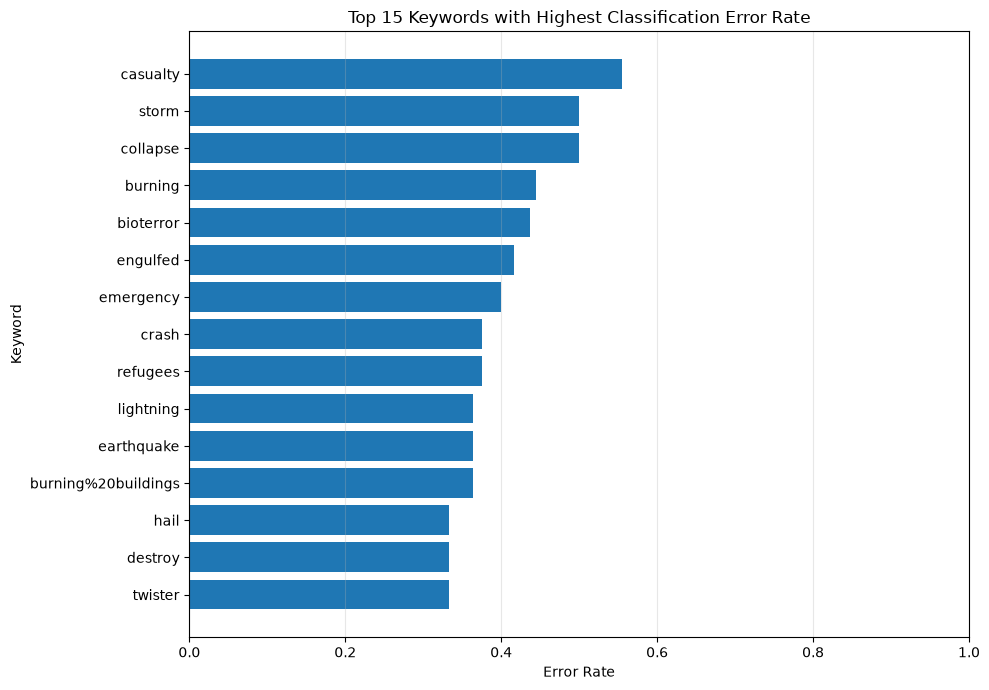

In [189]:
import matplotlib.pyplot as plt

top_errors = (
    reliable_keyword_stats
    .sort_values("error_rate", ascending=False)
    .head(15)
    .sort_values("error_rate")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_errors["keyword"],
    top_errors["error_rate"]
)

plt.xlabel("Error Rate")
plt.ylabel("Keyword")
plt.title("Top 15 Keywords with Highest Classification Error Rate")

plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [190]:
from sklearn.feature_extraction.text import TfidfVectorizer

char_tfidf = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_features=20000,
    sublinear_tf=True
)

X_train_char = char_tfidf.fit_transform(X_train)
X_test_char = char_tfidf.transform(X_test)

print("Character Training Matrix:", X_train_char.shape)
print("Character Testing Matrix:", X_test_char.shape)
print("Character Vocabulary:", len(char_tfidf.vocabulary_))

Character Training Matrix: (6124, 20000)
Character Testing Matrix: (1489, 20000)
Character Vocabulary: 20000


In [191]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

char_svm_model = LinearSVC(
    C=1.0,
    random_state=42
)

char_svm_model.fit(X_train_char, y_train)

y_pred_char = char_svm_model.predict(X_test_char)

print("Character TF-IDF + Linear SVM Results")
print("-" * 45)

print("Accuracy:", accuracy_score(y_test, y_pred_char))
print("Disaster Precision:", precision_score(y_test, y_pred_char))
print("Disaster Recall:", recall_score(y_test, y_pred_char))
print("Disaster F1:", f1_score(y_test, y_pred_char))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_char))

Character TF-IDF + Linear SVM Results
---------------------------------------------
Accuracy: 0.7978509066487576
Disaster Precision: 0.7531305903398927
Disaster Recall: 0.7208904109589042
Disaster F1: 0.73665791776028

Confusion Matrix:
[[767 138]
 [163 421]]


In [192]:
from scipy.sparse import hstack

# Combine word-level and character-level features
X_train_combined = hstack([
    X_train_tfidf,
    X_train_char
])

X_test_combined = hstack([
    X_test_tfidf,
    X_test_char
])

print("Combined Training Matrix:", X_train_combined.shape)
print("Combined Testing Matrix:", X_test_combined.shape)

Combined Training Matrix: (6124, 33722)
Combined Testing Matrix: (1489, 33722)


In [193]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

combined_svm_model = LinearSVC(
    C=1.0,
    random_state=42
)

combined_svm_model.fit(
    X_train_combined,
    y_train
)

y_pred_combined = combined_svm_model.predict(
    X_test_combined
)

print("Word + Character TF-IDF + Linear SVM")
print("-" * 45)

print("Accuracy:", accuracy_score(y_test, y_pred_combined))
print("Disaster Precision:", precision_score(y_test, y_pred_combined))
print("Disaster Recall:", recall_score(y_test, y_pred_combined))
print("Disaster F1:", f1_score(y_test, y_pred_combined))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_combined))

Word + Character TF-IDF + Linear SVM
---------------------------------------------
Accuracy: 0.8092679650772331
Disaster Precision: 0.7707581227436823
Disaster Recall: 0.7311643835616438
Disaster F1: 0.7504393673110721

Confusion Matrix:
[[778 127]
 [157 427]]


In [194]:
svm_comparison = pd.DataFrame({
    "Model": [
        "Word TF-IDF + SVM",
        "Character TF-IDF + SVM",
        "Word + Character TF-IDF + SVM"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_char),
        accuracy_score(y_test, y_pred_combined)
    ],
    "Precision": [
        precision_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_char),
        precision_score(y_test, y_pred_combined)
    ],
    "Recall": [
        recall_score(y_test, y_pred_svm),
        recall_score(y_test, y_pred_char),
        recall_score(y_test, y_pred_combined)
    ],
    "F1": [
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_char),
        f1_score(y_test, y_pred_combined)
    ]
})

display(
    svm_comparison
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

,Model,Accuracy,Precision,Recall,F1
0,Word + Character TF-IDF + SVM,0.8093,0.7708,0.7312,0.7504
1,Word TF-IDF + SVM,0.8086,0.7703,0.7295,0.7493
2,Character TF-IDF + SVM,0.7979,0.7531,0.7209,0.7367


In [195]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np

# Training data only — test set remains untouched
X_cv = X_train.reset_index(drop=True)
y_cv = y_train.reset_index(drop=True)
groups_cv = X_cv.copy()

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    sgkf.split(X_cv, y_cv, groups_cv), start=1
):
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("svm", LinearSVC(
            C=1.0,
            random_state=42
        ))
    ])

    pipeline.fit(
        X_cv.iloc[train_idx],
        y_cv.iloc[train_idx]
    )

    predictions = pipeline.predict(X_cv.iloc[val_idx])
    actual = y_cv.iloc[val_idx]

    cv_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(actual, predictions),
        "Precision": precision_score(actual, predictions, zero_division=0),
        "Recall": recall_score(actual, predictions, zero_division=0),
        "F1": f1_score(actual, predictions, zero_division=0)
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))

print("\nMean CV Scores:")
display(cv_results_df.drop(columns="Fold").mean().to_frame("Mean").round(4))

print("\nStandard Deviation:")
display(cv_results_df.drop(columns="Fold").std().to_frame("Std").round(4))

,Fold,Accuracy,Precision,Recall,F1
0,1,0.7859,0.7895,0.6983,0.7411
1,2,0.7763,0.7694,0.7007,0.7335
2,3,0.7690,0.7602,0.6909,0.7239
3,4,0.7820,0.7744,0.7095,0.7405
4,5,0.7878,0.7872,0.7082,0.7456



Mean CV Scores:


,Mean
Accuracy,0.7802
Precision,0.7761
Recall,0.7015
F1,0.7369



Standard Deviation:


,Std
Accuracy,0.0077
Precision,0.0123
Recall,0.0076
F1,0.0085


In [196]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

X_cv = X_train.reset_index(drop=True)
y_cv = y_train.reset_index(drop=True)
groups_cv = X_cv.copy()

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

combined_cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    sgkf.split(X_cv, y_cv, groups_cv), start=1
):

    combined_pipeline = Pipeline([
        ("features", FeatureUnion([
            ("word", TfidfVectorizer(
                max_features=20000,
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                sublinear_tf=True
            )),
            ("character", TfidfVectorizer(
                analyzer="char",
                ngram_range=(3, 5),
                min_df=2,
                max_features=20000,
                sublinear_tf=True
            ))
        ])),
        ("svm", LinearSVC(
            C=1.0,
            random_state=42
        ))
    ])

    combined_pipeline.fit(
        X_cv.iloc[train_idx],
        y_cv.iloc[train_idx]
    )

    predictions = combined_pipeline.predict(
        X_cv.iloc[val_idx]
    )

    actual = y_cv.iloc[val_idx]

    combined_cv_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(actual, predictions),
        "Precision": precision_score(actual, predictions),
        "Recall": recall_score(actual, predictions),
        "F1": f1_score(actual, predictions)
    })

combined_cv_df = pd.DataFrame(combined_cv_results)

print("Combined TF-IDF — Fold Results")
display(combined_cv_df.round(4))

print("\nMean CV Scores")
display(
    combined_cv_df.drop(columns="Fold")
    .mean()
    .to_frame("Mean")
    .round(4)
)

print("\nStandard Deviation")
display(
    combined_cv_df.drop(columns="Fold")
    .std()
    .to_frame("Std")
    .round(4)
)

Combined TF-IDF — Fold Results


,Fold,Accuracy,Precision,Recall,F1
0,1,0.7851,0.7878,0.6983,0.7404
1,2,0.7665,0.7603,0.6840,0.7202
2,3,0.7690,0.7480,0.7132,0.7302
3,4,0.7698,0.7525,0.7076,0.7294
4,5,0.7927,0.7806,0.7342,0.7567



Mean CV Scores


,Mean
Accuracy,0.7766
Precision,0.7659
Recall,0.7075
F1,0.7354



Standard Deviation


,Std
Accuracy,0.0116
Precision,0.0175
Recall,0.0186
F1,0.0139


In [197]:
C_values = [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]

print("Hyperparameter values to evaluate:")
print(C_values)

Hyperparameter values to evaluate:
[0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]


In [198]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

tuning_results = []

for C_value in C_values:

    fold_f1 = []
    fold_recall = []
    fold_precision = []
    fold_accuracy = []

    for train_idx, val_idx in sgkf.split(
        X_cv, y_cv, groups_cv
    ):

        pipeline = Pipeline([
            ("tfidf", TfidfVectorizer(
                max_features=20000,
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.95,
                sublinear_tf=True
            )),
            ("svm", LinearSVC(
                C=C_value,
                random_state=42
            ))
        ])

        pipeline.fit(
            X_cv.iloc[train_idx],
            y_cv.iloc[train_idx]
        )

        predictions = pipeline.predict(
            X_cv.iloc[val_idx]
        )

        actual = y_cv.iloc[val_idx]

        fold_accuracy.append(
            accuracy_score(actual, predictions)
        )
        fold_precision.append(
            precision_score(actual, predictions, zero_division=0)
        )
        fold_recall.append(
            recall_score(actual, predictions, zero_division=0)
        )
        fold_f1.append(
            f1_score(actual, predictions, zero_division=0)
        )

    tuning_results.append({
        "C": C_value,
        "Mean Accuracy": sum(fold_accuracy) / 5,
        "Mean Precision": sum(fold_precision) / 5,
        "Mean Recall": sum(fold_recall) / 5,
        "Mean F1": sum(fold_f1) / 5
    })

tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df
    .sort_values("Mean F1", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

,C,Mean Accuracy,Mean Precision,Mean Recall,Mean F1
0,0.50,0.7872,0.7951,0.6941,0.7411
1,1.00,0.7802,0.7761,0.7015,0.7369
2,0.10,0.7918,0.8349,0.6554,0.7339
3,2.00,0.7714,0.7578,0.7041,0.7300
4,5.00,0.7559,0.7300,0.7045,0.7169
5,10.00,0.7515,0.7215,0.7067,0.7139
6,0.01,0.6977,0.9355,0.3342,0.4920


In [199]:
best_C = 0.5

best_c_fold_results = []

for fold, (train_idx, val_idx) in enumerate(
    sgkf.split(X_cv, y_cv, groups_cv), start=1
):

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("svm", LinearSVC(
            C=best_C,
            random_state=42
        ))
    ])

    pipeline.fit(
        X_cv.iloc[train_idx],
        y_cv.iloc[train_idx]
    )

    predictions = pipeline.predict(X_cv.iloc[val_idx])
    actual = y_cv.iloc[val_idx]

    best_c_fold_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(actual, predictions),
        "Precision": precision_score(actual, predictions),
        "Recall": recall_score(actual, predictions),
        "F1": f1_score(actual, predictions)
    })

best_c_df = pd.DataFrame(best_c_fold_results)

print("C = 0.5 — Fold Results")
display(best_c_df.round(4))

print("\nMean:")
display(best_c_df.drop(columns="Fold").mean().to_frame("Mean").round(4))

print("\nStandard Deviation:")
display(best_c_df.drop(columns="Fold").std().to_frame("Std").round(4))

C = 0.5 — Fold Results


,Fold,Accuracy,Precision,Recall,F1
0,1,0.7949,0.8069,0.7002,0.7498
1,2,0.7829,0.7906,0.6877,0.7356
2,3,0.7763,0.7780,0.6853,0.7287
3,4,0.7869,0.7899,0.7002,0.7423
4,5,0.7951,0.8099,0.6970,0.7493



Mean:


,Mean
Accuracy,0.7872
Precision,0.7951
Recall,0.6941
F1,0.7411



Standard Deviation:


,Std
Accuracy,0.0081
Precision,0.0132
Recall,0.0071
F1,0.0090


In [200]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

final_candidate = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("svm", LinearSVC(
        C=0.5,
        random_state=42
    ))
])

final_candidate.fit(X_train, y_train)

y_pred_final = final_candidate.predict(X_test)

print("FINAL CANDIDATE — HOLDOUT TEST RESULTS")
print("-" * 50)

print("Accuracy:", accuracy_score(y_test, y_pred_final))
print("Disaster Precision:", precision_score(y_test, y_pred_final))
print("Disaster Recall:", recall_score(y_test, y_pred_final))
print("Disaster F1:", f1_score(y_test, y_pred_final))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

FINAL CANDIDATE — HOLDOUT TEST RESULTS
--------------------------------------------------
Accuracy: 0.8153122901276024
Disaster Precision: 0.7909604519774012
Disaster Recall: 0.7191780821917808
Disaster F1: 0.7533632286995515

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       905
           1       0.79      0.72      0.75       584

    accuracy                           0.82      1489
   macro avg       0.81      0.80      0.80      1489
weighted avg       0.81      0.82      0.81      1489

Confusion Matrix:
[[794 111]
 [164 420]]


In [201]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Get decision scores
y_scores = final_candidate.decision_function(X_test)

thresholds = [-0.5, -0.25, 0.0, 0.25, 0.5]

threshold_results = []

for threshold in thresholds:

    predictions = (y_scores >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "False Positives": (
            ((y_test == 0) & (predictions == 1)).sum()
        ),
        "False Negatives": (
            ((y_test == 1) & (predictions == 0)).sum()
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1,False Positives,False Negatives
0,-0.50,0.5694,0.9058,0.6993,400,55
1,-0.25,0.6760,0.8288,0.7446,232,100
2,0.00,0.7910,0.7192,0.7534,111,164
3,0.25,0.8633,0.6164,0.7193,57,224
4,0.50,0.9300,0.4777,0.6312,21,305


In [202]:
import numpy as np
import pandas as pd

oof_scores = np.full(len(X_cv), np.nan)
oof_actual = y_cv.to_numpy()

for train_idx, val_idx in sgkf.split(
    X_cv, y_cv, groups_cv
):

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("svm", LinearSVC(
            C=0.5,
            random_state=42
        ))
    ])

    pipeline.fit(
        X_cv.iloc[train_idx],
        y_cv.iloc[train_idx]
    )

    oof_scores[val_idx] = pipeline.decision_function(
        X_cv.iloc[val_idx]
    )

print("Validation scores generated:", np.isfinite(oof_scores).sum())
print("Total training rows:", len(oof_scores))
print("Missing scores:", np.isnan(oof_scores).sum())

Validation scores generated: 6124
Total training rows: 6124
Missing scores: 0


In [203]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = np.arange(-0.50, 0.51, 0.05)

oof_threshold_results = []

for threshold in thresholds:

    predictions = (oof_scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        oof_actual,
        predictions,
        labels=[0, 1]
    ).ravel()

    oof_threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            oof_actual, predictions, zero_division=0
        ),
        "Recall": recall_score(
            oof_actual, predictions, zero_division=0
        ),
        "F1": f1_score(
            oof_actual, predictions, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn
    })

oof_threshold_df = pd.DataFrame(oof_threshold_results)

display(
    oof_threshold_df
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

,Threshold,Precision,Recall,F1,False Positives,False Negatives
0,-0.05,0.7727,0.7175,0.7441,567,759
1,-0.10,0.7492,0.7373,0.7432,663,706
2,-0.00,0.7950,0.6941,0.7411,481,822
3,-0.20,0.7032,0.7812,0.7401,886,588
4,-0.15,0.7219,0.7574,0.7392,784,652
5,-0.25,0.6787,0.8028,0.7355,1021,530
6,0.05,0.8144,0.6680,0.7340,409,892
7,-0.30,0.6590,0.8214,0.7313,1142,480
8,-0.35,0.6373,0.8429,0.7258,1289,422
9,0.10,0.8320,0.6379,0.7221,346,973


In [204]:
FINAL_C = 0.5
FINAL_THRESHOLD = -0.05

print("Selected Model: Word TF-IDF + Linear SVM")
print("Selected C:", FINAL_C)
print("Selected Threshold:", FINAL_THRESHOLD)

selected_oof_predictions = (
    oof_scores >= FINAL_THRESHOLD
).astype(int)

print("\nSelected OOF Performance:")
print("Precision:", precision_score(
    oof_actual, selected_oof_predictions
))
print("Recall:", recall_score(
    oof_actual, selected_oof_predictions
))
print("F1:", f1_score(
    oof_actual, selected_oof_predictions
))

Selected Model: Word TF-IDF + Linear SVM
Selected C: 0.5
Selected Threshold: -0.05

Selected OOF Performance:
Precision: 0.7727454909819639
Recall: 0.7175288425753629
F1: 0.7441142416055577


In [205]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

crisisproof_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("svm", LinearSVC(
        C=0.5,
        random_state=42
    ))
])

# Train on training data only
crisisproof_model.fit(X_train, y_train)

print("CRISISPROOF model training completed.")
print("Vocabulary size:", len(
    crisisproof_model.named_steps["tfidf"].vocabulary_
))
print("Selected threshold:", FINAL_THRESHOLD)

CRISISPROOF model training completed.
Vocabulary size: 13722
Selected threshold: -0.05


In [206]:
import joblib

# Save model and configuration together
crisisproof_artifact = {
    "model": crisisproof_model,
    "threshold": FINAL_THRESHOLD,
    "model_name": "CRISISPROOF Word TF-IDF + Linear SVM",
    "model_version": "1.0",
    "training_rows": len(X_train),
    "vocabulary_size": len(
        crisisproof_model.named_steps["tfidf"].vocabulary_
    )
}

joblib.dump(
    crisisproof_artifact,
    "crisisproof_model_v1.joblib"
)

print("Model artifact saved successfully!")
print("File: crisisproof_model_v1.joblib")

Model artifact saved successfully!
File: crisisproof_model_v1.joblib


In [207]:
def predict_crisis(tweet):

    # Clean incoming tweet
    cleaned_tweet = clean_tweet(tweet)

    # Get model decision score
    decision_score = crisisproof_model.decision_function(
        [cleaned_tweet]
    )[0]

    # Apply selected threshold
    prediction = int(
        decision_score >= FINAL_THRESHOLD
    )

    result = {
        "original_tweet": tweet,
        "cleaned_tweet": cleaned_tweet,
        "prediction": prediction,
        "classification": (
            "Disaster-related"
            if prediction == 1
            else "Non-disaster"
        ),
        "decision_score": round(float(decision_score), 4),
        "threshold": FINAL_THRESHOLD
    }

    return result


print("CRISISPROOF Prediction Engine Ready!")

CRISISPROOF Prediction Engine Ready!


In [208]:
sample_tweet = (
    "Breaking: Severe flooding reported "
    "in several areas after heavy rainfall."
)

result = predict_crisis(sample_tweet)

for key, value in result.items():
    print(f"{key}: {value}")

original_tweet: Breaking: Severe flooding reported in several areas after heavy rainfall.
cleaned_tweet: breaking: severe flooding reported in several areas after heavy rainfall.
prediction: 1
classification: Disaster-related
decision_score: 1.4389
threshold: -0.05


In [209]:
def predict_crisis(tweet):

    if not isinstance(tweet, str):
        raise TypeError("Tweet must be a string.")

    if not tweet.strip():
        raise ValueError("Tweet cannot be empty.")

    cleaned_tweet = clean_tweet(tweet)

    decision_score = crisisproof_model.decision_function(
        [cleaned_tweet]
    )[0]

    prediction = int(decision_score >= FINAL_THRESHOLD)

    return {
        "original_tweet": tweet,
        "cleaned_tweet": cleaned_tweet,
        "prediction": prediction,
        "classification": (
            "Disaster-related"
            if prediction == 1
            else "Non-disaster"
        ),
        "decision_score": round(float(decision_score), 4),
        "threshold": FINAL_THRESHOLD
    }


print("Robust CRISISPROOF Prediction Engine Ready!")

Robust CRISISPROOF Prediction Engine Ready!


In [210]:
test_tweets = [
    "Breaking: A massive earthquake has destroyed several buildings.",
    "I love spending time with my friends on weekends.",
    "Heavy rainfall has caused severe flooding in the city."
]

for tweet in test_tweets:
    result = predict_crisis(tweet)

    print("-" * 60)
    print("Tweet:", result["original_tweet"])
    print("Prediction:", result["prediction"])
    print("Classification:", result["classification"])
    print("Decision Score:", result["decision_score"])

------------------------------------------------------------
Tweet: Breaking: A massive earthquake has destroyed several buildings.
Prediction: 1
Classification: Disaster-related
Decision Score: 1.0457
------------------------------------------------------------
Tweet: I love spending time with my friends on weekends.
Prediction: 0
Classification: Non-disaster
Decision Score: -0.7382
------------------------------------------------------------
Tweet: Heavy rainfall has caused severe flooding in the city.
Prediction: 1
Classification: Disaster-related
Decision Score: 1.0395


In [211]:
# Test invalid inputs

invalid_inputs = [
    None,
    "",
    "     ",
    123
]

for value in invalid_inputs:
    try:
        result = predict_crisis(value)
        print("Unexpected success:", result)

    except (TypeError, ValueError) as error:
        print(type(error).__name__, ":", error)

TypeError : Tweet must be a string.
ValueError : Tweet cannot be empty.
ValueError : Tweet cannot be empty.
TypeError : Tweet must be a string.


In [212]:
import joblib
import os

artifact_path = "crisisproof_model_v1.joblib"

print("Artifact exists:", os.path.exists(artifact_path))

loaded_artifact = joblib.load(artifact_path)

loaded_model = loaded_artifact["model"]
loaded_threshold = loaded_artifact["threshold"]

print("Model Name:", loaded_artifact["model_name"])
print("Model Version:", loaded_artifact["model_version"])
print("Training Rows:", loaded_artifact["training_rows"])
print("Vocabulary Size:", loaded_artifact["vocabulary_size"])
print("Loaded Threshold:", loaded_threshold)

print("\nModel artifact loaded successfully!")

Artifact exists: True
Model Name: CRISISPROOF Word TF-IDF + Linear SVM
Model Version: 1.0
Training Rows: 6124
Vocabulary Size: 13722
Loaded Threshold: -0.05

Model artifact loaded successfully!


In [213]:
sample_tweet = (
    "Breaking: A massive earthquake has destroyed several buildings."
)

cleaned_tweet = clean_tweet(sample_tweet)

# Original model prediction
original_score = crisisproof_model.decision_function(
    [cleaned_tweet]
)[0]

original_prediction = int(
    original_score >= FINAL_THRESHOLD
)

# Reloaded model prediction
loaded_score = loaded_model.decision_function(
    [cleaned_tweet]
)[0]

loaded_prediction = int(
    loaded_score >= loaded_threshold
)

print("Original Model Prediction:", original_prediction)
print("Loaded Model Prediction:", loaded_prediction)

print("Original Decision Score:", round(float(original_score), 6))
print("Loaded Decision Score:", round(float(loaded_score), 6))

print(
    "\nPrediction Match:",
    original_prediction == loaded_prediction
)

print(
    "Score Match:",
    abs(original_score - loaded_score) < 1e-10
)

Original Model Prediction: 1
Loaded Model Prediction: 1
Original Decision Score: 1.045735
Loaded Decision Score: 1.045735

Prediction Match: True
Score Match: True


In [214]:
import pytest

print("Pytest version:", pytest.__version__)
print("Automated testing environment ready!")

Pytest version: 9.0.3
Automated testing environment ready!


In [215]:
def test_disaster_prediction():
    result = predict_crisis(
        "A massive earthquake has destroyed several buildings."
    )
    assert result["prediction"] == 1


def test_non_disaster_prediction():
    result = predict_crisis(
        "I love spending time with my friends."
    )
    assert result["prediction"] == 0


def test_empty_input():
    with pytest.raises(ValueError):
        predict_crisis("")


def test_none_input():
    with pytest.raises(TypeError):
        predict_crisis(None)


def test_loaded_model_consistency():
    tweet = "A massive earthquake has destroyed several buildings."
    cleaned = clean_tweet(tweet)

    original_score = crisisproof_model.decision_function([cleaned])[0]
    loaded_score = loaded_model.decision_function([cleaned])[0]

    assert abs(original_score - loaded_score) < 1e-10


print("5 CRISISPROOF test functions defined successfully!")

5 CRISISPROOF test functions defined successfully!


In [216]:
test_functions = [
    test_disaster_prediction,
    test_non_disaster_prediction,
    test_empty_input,
    test_none_input,
    test_loaded_model_consistency
]

passed = 0
failed = 0

for test in test_functions:
    try:
        test()
        print(f"PASSED: {test.__name__}")
        passed += 1

    except Exception as error:
        print(f"FAILED: {test.__name__}")
        print("Error:", error)
        failed += 1

print("\n========== TEST SUMMARY ==========")
print("Total Tests:", len(test_functions))
print("Passed:", passed)
print("Failed:", failed)

PASSED: test_disaster_prediction
PASSED: test_non_disaster_prediction
PASSED: test_empty_input
PASSED: test_none_input
PASSED: test_loaded_model_consistency

========== TEST SUMMARY ==========
Total Tests: 5
Passed: 5
Failed: 0


In [217]:
from pathlib import Path

project_dirs = [
    "CRISISPROOF",
    "CRISISPROOF/data",
    "CRISISPROOF/models",
    "CRISISPROOF/src",
    "CRISISPROOF/tests",
    "CRISISPROOF/notebooks"
]

for directory in project_dirs:
    Path(directory).mkdir(parents=True, exist_ok=True)
    print("Created:", directory)

print("\nCRISISPROOF project structure initialized!")

Created: CRISISPROOF
Created: CRISISPROOF/data
Created: CRISISPROOF/models
Created: CRISISPROOF/src
Created: CRISISPROOF/tests
Created: CRISISPROOF/notebooks

CRISISPROOF project structure initialized!


In [218]:
from pathlib import Path

preprocessing_code = '''
import re
import html


def clean_tweet(text):
    text = html.unescape(str(text))

    text = re.sub(
        r"_x0089_Ûª(?=(s|t|re|ve|ll|d|m)\\\\b)",
        "'",
        text
    )

    text = re.sub(r"_x[0-9A-Fa-f]{4}_", " ", text)
    text = re.sub(r"Û.", " ", text)

    text = re.sub(
        r"https?://\\\\S+|www\\\\.\\\\S+",
        " ",
        text
    )

    corrections = {
        "åÊ": " ",
        "å£": "£",
        "donå«t": "don't",
        "SuruÌ¤": "Suruç",
        "IRONMANå¨": "IRONMAN®",
        "JapÌ_n": "Japan",
        "vÌ_deo": "vídeo",
        "RÌ©": "Ré",
        "Ì©": "é",
        "Ì¼": "ú",
        "å©Daniel": "©Daniel"
    }

    for old, new in corrections.items():
        text = text.replace(old, new)

    text = re.sub(r"(\\\\d+)å¡([FC])", r"\\\\1°\\\\2", text)

    text = text.replace("#", "")
    text = re.sub(r"@\\\\w+", " ", text)

    text = text.lower()
    text = re.sub(r"\\\\s+", " ", text).strip()

    return text
'''

file_path = Path("CRISISPROOF/src/preprocessing.py")
file_path.write_text(preprocessing_code.strip() + "\n", encoding="utf-8")

print("preprocessing.py created successfully!")
print("File location:", file_path)

preprocessing.py created successfully!
File location: CRISISPROOF\src\preprocessing.py


In [219]:
import sys
from pathlib import Path

src_path = str(Path("CRISISPROOF/src").resolve())

if src_path not in sys.path:
    sys.path.insert(0, src_path)

from preprocessing import clean_tweet as module_clean_tweet

sample = "Breaking: Severe flooding reported in several areas after heavy rainfall."

notebook_output = clean_tweet(sample)
module_output = module_clean_tweet(sample)

print("Notebook output:", notebook_output)
print("Module output:  ", module_output)
print("Outputs match:", notebook_output == module_output)

Notebook output: breaking: severe flooding reported in several areas after heavy rainfall.
Module output:   breaking: severe flooding reported in several areas after heavy rainfall.
Outputs match: True


In [220]:
predictor_code = '''
import joblib
from pathlib import Path

from preprocessing import clean_tweet


class CrisisPredictor:

    def __init__(self, model_path):
        model_path = Path(model_path)

        if not model_path.exists():
            raise FileNotFoundError(
                f"Model artifact not found: {model_path}"
            )

        artifact = joblib.load(model_path)

        self.model = artifact["model"]
        self.threshold = artifact["threshold"]
        self.model_name = artifact["model_name"]
        self.model_version = artifact["model_version"]

    def predict(self, tweet):

        if not isinstance(tweet, str):
            raise TypeError("Tweet must be a string.")

        if not tweet.strip():
            raise ValueError("Tweet cannot be empty.")

        cleaned_tweet = clean_tweet(tweet)

        decision_score = self.model.decision_function(
            [cleaned_tweet]
        )[0]

        prediction = int(
            decision_score >= self.threshold
        )

        return {
            "original_tweet": tweet,
            "cleaned_tweet": cleaned_tweet,
            "prediction": prediction,
            "classification": (
                "Disaster-related"
                if prediction == 1
                else "Non-disaster"
            ),
            "decision_score": round(
                float(decision_score), 4
            ),
            "threshold": self.threshold,
            "model_version": self.model_version
        }
'''

predictor_path = Path("CRISISPROOF/src/predictor.py")
predictor_path.write_text(
    predictor_code.strip() + "\\n",
    encoding="utf-8"
)

print("predictor.py created successfully!")

predictor.py created successfully!


In [223]:
from pathlib import Path

predictor_code = r'''
import joblib
from pathlib import Path

from preprocessing import clean_tweet


class CrisisPredictor:

    def __init__(self, model_path):
        model_path = Path(model_path)

        if not model_path.exists():
            raise FileNotFoundError(
                f"Model artifact not found: {model_path}"
            )

        artifact = joblib.load(model_path)

        self.model = artifact["model"]
        self.threshold = artifact["threshold"]
        self.model_name = artifact["model_name"]
        self.model_version = artifact["model_version"]

    def predict(self, tweet):

        if not isinstance(tweet, str):
            raise TypeError("Tweet must be a string.")

        if not tweet.strip():
            raise ValueError("Tweet cannot be empty.")

        cleaned_tweet = clean_tweet(tweet)

        decision_score = self.model.decision_function(
            [cleaned_tweet]
        )[0]

        prediction = int(
            decision_score >= self.threshold
        )

        return {
            "original_tweet": tweet,
            "cleaned_tweet": cleaned_tweet,
            "prediction": prediction,
            "classification": (
                "Disaster-related"
                if prediction == 1
                else "Non-disaster"
            ),
            "decision_score": round(float(decision_score), 4),
            "threshold": self.threshold,
            "model_version": self.model_version
        }
'''

predictor_path = Path("CRISISPROOF/src/predictor.py")
predictor_path.write_text(predictor_code.strip() + "\n", encoding="utf-8")

# Verify Python syntax before importing
compile(predictor_path.read_text(encoding="utf-8"), str(predictor_path), "exec")

print("predictor.py fixed successfully!")
print("Python syntax validation: PASSED")

predictor.py fixed successfully!
Python syntax validation: PASSED


In [225]:
from pathlib import Path
import shutil

source_model = Path("crisisproof_model_v1.joblib")
destination_model = Path("CRISISPROOF/models/crisisproof_model_v1.joblib")

if not source_model.exists():
    raise FileNotFoundError(f"Original model missing: {source_model.resolve()}")

shutil.copy2(source_model, destination_model)

print("Model copied successfully!")
print("Destination:", destination_model.resolve())
print("File exists:", destination_model.exists())

Model copied successfully!
Destination: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\models\crisisproof_model_v1.joblib
File exists: True


In [226]:
import importlib
import predictor

importlib.reload(predictor)

CrisisPredictor = predictor.CrisisPredictor

MODEL_PATH = Path("CRISISPROOF/models/crisisproof_model_v1.joblib")

crisis_engine = CrisisPredictor(MODEL_PATH)

print("CRISISPROOF Prediction Engine Loaded!")
print("Model:", crisis_engine.model_name)
print("Version:", crisis_engine.model_version)

CRISISPROOF Prediction Engine Loaded!
Model: CRISISPROOF Word TF-IDF + Linear SVM
Version: 1.0


In [227]:
test_tweets = [
    "A massive earthquake has destroyed several buildings.",
    "I love spending time with my friends on weekends.",
    "Heavy rainfall has caused severe flooding in the city."
]

for tweet in test_tweets:

    result = crisis_engine.predict(tweet)

    print("-" * 60)
    print("Tweet:", result["original_tweet"])
    print("Classification:", result["classification"])
    print("Prediction:", result["prediction"])
    print("Decision Score:", result["decision_score"])
    print("Model Version:", result["model_version"])

------------------------------------------------------------
Tweet: A massive earthquake has destroyed several buildings.
Classification: Disaster-related
Prediction: 1
Decision Score: 0.9375
Model Version: 1.0
------------------------------------------------------------
Tweet: I love spending time with my friends on weekends.
Classification: Non-disaster
Prediction: 0
Decision Score: -0.7382
Model Version: 1.0
------------------------------------------------------------
Tweet: Heavy rainfall has caused severe flooding in the city.
Classification: Disaster-related
Prediction: 1
Decision Score: 1.0395
Model Version: 1.0


In [228]:
test_code = '''
import pytest
from pathlib import Path
import sys

PROJECT_ROOT = Path(__file__).resolve().parents[1]
SRC_PATH = PROJECT_ROOT / "src"

sys.path.insert(0, str(SRC_PATH))

from predictor import CrisisPredictor

MODEL_PATH = PROJECT_ROOT / "models" / "crisisproof_model_v1.joblib"


@pytest.fixture
def engine():
    return CrisisPredictor(MODEL_PATH)


def test_disaster_prediction(engine):
    result = engine.predict(
        "A massive earthquake has destroyed several buildings."
    )
    assert result["prediction"] == 1


def test_non_disaster_prediction(engine):
    result = engine.predict(
        "I love spending time with my friends."
    )
    assert result["prediction"] == 0


def test_empty_input(engine):
    with pytest.raises(ValueError):
        engine.predict("")


def test_none_input(engine):
    with pytest.raises(TypeError):
        engine.predict(None)


def test_model_version(engine):
    assert engine.model_version == "1.0"
'''

test_path = Path("CRISISPROOF/tests/test_predictor.py")
test_path.write_text(test_code.strip() + "\n", encoding="utf-8")

print("test_predictor.py created successfully!")

test_predictor.py created successfully!


In [229]:
import subprocess
import sys

project_path = Path("CRISISPROOF").resolve()

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        str(project_path / "tests" / "test_predictor.py"),
        "-v"
    ],
    cwd=str(project_path),
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("ERROR OUTPUT:")
    print(result.stderr)

print("Pytest exit code:", result.returncode)

============================= test session starts =============================
platform win32 -- Python 3.14.6, pytest-9.0.3, pluggy-1.6.0 -- C:\Users\Anish kumar tiwari\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF
plugins: anyio-4.12.1
collecting ... collected 5 items

tests/test_predictor.py::test_disaster_prediction PASSED                 [ 20%]
tests/test_predictor.py::test_non_disaster_prediction PASSED             [ 40%]
tests/test_predictor.py::test_empty_input PASSED                         [ 60%]
tests/test_predictor.py::test_none_input PASSED                          [ 80%]
tests/test_predictor.py::test_model_version PASSED                       [100%]

============================== 5 passed in 3.59s ==============================

Pytest exit code: 0


In [230]:
from pathlib import Path

init_path = Path("CRISISPROOF/src/__init__.py")

init_path.write_text(
    '"""CRISISPROOF core source package."""\n',
    encoding="utf-8"
)

print("__init__.py created successfully!")

__init__.py created successfully!


In [231]:
requirements = """
pandas
numpy
scikit-learn
joblib
pytest
openpyxl
"""

requirements_path = Path("CRISISPROOF/requirements.txt")

requirements_path.write_text(
    requirements.strip() + "\n",
    encoding="utf-8"
)

print("requirements.txt created successfully!")
print("\nProject dependencies:")
print(requirements)

requirements.txt created successfully!

Project dependencies:

pandas
numpy
scikit-learn
joblib
pytest
openpyxl



In [232]:
readme = """
# CRISISPROOF Ω∞
### Crisis Intelligence Platform

CRISISPROOF is an AI-powered crisis intelligence prototype
that classifies text messages as disaster-related or non-disaster.

## Current ML Pipeline

- Text preprocessing
- Word-level TF-IDF feature extraction
- Linear Support Vector Machine classification
- Configurable decision threshold
- Saved model artifact
- Input validation
- Automated testing with pytest

## Project Structure

CRISISPROOF/
├── data/
├── models/
├── src/
│   ├── __init__.py
│   ├── preprocessing.py
│   └── predictor.py
├── tests/
│   └── test_predictor.py
├── notebooks/
└── requirements.txt

## Installation

Install dependencies:

pip install -r requirements.txt

## Run Tests

python -m pytest tests/ -v

## Model Information

- Algorithm: Linear SVM
- Feature extraction: Word TF-IDF
- Training rows: 6124
- Vocabulary size: 13722
- Model version: 1.0
- Decision threshold: -0.05

## Important Limitations

This is a historical-dataset-based prototype.
It does not currently provide verified live crisis monitoring,
real-time evidence retrieval, or operational emergency predictions.

Model outputs require human review.
"""

readme_path = Path("CRISISPROOF/README.md")

readme_path.write_text(
    readme.strip() + "\n",
    encoding="utf-8"
)

print("README.md created successfully!")
print("Location:", readme_path.resolve())

README.md created successfully!
Location: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\README.md


In [233]:
from pathlib import Path

project_root = Path("CRISISPROOF")

for path in sorted(project_root.rglob("*")):
    if path.is_file():
        print("FILE  :", path.relative_to(project_root))
    else:
        print("FOLDER:", path.relative_to(project_root))

print("\nTotal files:", sum(1 for p in project_root.rglob("*") if p.is_file()))

FOLDER: .pytest_cache
FILE  : .pytest_cache\.gitignore
FILE  : .pytest_cache\CACHEDIR.TAG
FILE  : .pytest_cache\README.md
FOLDER: .pytest_cache\v
FOLDER: .pytest_cache\v\cache
FILE  : .pytest_cache\v\cache\nodeids
FOLDER: data
FOLDER: models
FILE  : models\crisisproof_model_v1.joblib
FOLDER: notebooks
FILE  : README.md
FILE  : requirements.txt
FOLDER: src
FILE  : src\__init__.py
FOLDER: src\__pycache__
FILE  : src\__pycache__\predictor.cpython-314.pyc
FILE  : src\__pycache__\preprocessing.cpython-314.pyc
FILE  : src\predictor.py
FILE  : src\preprocessing.py
FOLDER: tests
FOLDER: tests\__pycache__
FILE  : tests\__pycache__\test_predictor.cpython-314-pytest-9.0.3.pyc
FILE  : tests\test_predictor.py

Total files: 14


In [234]:
gitignore_content = """
# Python cache
__pycache__/
*.py[cod]

# Testing
.pytest_cache/
.coverage
htmlcov/

# Virtual environments
venv/
.venv/
env/

# Jupyter
.ipynb_checkpoints/

# Environment variables
.env

# OS files
.DS_Store
Thumbs.db
"""

gitignore_path = Path("CRISISPROOF/.gitignore")

gitignore_path.write_text(
    gitignore_content.strip() + "\n",
    encoding="utf-8"
)

print(".gitignore created successfully!")

.gitignore created successfully!


In [235]:
print("NOTEBOOK MODEL")
print("Vocabulary size:",
      len(crisisproof_model.named_steps["tfidf"].vocabulary_))

print("\nLOADED MODEL")
print("Vocabulary size:",
      len(loaded_model.named_steps["tfidf"].vocabulary_))

print("\nMODEL COMPARISON")
print(
    "Vocabulary identical:",
    crisisproof_model.named_steps["tfidf"].vocabulary_
    == loaded_model.named_steps["tfidf"].vocabulary_
)

print(
    "SVM coefficients identical:",
    (crisisproof_model.named_steps["svm"].coef_
     == loaded_model.named_steps["svm"].coef_).all()
)

NOTEBOOK MODEL
Vocabulary size: 13722

LOADED MODEL
Vocabulary size: 13722

MODEL COMPARISON
Vocabulary identical: True
SVM coefficients identical: True


In [236]:
earthquake_tweet = (
    "A massive earthquake has destroyed several buildings."
)

notebook_cleaned = clean_tweet(earthquake_tweet)
module_cleaned = module_clean_tweet(earthquake_tweet)

print("Notebook cleaned text:")
print(repr(notebook_cleaned))

print("\nModule cleaned text:")
print(repr(module_cleaned))

print("\nCleaned text identical:",
      notebook_cleaned == module_cleaned)

print("\nNotebook score:",
      crisisproof_model.decision_function([notebook_cleaned])[0])

print("\nLoaded model score:",
      loaded_model.decision_function([module_cleaned])[0])

Notebook cleaned text:
'a massive earthquake has destroyed several buildings.'

Module cleaned text:
'a massive earthquake has destroyed several buildings.'

Cleaned text identical: True

Notebook score: 0.9375295362302143

Loaded model score: 0.9375295362302143


In [237]:
from pathlib import Path

notebook_files = list(Path.cwd().glob("*.ipynb"))

print("Available notebooks:")

for i, file in enumerate(notebook_files):
    print(i, ":", file.name)

Available notebooks:
0 : ml practice.ipynb
1 : ml1.ipynb
2 : Rossmann_Sales_Forecasting.ipynb
3 : TellCo.ipynb
4 : TellCo_Telecom_Customer_Analysis.ipynb
5 : Untitled.ipynb
6 : Untitled1.ipynb


In [238]:
from pathlib import Path
import shutil

source = Path("CRISISPROOF_ML_Experimentation.ipynb")
destination = Path("CRISISPROOF/notebooks") / source.name

if source.exists():
    shutil.copy2(source, destination)
    print("Notebook copied successfully!")
    print("Destination:", destination.resolve())
else:
    print("Notebook not found. Check its exact filename.")

Notebook copied successfully!
Destination: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\notebooks\CRISISPROOF_ML_Experimentation.ipynb


In [239]:
from pathlib import Path

project_root = Path("CRISISPROOF")

required_files = [
    "README.md",
    "requirements.txt",
    ".gitignore",
    "models/crisisproof_model_v1.joblib",
    "src/__init__.py",
    "src/preprocessing.py",
    "src/predictor.py",
    "tests/test_predictor.py",
    "notebooks/CRISISPROOF_ML_Experimentation.ipynb"
]

for file in required_files:
    path = project_root / file
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{status}: {file}")

print("\nProject root:", project_root.resolve())

FOUND: README.md
FOUND: requirements.txt
FOUND: .gitignore
FOUND: models/crisisproof_model_v1.joblib
FOUND: src/__init__.py
FOUND: src/preprocessing.py
FOUND: src/predictor.py
FOUND: tests/test_predictor.py
FOUND: notebooks/CRISISPROOF_ML_Experimentation.ipynb

Project root: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF


In [240]:

from importlib.metadata import version
from pathlib import Path

packages = [
    "pandas",
    "numpy",
    "scikit-learn",
    "joblib",
    "pytest",
    "openpyxl"
]

requirements = []

for package in packages:
    installed_version = version(package)
    requirements.append(
        f"{package}=={installed_version}"
    )
    print(f"{package}: {installed_version}")

requirements_path = Path("CRISISPROOF/requirements.txt")

requirements_path.write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

print("\nPinned requirements.txt created successfully!")

pandas: 3.0.3
numpy: 2.4.6
scikit-learn: 1.9.0
joblib: 1.5.3
pytest: 9.0.3
openpyxl: 3.1.5

Pinned requirements.txt created successfully!


In [241]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print(result.stderr)

print("Dependency check exit code:", result.returncode)

No broken requirements found.

Dependency check exit code: 0


In [242]:
import subprocess
import sys
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        str(project_root / "tests"),
        "-v"
    ],
    cwd=str(project_root),
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print(result.stderr)

print("Exit code:", result.returncode)

============================= test session starts =============================
platform win32 -- Python 3.14.6, pytest-9.0.3, pluggy-1.6.0 -- C:\Users\Anish kumar tiwari\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF
plugins: anyio-4.12.1
collecting ... collected 5 items

tests/test_predictor.py::test_disaster_prediction PASSED                 [ 20%]
tests/test_predictor.py::test_non_disaster_prediction PASSED             [ 40%]
tests/test_predictor.py::test_empty_input PASSED                         [ 60%]
tests/test_predictor.py::test_none_input PASSED                          [ 80%]
tests/test_predictor.py::test_model_version PASSED                       [100%]

============================== 5 passed in 2.04s ==============================

Exit code: 0


In [243]:
%pip install fastapi uvicorn


Note: you may need to restart the kernel to use updated packages.


In [244]:
from importlib.metadata import version
from pathlib import Path

packages = [
    "pandas",
    "numpy",
    "scikit-learn",
    "joblib",
    "pytest",
    "openpyxl",
    "fastapi",
    "uvicorn"
]

requirements = []

for package in packages:
    installed_version = version(package)
    requirements.append(f"{package}=={installed_version}")
    print(f"{package}: {installed_version}")

requirements_path = Path("CRISISPROOF/requirements.txt")

requirements_path.write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

print("\nFastAPI dependencies added successfully!")

pandas: 3.0.3
numpy: 2.4.6
scikit-learn: 1.9.0
joblib: 1.5.3
pytest: 9.0.3
openpyxl: 3.1.5
fastapi: 0.141.1
uvicorn: 0.40.0

FastAPI dependencies added successfully!


In [245]:
from pathlib import Path

api_code = '''
from fastapi import FastAPI

app = FastAPI(
    title="CRISISPROOF API",
    description="AI-powered Crisis Intelligence Platform",
    version="1.0.0"
)


@app.get("/")
def root():
    return {
        "project": "CRISISPROOF",
        "message": "Crisis Intelligence API is running",
        "version": "1.0.0"
    }


@app.get("/health")
def health_check():
    return {
        "status": "healthy",
        "service": "CRISISPROOF API"
    }
'''

api_path = Path("CRISISPROOF/src/api.py")

api_path.write_text(
    api_code.strip() + "\n",
    encoding="utf-8"
)

print("api.py created successfully!")

api.py created successfully!


In [246]:
import sys
from pathlib import Path

from fastapi.testclient import TestClient

src_path = str(Path("CRISISPROOF/src").resolve())

if src_path not in sys.path:
    sys.path.insert(0, src_path)

from api import app

client = TestClient(app)

# Test root endpoint
root_response = client.get("/")

print("ROOT ENDPOINT")
print("Status:", root_response.status_code)
print("Response:", root_response.json())

# Test health endpoint
health_response = client.get("/health")

print("\nHEALTH ENDPOINT")
print("Status:", health_response.status_code)
print("Response:", health_response.json())

ROOT ENDPOINT
Status: 200
Response: {'project': 'CRISISPROOF', 'message': 'Crisis Intelligence API is running', 'version': '1.0.0'}

HEALTH ENDPOINT
Status: 200
Response: {'status': 'healthy', 'service': 'CRISISPROOF API'}


In [247]:
api_code = '''
from pathlib import Path

from fastapi import FastAPI
from pydantic import BaseModel, Field

from predictor import CrisisPredictor


PROJECT_ROOT = Path(__file__).resolve().parents[1]

MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "crisisproof_model_v1.joblib"
)

crisis_engine = CrisisPredictor(MODEL_PATH)


app = FastAPI(
    title="CRISISPROOF API",
    description="AI-powered Crisis Intelligence Platform",
    version="1.0.0"
)


class PredictionRequest(BaseModel):
    tweet: str = Field(min_length=1)


@app.get("/")
def root():
    return {
        "project": "CRISISPROOF",
        "message": "Crisis Intelligence API is running",
        "version": "1.0.0"
    }


@app.get("/health")
def health_check():
    return {
        "status": "healthy",
        "service": "CRISISPROOF API",
        "model_loaded": crisis_engine is not None
    }


@app.post("/predict")
def predict_crisis(request: PredictionRequest):
    result = crisis_engine.predict(request.tweet)
    return result
'''

api_path = Path("CRISISPROOF/src/api.py")

api_path.write_text(
    api_code.strip() + "\\n",
    encoding="utf-8"
)

print("CRISISPROOF API updated with /predict endpoint!")

CRISISPROOF API updated with /predict endpoint!


In [249]:
from pathlib import Path

api_code = r'''
from pathlib import Path

from fastapi import FastAPI
from pydantic import BaseModel, Field

from predictor import CrisisPredictor


PROJECT_ROOT = Path(__file__).resolve().parents[1]

MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "crisisproof_model_v1.joblib"
)

crisis_engine = CrisisPredictor(MODEL_PATH)


app = FastAPI(
    title="CRISISPROOF API",
    description="AI-powered Crisis Intelligence Platform",
    version="1.0.0"
)


class PredictionRequest(BaseModel):
    tweet: str = Field(min_length=1)


@app.get("/")
def root():
    return {
        "project": "CRISISPROOF",
        "message": "Crisis Intelligence API is running",
        "version": "1.0.0"
    }


@app.get("/health")
def health_check():
    return {
        "status": "healthy",
        "service": "CRISISPROOF API",
        "model_loaded": crisis_engine is not None
    }


@app.post("/predict")
def predict_crisis(request: PredictionRequest):
    result = crisis_engine.predict(request.tweet)
    return result
'''

api_file = Path("CRISISPROOF/src/api.py")

api_file.write_text(
    api_code.strip() + "\n",
    encoding="utf-8"
)

# Syntax validation
compile(
    api_file.read_text(encoding="utf-8"),
    str(api_file),
    "exec"
)

print("api.py fixed successfully!")
print("Python syntax validation: PASSED")

api.py fixed successfully!
Python syntax validation: PASSED


In [250]:
import sys
import importlib
from pathlib import Path
from fastapi.testclient import TestClient

src_path = Path("CRISISPROOF/src").resolve()

if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

import api
importlib.reload(api)

client = TestClient(api.app)

# Test 1: Disaster tweet
disaster_response = client.post(
    "/predict",
    json={
        "tweet": "A massive earthquake has destroyed several buildings."
    }
)

print("DISASTER API TEST")
print("Status:", disaster_response.status_code)
print("Response:", disaster_response.json())

# Test 2: Non-disaster tweet
normal_response = client.post(
    "/predict",
    json={
        "tweet": "I love spending time with my friends."
    }
)

print("\nNON-DISASTER API TEST")
print("Status:", normal_response.status_code)
print("Response:", normal_response.json())

DISASTER API TEST
Status: 200
Response: {'original_tweet': 'A massive earthquake has destroyed several buildings.', 'cleaned_tweet': 'a massive earthquake has destroyed several buildings.', 'prediction': 1, 'classification': 'Disaster-related', 'decision_score': 0.9375, 'threshold': -0.05, 'model_version': '1.0'}

NON-DISASTER API TEST
Status: 200
Response: {'original_tweet': 'I love spending time with my friends.', 'cleaned_tweet': 'i love spending time with my friends.', 'prediction': 0, 'classification': 'Non-disaster', 'decision_score': -0.8049, 'threshold': -0.05, 'model_version': '1.0'}


In [251]:
# Test 1: Empty tweet
empty_response = client.post(
    "/predict",
    json={"tweet": ""}
)

# Test 2: Missing tweet field
missing_response = client.post(
    "/predict",
    json={}
)

# Test 3: Invalid data type
invalid_response = client.post(
    "/predict",
    json={"tweet": 123}
)

print("EMPTY TWEET:", empty_response.status_code)
print("MISSING TWEET:", missing_response.status_code)
print("INVALID TYPE:", invalid_response.status_code)

print("\nEmpty response:", empty_response.json())
print("\nMissing response:", missing_response.json())
print("\nInvalid response:", invalid_response.json())

EMPTY TWEET: 422
MISSING TWEET: 422
INVALID TYPE: 422

Empty response: {'detail': [{'type': 'string_too_short', 'loc': ['body', 'tweet'], 'msg': 'String should have at least 1 character', 'input': '', 'ctx': {'min_length': 1}}]}

Missing response: {'detail': [{'type': 'missing', 'loc': ['body', 'tweet'], 'msg': 'Field required', 'input': {}}]}

Invalid response: {'detail': [{'type': 'string_type', 'loc': ['body', 'tweet'], 'msg': 'Input should be a valid string', 'input': 123}]}


In [252]:
import subprocess
import sys
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()

server_process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "uvicorn",
        "api:app",
        "--app-dir",
        str(project_root / "src"),
        "--host",
        "127.0.0.1",
        "--port",
        "8000"
    ],
    cwd=str(project_root),
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

print("CRISISPROOF API server started!")
print("Process ID:", server_process.pid)
print("API: http://127.0.0.1:8000")
print("Swagger UI: http://127.0.0.1:8000/docs")

CRISISPROOF API server started!
Process ID: 5708
API: http://127.0.0.1:8000
Swagger UI: http://127.0.0.1:8000/docs


In [253]:
{
  "tweet": "Breaking: Severe flooding reported in several areas after heavy rainfall."
}

{'tweet': 'Breaking: Severe flooding reported in several areas after heavy rainfall.'}

In [254]:
{
  "tweet": "Breaking: Severe flooding reported in several areas after heavy rainfall."
}

{'tweet': 'Breaking: Severe flooding reported in several areas after heavy rainfall.'}

In [255]:
from pathlib import Path

logging_code = r'''
import logging
from logging.handlers import RotatingFileHandler
from pathlib import Path


PROJECT_ROOT = Path(__file__).resolve().parents[1]

LOG_DIR = PROJECT_ROOT / "logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)

LOG_FILE = LOG_DIR / "crisisproof.log"


def get_logger(name):

    logger = logging.getLogger(name)
    logger.setLevel(logging.INFO)

    if logger.handlers:
        return logger

    formatter = logging.Formatter(
        "%(asctime)s | %(levelname)s | %(name)s | %(message)s"
    )

    file_handler = RotatingFileHandler(
        LOG_FILE,
        maxBytes=5 * 1024 * 1024,
        backupCount=3,
        encoding="utf-8"
    )

    file_handler.setFormatter(formatter)

    console_handler = logging.StreamHandler()
    console_handler.setFormatter(formatter)

    logger.addHandler(file_handler)
    logger.addHandler(console_handler)

    logger.propagate = False

    return logger
'''

logging_path = Path("CRISISPROOF/src/logging_config.py")

logging_path.write_text(
    logging_code.strip() + "\n",
    encoding="utf-8"
)

compile(
    logging_path.read_text(encoding="utf-8"),
    str(logging_path),
    "exec"
)

print("logging_config.py created successfully!")
print("Python syntax validation: PASSED")

logging_config.py created successfully!
Python syntax validation: PASSED


In [256]:
import sys
from pathlib import Path

src_path = str(Path("CRISISPROOF/src").resolve())

if src_path not in sys.path:
    sys.path.insert(0, src_path)

from logging_config import get_logger, LOG_FILE

logger = get_logger("CRISISPROOF")

logger.info("CRISISPROOF logging system initialized")
logger.warning("Test warning message")
logger.error("Test error message")

print("\nLog file exists:", LOG_FILE.exists())
print("Log file location:", LOG_FILE.resolve())

print("\nLatest log entries:")

print(
    LOG_FILE.read_text(encoding="utf-8")
)

2026-11-21 03:10:10,049 | INFO | CRISISPROOF | CRISISPROOF logging system initialized
2026-11-21 03:10:10,051 | WARNING | CRISISPROOF | Test warning message
2026-11-21 03:10:10,053 | ERROR | CRISISPROOF | Test error message



Log file exists: True
Log file location: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\logs\crisisproof.log

Latest log entries:
2026-11-21 03:10:10,049 | INFO | CRISISPROOF | CRISISPROOF logging system initialized
2026-11-21 03:10:10,051 | WARNING | CRISISPROOF | Test warning message
2026-11-21 03:10:10,053 | ERROR | CRISISPROOF | Test error message



In [257]:
from pathlib import Path

api_code = r'''
from pathlib import Path

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

from predictor import CrisisPredictor
from logging_config import get_logger


logger = get_logger("CRISISPROOF.API")

PROJECT_ROOT = Path(__file__).resolve().parents[1]

MODEL_PATH = (
    PROJECT_ROOT / "models" / "crisisproof_model_v1.joblib"
)

crisis_engine = CrisisPredictor(MODEL_PATH)

logger.info("CRISISPROOF API initialized successfully")


app = FastAPI(
    title="CRISISPROOF API",
    description="AI-powered Crisis Intelligence Platform",
    version="1.0.0"
)


class PredictionRequest(BaseModel):
    tweet: str = Field(min_length=1)


@app.get("/")
def root():
    return {
        "project": "CRISISPROOF",
        "message": "Crisis Intelligence API is running",
        "version": "1.0.0"
    }


@app.get("/health")
def health_check():
    return {
        "status": "healthy",
        "service": "CRISISPROOF API",
        "model_loaded": crisis_engine is not None
    }


@app.post("/predict")
def predict_crisis(request: PredictionRequest):

    logger.info("Prediction request received")

    try:
        result = crisis_engine.predict(request.tweet)

        logger.info(
            "Prediction completed | classification=%s | score=%s",
            result["classification"],
            result["decision_score"]
        )

        return result

    except (TypeError, ValueError) as error:
        logger.warning(
            "Prediction input rejected | error_type=%s",
            type(error).__name__
        )
        raise HTTPException(
            status_code=422,
            detail=str(error)
        )

    except Exception:
        logger.exception("Unexpected prediction error")
        raise HTTPException(
            status_code=500,
            detail="Internal prediction error"
        )
'''

api_path = Path("CRISISPROOF/src/api.py")

api_path.write_text(
    api_code.strip() + "\n",
    encoding="utf-8"
)

compile(
    api_path.read_text(encoding="utf-8"),
    str(api_path),
    "exec"
)

print("FastAPI logging integration completed!")
print("Syntax validation: PASSED")

FastAPI logging integration completed!
Syntax validation: PASSED


In [258]:
import subprocess
import sys
import time
from pathlib import Path

# Stop previous server
if server_process.poll() is None:
    server_process.terminate()
    server_process.wait(timeout=10)
    print("Previous server stopped.")

# Start updated server
project_root = Path("CRISISPROOF").resolve()

server_process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "uvicorn",
        "api:app",
        "--app-dir",
        str(project_root / "src"),
        "--host",
        "127.0.0.1",
        "--port",
        "8000"
    ],
    cwd=str(project_root),
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(2)

print("Server running:", server_process.poll() is None)
print("Process ID:", server_process.pid)
print("API: http://127.0.0.1:8000")
print("Swagger: http://127.0.0.1:8000/docs")

Previous server stopped.
Server running: True
Process ID: 17684
API: http://127.0.0.1:8000
Swagger: http://127.0.0.1:8000/docs


In [259]:
import requests
from pathlib import Path

url = "http://127.0.0.1:8000/predict"

payload = {
    "tweet": "Breaking: Severe flooding reported after heavy rainfall."
}

response = requests.post(url, json=payload)

print("HTTP Status:", response.status_code)
print("API Response:")
print(response.json())

log_file = Path("CRISISPROOF/logs/crisisproof.log")

print("\nLatest API logs:")
print(log_file.read_text(encoding="utf-8")[-1500:])

HTTP Status: 200
API Response:
{'original_tweet': 'Breaking: Severe flooding reported after heavy rainfall.', 'cleaned_tweet': 'breaking: severe flooding reported after heavy rainfall.', 'prediction': 1, 'classification': 'Disaster-related', 'decision_score': 1.0983, 'threshold': -0.05, 'model_version': '1.0'}

Latest API logs:
2026-11-21 03:10:10,049 | INFO | CRISISPROOF | CRISISPROOF logging system initialized
2026-11-21 03:10:10,051 | WARNING | CRISISPROOF | Test warning message
2026-11-21 03:10:10,053 | ERROR | CRISISPROOF | Test error message
2026-11-21 03:11:05,216 | INFO | CRISISPROOF.API | CRISISPROOF API initialized successfully
2026-11-21 03:11:26,405 | INFO | CRISISPROOF.API | Prediction request received
2026-11-21 03:11:26,409 | INFO | CRISISPROOF.API | Prediction completed | classification=Disaster-related | score=1.0983



In [260]:
from pathlib import Path

test_api_code = r'''
import sys
from pathlib import Path

from fastapi.testclient import TestClient

PROJECT_ROOT = Path(__file__).resolve().parents[1]
SRC_PATH = PROJECT_ROOT / "src"

sys.path.insert(0, str(SRC_PATH))

from api import app

client = TestClient(app)


def test_health_endpoint():
    response = client.get("/health")

    assert response.status_code == 200
    assert response.json()["status"] == "healthy"
    assert response.json()["model_loaded"] is True


def test_disaster_prediction():
    response = client.post(
        "/predict",
        json={
            "tweet": "A massive earthquake has destroyed several buildings."
        }
    )

    assert response.status_code == 200
    assert response.json()["prediction"] == 1
    assert response.json()["classification"] == "Disaster-related"


def test_non_disaster_prediction():
    response = client.post(
        "/predict",
        json={
            "tweet": "I love spending time with my friends."
        }
    )

    assert response.status_code == 200
    assert response.json()["prediction"] == 0


def test_empty_tweet():
    response = client.post(
        "/predict",
        json={"tweet": ""}
    )

    assert response.status_code == 422


def test_missing_tweet():
    response = client.post(
        "/predict",
        json={}
    )

    assert response.status_code == 422


def test_invalid_tweet_type():
    response = client.post(
        "/predict",
        json={"tweet": 123}
    )

    assert response.status_code == 422
'''

test_api_path = Path("CRISISPROOF/tests/test_api.py")

test_api_path.write_text(
    test_api_code.strip() + "\n",
    encoding="utf-8"
)

compile(
    test_api_path.read_text(encoding="utf-8"),
    str(test_api_path),
    "exec"
)

print("test_api.py created successfully!")
print("Syntax validation: PASSED")

test_api.py created successfully!
Syntax validation: PASSED


In [261]:
import subprocess
import sys
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/",
        "-v"
    ],
    cwd=str(project_root),
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print("ERROR OUTPUT:")
    print(result.stderr)

print("\nExit code:", result.returncode)

============================= test session starts =============================
platform win32 -- Python 3.14.6, pytest-9.0.3, pluggy-1.6.0 -- C:\Users\Anish kumar tiwari\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF
plugins: anyio-4.12.1
collecting ... collected 11 items

tests/test_api.py::test_health_endpoint PASSED                           [  9%]
tests/test_api.py::test_disaster_prediction PASSED                       [ 18%]
tests/test_api.py::test_non_disaster_prediction PASSED                   [ 27%]
tests/test_api.py::test_empty_tweet PASSED                               [ 36%]
tests/test_api.py::test_missing_tweet PASSED                             [ 45%]
tests/test_api.py::test_invalid_tweet_type PASSED                        [ 54%]
tests/test_predictor.py::test_disaster_prediction PASSED                 [ 63%]
tests/test_predictor.py::test_non_disaster_prediction PASSED             [ 72%]
tests/test_predictor

In [262]:
from pathlib import Path

api_path = Path("CRISISPROOF/src/api.py")

api_code = api_path.read_text(encoding="utf-8")

api_code = api_code.replace(
    "class PredictionRequest(BaseModel):",
    '''class PredictionResponse(BaseModel):
    original_tweet: str
    cleaned_tweet: str
    prediction: int
    classification: str
    decision_score: float
    threshold: float
    model_version: str


class PredictionRequest(BaseModel):'''
)

api_code = api_code.replace(
    '@app.post("/predict")',
    '@app.post("/predict", response_model=PredictionResponse)'
)

api_path.write_text(api_code, encoding="utf-8")

compile(api_code, str(api_path), "exec")

print("Prediction response schema added!")
print("Syntax validation: PASSED")

Prediction response schema added!
Syntax validation: PASSED


In [263]:
import subprocess
import sys
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/",
        "-v"
    ],
    cwd=str(project_root),
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print(result.stderr)

print("\nExit code:", result.returncode)

============================= test session starts =============================
platform win32 -- Python 3.14.6, pytest-9.0.3, pluggy-1.6.0 -- C:\Users\Anish kumar tiwari\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF
plugins: anyio-4.12.1
collecting ... collected 11 items

tests/test_api.py::test_health_endpoint PASSED                           [  9%]
tests/test_api.py::test_disaster_prediction PASSED                       [ 18%]
tests/test_api.py::test_non_disaster_prediction PASSED                   [ 27%]
tests/test_api.py::test_empty_tweet PASSED                               [ 36%]
tests/test_api.py::test_missing_tweet PASSED                             [ 45%]
tests/test_api.py::test_invalid_tweet_type PASSED                        [ 54%]
tests/test_predictor.py::test_disaster_prediction PASSED                 [ 63%]
tests/test_predictor.py::test_non_disaster_prediction PASSED             [ 72%]
tests/test_predictor

In [264]:
def test_prediction_response_schema():
    response = client.post(
        "/predict",
        json={
            "tweet": "A massive earthquake has destroyed several buildings."
        }
    )

    assert response.status_code == 200

    data = response.json()

    required_fields = {
        "original_tweet",
        "cleaned_tweet",
        "prediction",
        "classification",
        "decision_score",
        "threshold",
        "model_version"
    }

    assert required_fields.issubset(data.keys())

    assert isinstance(data["prediction"], int)
    assert isinstance(data["decision_score"], float)
    assert isinstance(data["threshold"], float)
    assert isinstance(data["model_version"], str)

In [265]:
import subprocess
import sys
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/",
        "-v"
    ],
    cwd=str(project_root),
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print(result.stderr)

print("Exit code:", result.returncode)

============================= test session starts =============================
platform win32 -- Python 3.14.6, pytest-9.0.3, pluggy-1.6.0 -- C:\Users\Anish kumar tiwari\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF
plugins: anyio-4.12.1
collecting ... collected 11 items

tests/test_api.py::test_health_endpoint PASSED                           [  9%]
tests/test_api.py::test_disaster_prediction PASSED                       [ 18%]
tests/test_api.py::test_non_disaster_prediction PASSED                   [ 27%]
tests/test_api.py::test_empty_tweet PASSED                               [ 36%]
tests/test_api.py::test_missing_tweet PASSED                             [ 45%]
tests/test_api.py::test_invalid_tweet_type PASSED                        [ 54%]
tests/test_predictor.py::test_disaster_prediction PASSED                 [ 63%]
tests/test_predictor.py::test_non_disaster_prediction PASSED             [ 72%]
tests/test_predictor

In [266]:
from pathlib import Path

test_path = Path("CRISISPROOF/tests/test_api.py")

new_test = '''

def test_prediction_response_schema():
    response = client.post(
        "/predict",
        json={
            "tweet": "A massive earthquake has destroyed several buildings."
        }
    )

    assert response.status_code == 200

    data = response.json()

    required_fields = {
        "original_tweet",
        "cleaned_tweet",
        "prediction",
        "classification",
        "decision_score",
        "threshold",
        "model_version"
    }

    assert required_fields.issubset(data.keys())
    assert isinstance(data["prediction"], int)
    assert isinstance(data["decision_score"], float)
    assert isinstance(data["threshold"], float)
    assert isinstance(data["model_version"], str)
'''

existing_code = test_path.read_text(encoding="utf-8")

if "def test_prediction_response_schema():" not in existing_code:
    with test_path.open("a", encoding="utf-8") as file:
        file.write(new_test)

    print("Schema test saved successfully!")
else:
    print("Schema test already exists!")

print("Test file:", test_path.resolve())

Schema test saved successfully!
Test file: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\tests\test_api.py


In [267]:
import subprocess
import sys
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()

result = subprocess.run(
    [sys.executable, "-m", "pytest", "tests/", "-v"],
    cwd=str(project_root),
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print(result.stderr)

print("Exit code:", result.returncode)

============================= test session starts =============================
platform win32 -- Python 3.14.6, pytest-9.0.3, pluggy-1.6.0 -- C:\Users\Anish kumar tiwari\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF
plugins: anyio-4.12.1
collecting ... collected 12 items

tests/test_api.py::test_health_endpoint PASSED                           [  8%]
tests/test_api.py::test_disaster_prediction PASSED                       [ 16%]
tests/test_api.py::test_non_disaster_prediction PASSED                   [ 25%]
tests/test_api.py::test_empty_tweet PASSED                               [ 33%]
tests/test_api.py::test_missing_tweet PASSED                             [ 41%]
tests/test_api.py::test_invalid_tweet_type PASSED                        [ 50%]
tests/test_api.py::test_prediction_response_schema PASSED                [ 58%]
tests/test_predictor.py::test_disaster_prediction PASSED                 [ 66%]
tests/test_predictor

In [268]:
from pathlib import Path
import re

api_path = Path("CRISISPROOF/src/api.py")
api_code = api_path.read_text(encoding="utf-8")

new_health_function = '''@app.get("/health")
def health_check():
    model_loaded = crisis_engine is not None

    return {
        "status": "healthy" if model_loaded else "unhealthy",
        "service": "CRISISPROOF API",
        "model_loaded": model_loaded,
        "model_name": crisis_engine.model_name if model_loaded else None,
        "model_version": crisis_engine.model_version if model_loaded else None,
        "threshold": crisis_engine.threshold if model_loaded else None
    }
'''

pattern = r'@app\.get\("/health"\)\n(?:def health_check\(\):\n)(?:    .*\n)+'

updated_code, replacements = re.subn(
    pattern,
    new_health_function,
    api_code,
    count=1
)

if replacements == 1:
    api_path.write_text(updated_code, encoding="utf-8")
    print("Health endpoint updated and saved!")
else:
    print("Health endpoint was not changed. Please send me the current health_check() code.")

Health endpoint updated and saved!


In [269]:
from pathlib import Path

test_path = Path("CRISISPROOF/tests/test_api.py")
test_code = test_path.read_text(encoding="utf-8")

start = test_code.find("def test_health_endpoint")
end = test_code.find("\ndef ", start + 1)

print(test_code[start:end if end != -1 else None])

def test_health_endpoint():
    response = client.get("/health")

    assert response.status_code == 200
    assert response.json()["status"] == "healthy"
    assert response.json()["model_loaded"] is True




In [270]:
from pathlib import Path

test_path = Path("CRISISPROOF/tests/test_api.py")
test_code = test_path.read_text(encoding="utf-8")

old_test = '''def test_health_endpoint():
    response = client.get("/health")

    assert response.status_code == 200
    assert response.json()["status"] == "healthy"
    assert response.json()["model_loaded"] is True
'''

new_test = '''def test_health_endpoint():
    response = client.get("/health")

    assert response.status_code == 200

    data = response.json()

    assert data["status"] == "healthy"
    assert data["model_loaded"] is True
    assert isinstance(data["model_name"], str)
    assert isinstance(data["model_version"], str)
    assert isinstance(data["threshold"], float)
'''

if old_test in test_code:
    test_code = test_code.replace(old_test, new_test, 1)
    test_path.write_text(test_code, encoding="utf-8")
    print("Health endpoint test updated and saved!")
else:
    print("Could not find the exact existing health test. No changes made.")
    

Health endpoint test updated and saved!


In [271]:
import subprocess
import sys
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()

result = subprocess.run(
    [sys.executable, "-m", "pytest", "tests/", "-v"],
    cwd=str(project_root),
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print(result.stderr)

print("Exit code:", result.returncode)

============================= test session starts =============================
platform win32 -- Python 3.14.6, pytest-9.0.3, pluggy-1.6.0 -- C:\Users\Anish kumar tiwari\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF
plugins: anyio-4.12.1
collecting ... collected 12 items

tests/test_api.py::test_health_endpoint PASSED                           [  8%]
tests/test_api.py::test_disaster_prediction PASSED                       [ 16%]
tests/test_api.py::test_non_disaster_prediction PASSED                   [ 25%]
tests/test_api.py::test_empty_tweet PASSED                               [ 33%]
tests/test_api.py::test_missing_tweet PASSED                             [ 41%]
tests/test_api.py::test_invalid_tweet_type PASSED                        [ 50%]
tests/test_api.py::test_prediction_response_schema PASSED                [ 58%]
tests/test_predictor.py::test_disaster_prediction PASSED                 [ 66%]
tests/test_predictor

In [273]:
import subprocess
import sys
import time
import requests
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()


if "server_process" in globals() and server_process.poll() is None:
    server_process.terminate()
    server_process.wait(timeout=10)
    print("Old server stopped.")

# Updated API server start karo
server_process = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn", "api:app",
        "--app-dir", str(project_root / "src"),
        "--host", "127.0.0.1",
        "--port", "8000"
    ],
    cwd=str(project_root),
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(2)

response = requests.get("http://127.0.0.1:8000/health", timeout=10)

print("HTTP Status:", response.status_code)
print("Health response:")
print(response.json())

Old server stopped.
HTTP Status: 200
Health response:
{'status': 'healthy', 'service': 'CRISISPROOF API', 'model_loaded': True, 'model_name': 'CRISISPROOF Word TF-IDF + Linear SVM', 'model_version': '1.0', 'threshold': -0.05}


In [274]:
from pathlib import Path

test_path = Path("CRISISPROOF/tests/test_api.py")
test_code = test_path.read_text(encoding="utf-8")

new_test = '''

def test_whitespace_tweet():
    response = client.post(
        "/predict",
        json={"tweet": "   "}
    )

    assert response.status_code == 422
'''

if "def test_whitespace_tweet():" not in test_code:
    with test_path.open("a", encoding="utf-8") as file:
        file.write(new_test)

    print("Whitespace input test added and saved!")
else:
    print("Whitespace input test already exists.")

Whitespace input test added and saved!


In [275]:
import subprocess
import sys
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()

result = subprocess.run(
    [sys.executable, "-m", "pytest", "tests/", "-v"],
    cwd=str(project_root),
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print(result.stderr)

print("Exit code:", result.returncode)

============================= test session starts =============================
platform win32 -- Python 3.14.6, pytest-9.0.3, pluggy-1.6.0 -- C:\Users\Anish kumar tiwari\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF
plugins: anyio-4.12.1
collecting ... collected 13 items

tests/test_api.py::test_health_endpoint PASSED                           [  7%]
tests/test_api.py::test_disaster_prediction PASSED                       [ 15%]
tests/test_api.py::test_non_disaster_prediction PASSED                   [ 23%]
tests/test_api.py::test_empty_tweet PASSED                               [ 30%]
tests/test_api.py::test_missing_tweet PASSED                             [ 38%]
tests/test_api.py::test_invalid_tweet_type PASSED                        [ 46%]
tests/test_api.py::test_prediction_response_schema PASSED                [ 53%]
tests/test_api.py::test_whitespace_tweet PASSED                          [ 61%]
tests/test_predictor

In [276]:
from pathlib import Path

readme_path = Path("CRISISPROOF/README.md")
print(readme_path.read_text(encoding="utf-8"))

# CRISISPROOF Ω∞
### Crisis Intelligence Platform

CRISISPROOF is an AI-powered crisis intelligence prototype
that classifies text messages as disaster-related or non-disaster.

## Current ML Pipeline

- Text preprocessing
- Word-level TF-IDF feature extraction
- Linear Support Vector Machine classification
- Configurable decision threshold
- Saved model artifact
- Input validation
- Automated testing with pytest

## Project Structure

CRISISPROOF/
├── data/
├── models/
├── src/
│   ├── __init__.py
│   ├── preprocessing.py
│   └── predictor.py
├── tests/
│   └── test_predictor.py
├── notebooks/
└── requirements.txt

## Installation

Install dependencies:

pip install -r requirements.txt

## Run Tests

python -m pytest tests/ -v

## Model Information

- Algorithm: Linear SVM
- Feature extraction: Word TF-IDF
- Training rows: 6124
- Vocabulary size: 13722
- Model version: 1.0
- Decision threshold: -0.05

## Important Limitations

This is a historical-dataset-based prototype.
It does not 

In [279]:
from pathlib import Path

readme_path = Path("CRISISPROOF/README.md")

lines = [
    "# CRISISPROOF Ω∞",
    "### Crisis Intelligence Platform",
    "",
    "AI-powered crisis intelligence prototype that classifies text as disaster-related or non-disaster.",
    "",
    "## Current ML Pipeline",
    "- Text preprocessing",
    "- Word-level TF-IDF",
    "- Linear Support Vector Machine",
    "- Configurable decision threshold",
    "- Saved model artifact",
    "- Input validation and pytest tests",
    "",
    "## Project Structure",
    "```text",
    "CRISISPROOF/",
    "├── models/crisisproof_model_v1.joblib",
    "├── src/",
    "│   ├── preprocessing.py",
    "│   ├── predictor.py",
    "│   ├── api.py",
    "│   └── logging_config.py",
    "├── tests/",
    "├── notebooks/",
    "├── requirements.txt",
    "└── README.md",
    "```",
    "",
    "## Installation",
    "Run from the project directory:",
    "```bash",
    "python -m pip install -r requirements.txt",
    "```",
    "",
    "## Run Tests",
    "```bash",
    "python -m pytest tests/ -v",
    "```",
    "",
    "## Run the API",
    "```bash",
    "python -m uvicorn api:app --app-dir src --host 127.0.0.1 --port 8000",
    "```",
    "",
    "- API root: http://127.0.0.1:8000/",
    "- Health check: http://127.0.0.1:8000/health",
    "- API docs: http://127.0.0.1:8000/docs",
    "Stop the server with Ctrl+C.",
    "",
    "## API Endpoint",
    "`POST /predict` accepts a tweet and returns its classification, cleaned text, decision score, threshold, and model version.",
    "The decision score is not a probability.",
    "",
    "## Model Information",
    "- Algorithm: Linear SVM",
    "- Feature extraction: Word TF-IDF",
    "- Training rows: 6124",
    "- Vocabulary size: 13722",
    "- Model version: 1.0",
    "- Decision threshold: -0.05",
    "",
    "## Limitations",
    "This is a historical-dataset-based prototype. It does not provide verified live crisis monitoring, real-time evidence retrieval, or operational emergency predictions.",
    "Model outputs require human review."
]

readme_path.write_text("\n".join(lines) + "\n", encoding="utf-8")

print("README updated and saved!")
print("Path:", readme_path.resolve())

README updated and saved!
Path: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\README.md


In [280]:
from pathlib import Path

readme_path = Path("CRISISPROOF/README.md")

print(readme_path.read_text(encoding="utf-8"))

# CRISISPROOF Ω∞
### Crisis Intelligence Platform

AI-powered crisis intelligence prototype that classifies text as disaster-related or non-disaster.

## Current ML Pipeline
- Text preprocessing
- Word-level TF-IDF
- Linear Support Vector Machine
- Configurable decision threshold
- Saved model artifact
- Input validation and pytest tests

## Project Structure
```text
CRISISPROOF/
├── models/crisisproof_model_v1.joblib
├── src/
│   ├── preprocessing.py
│   ├── predictor.py
│   ├── api.py
│   └── logging_config.py
├── tests/
├── notebooks/
├── requirements.txt
└── README.md
```

## Installation
Run from the project directory:
```bash
python -m pip install -r requirements.txt
```

## Run Tests
```bash
python -m pytest tests/ -v
```

## Run the API
```bash
python -m uvicorn api:app --app-dir src --host 127.0.0.1 --port 8000
```

- API root: http://127.0.0.1:8000/
- Health check: http://127.0.0.1:8000/health
- API docs: http://127.0.0.1:8000/docs
Stop the server with Ctrl+C.

## API Endpoin

In [281]:
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()

for filename in ["requirements.txt", ".gitignore"]:
    file_path = project_root / filename
    print(f"\n--- {filename} ---")

    if file_path.exists():
        print(file_path.read_text(encoding="utf-8"))
    else:
        print("File not found!")


--- requirements.txt ---
pandas==3.0.3
numpy==2.4.6
scikit-learn==1.9.0
joblib==1.5.3
pytest==9.0.3
openpyxl==3.1.5
fastapi==0.141.1
uvicorn==0.40.0


--- .gitignore ---
# Python cache
__pycache__/
*.py[cod]

# Testing
.pytest_cache/
.coverage
htmlcov/

# Virtual environments
venv/
.venv/
env/

# Jupyter
.ipynb_checkpoints/

# Environment variables
.env

# OS files
.DS_Store
Thumbs.db



In [282]:
from pathlib import Path

gitignore_path = Path("CRISISPROOF/.gitignore")
gitignore_text = gitignore_path.read_text(encoding="utf-8")

log_rule = "\n# Application logs\nlogs/*.log\n"

if "logs/*.log" not in gitignore_text:
    with gitignore_path.open("a", encoding="utf-8") as file:
        file.write(log_rule)
    print("Log file ignore rule added!")
else:
    print("Log file ignore rule already exists.")

print("\nUpdated .gitignore:")
print(gitignore_path.read_text(encoding="utf-8"))

Log file ignore rule added!

Updated .gitignore:
# Python cache
__pycache__/
*.py[cod]

# Testing
.pytest_cache/
.coverage
htmlcov/

# Virtual environments
venv/
.venv/
env/

# Jupyter
.ipynb_checkpoints/

# Environment variables
.env

# OS files
.DS_Store
Thumbs.db

# Application logs
logs/*.log



In [283]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True
)

print(result.stdout or "No dependency conflicts found.")

if result.stderr:
    print(result.stderr)

print("Exit code:", result.returncode)

No broken requirements found.

Exit code: 0


In [284]:
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

requirements_path = Path("CRISISPROOF/requirements.txt")
requirements = requirements_path.read_text(encoding="utf-8").splitlines()

for line in requirements:
    line = line.strip()

    if not line or line.startswith("#"):
        continue

    package, expected_version = line.split("==", 1)

    try:
        installed_version = version(package)
        status = "MATCH" if installed_version == expected_version else "MISMATCH"
        print(f"{package}: expected {expected_version}, installed {installed_version} — {status}")
    except PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

pandas: expected 3.0.3, installed 3.0.3 — MATCH
numpy: expected 2.4.6, installed 2.4.6 — MATCH
scikit-learn: expected 1.9.0, installed 1.9.0 — MATCH
joblib: expected 1.5.3, installed 1.5.3 — MATCH
pytest: expected 9.0.3, installed 9.0.3 — MATCH
openpyxl: expected 3.1.5, installed 3.1.5 — MATCH
fastapi: expected 0.141.1, installed 0.141.1 — MATCH
uvicorn: expected 0.40.0, installed 0.40.0 — MATCH


In [285]:
import requests

url = "http://127.0.0.1:8000/predict"

payload = {
    "tweet": "A massive earthquake has destroyed several buildings."
}

response = requests.post(url, json=payload, timeout=10)

print("HTTP Status:", response.status_code)
print("API response:")
print(response.json())

HTTP Status: 200
API response:
{'original_tweet': 'A massive earthquake has destroyed several buildings.', 'cleaned_tweet': 'a massive earthquake has destroyed several buildings.', 'prediction': 1, 'classification': 'Disaster-related', 'decision_score': 0.9375, 'threshold': -0.05, 'model_version': '1.0'}


In [286]:
from pathlib import Path

api_path = Path("CRISISPROOF/src/api.py")
print(api_path.read_text(encoding="utf-8"))

from pathlib import Path

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

from predictor import CrisisPredictor
from logging_config import get_logger


logger = get_logger("CRISISPROOF.API")

PROJECT_ROOT = Path(__file__).resolve().parents[1]

MODEL_PATH = (
    PROJECT_ROOT / "models" / "crisisproof_model_v1.joblib"
)

crisis_engine = CrisisPredictor(MODEL_PATH)

logger.info("CRISISPROOF API initialized successfully")


app = FastAPI(
    title="CRISISPROOF API",
    description="AI-powered Crisis Intelligence Platform",
    version="1.0.0"
)


class PredictionResponse(BaseModel):
    original_tweet: str
    cleaned_tweet: str
    prediction: int
    classification: str
    decision_score: float
    threshold: float
    model_version: str


class PredictionRequest(BaseModel):
    tweet: str = Field(min_length=1)


@app.get("/")
def root():
    return {
        "project": "CRISISPROOF",
        "message": "Crisis Intelligence API is running",
        "

In [287]:
%%writefile CRISISPROOF/src/earthquake_feed.py
import json
from datetime import datetime, timezone
from urllib.error import URLError, HTTPError
from urllib.request import Request, urlopen


USGS_FEEDS = {
    "hour": "all_hour.geojson",
    "day": "all_day.geojson",
    "week": "all_week.geojson",
}


def fetch_earthquakes(period="day", timeout=15):
    if period not in USGS_FEEDS:
        raise ValueError("period must be 'hour', 'day', or 'week'.")

    feed_name = USGS_FEEDS[period]
    url = (
        "https://earthquake.usgs.gov/earthquakes/feed/v1.0/"
        f"summary/{feed_name}"
    )

    request = Request(
        url,
        headers={"User-Agent": "CRISISPROOF/1.0"}
    )

    try:
        with urlopen(request, timeout=timeout) as response:
            payload = json.loads(response.read().decode("utf-8"))
    except (HTTPError, URLError, TimeoutError) as error:
        raise RuntimeError(
            f"Could not retrieve USGS feed: {type(error).__name__}"
        ) from error

    events = []

    for feature in payload.get("features", []):
        properties = feature.get("properties") or {}
        geometry = feature.get("geometry") or {}
        coordinates = geometry.get("coordinates") or []

        if len(coordinates) < 3:
            continue

        event_time = properties.get("time")

        events.append({
            "event_id": feature.get("id"),
            "magnitude": properties.get("mag"),
            "place": properties.get("place"),
            "time_utc": (
                datetime.fromtimestamp(
                    event_time / 1000,
                    tz=timezone.utc
                ).isoformat()
                if event_time is not None else None
            ),
            "longitude": coordinates[0],
            "latitude": coordinates[1],
            "depth_km": coordinates[2],
            "source_url": properties.get("url"),
        })

    return {
        "source": "USGS Earthquake Hazards Program",
        "feed_period": period,
        "feed_url": url,
        "feed_generated_at": payload.get("metadata", {}).get("generated"),
        "event_count": len(events),
        "events": events,
    }

Writing CRISISPROOF/src/earthquake_feed.py


In [288]:
import sys
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()
sys.path.insert(0, str(project_root / "src"))

from earthquake_feed import fetch_earthquakes

result = fetch_earthquakes("day")

print("Source:", result["source"])
print("Period:", result["feed_period"])
print("Events found:", result["event_count"])
print("Sample events:")
for event in result["events"][:3]:
    print(event)

Source: USGS Earthquake Hazards Program
Period: day
Events found: 311
Sample events:
{'event_id': 'nc75469617', 'magnitude': 1.32, 'place': '6 km NW of The Geysers, CA', 'time_utc': '2026-11-21T05:23:24.070000+00:00', 'longitude': -122.796836853027, 'latitude': 38.8231658935547, 'depth_km': 1.21000003814697, 'source_url': 'https://earthquake.usgs.gov/earthquakes/eventpage/nc75469617'}
{'event_id': 'aka2026xavvba', 'magnitude': 1.5, 'place': '36 km NNE of Chenega, Alaska', 'time_utc': '2026-11-21T05:21:40.214000+00:00', 'longitude': -147.724, 'latitude': 60.358, 'depth_km': 19.7, 'source_url': 'https://earthquake.usgs.gov/earthquakes/eventpage/aka2026xavvba'}
{'event_id': 'us6000uchd', 'magnitude': 5, 'place': '0 km NE of Carhuamayo, Peru', 'time_utc': '2026-11-21T05:12:04.898000+00:00', 'longitude': -76.0308, 'latitude': -10.913, 'depth_km': 110.928, 'source_url': 'https://earthquake.usgs.gov/earthquakes/eventpage/us6000uchd'}


In [289]:
assert result["event_count"] == len(result["events"])
assert result["source"] == "USGS Earthquake Hazards Program"

required_fields = {
    "event_id", "magnitude", "place", "time_utc",
    "longitude", "latitude", "depth_km", "source_url"
}

if result["events"]:
    assert required_fields.issubset(result["events"][0].keys())

try:
    fetch_earthquakes("year")
except ValueError as error:
    print("Invalid period handled:", error)
else:
    raise AssertionError("Invalid period should raise ValueError")

print("Feed validation passed.")

Invalid period handled: period must be 'hour', 'day', or 'week'.
Feed validation passed.


In [290]:
from pathlib import Path

api_file = Path("CRISISPROOF/src/api.py")
api_code = api_file.read_text(encoding="utf-8")

import_line = "from earthquake_feed import fetch_earthquakes"
route_marker = '@app.post("/predict"'

if "def get_earthquakes(" in api_code:
    print("Earthquakes route already exists; no changes made.")
else:
    if route_marker not in api_code:
        raise ValueError("Could not find the existing /predict route in api.py")

    if import_line not in api_code:
        anchor = "from logging_config import get_logger"
        if anchor not in api_code:
            raise ValueError("Could not find the logging_config import")
        api_code = api_code.replace(
            anchor,
            anchor + "\n" + import_line,
            1
        )

    route_lines = [
        '@app.get("/earthquakes")',
        "def get_earthquakes(period: str = \"day\"):",
        "    try:",
        "        return fetch_earthquakes(period)",
        "    except ValueError as error:",
        "        raise HTTPException(status_code=422, detail=str(error))",
        "    except RuntimeError:",
        '        logger.exception("USGS earthquake feed request failed")',
        '        raise HTTPException(status_code=502, detail="Earthquake feed is temporarily unavailable")',
        "",
        "",
    ]

    api_code = api_code.replace(
        route_marker,
        "\n".join(route_lines) + route_marker,
        1
    )
    api_file.write_text(api_code, encoding="utf-8")
    print("Added GET /earthquakes route to", api_file)

Added GET /earthquakes route to CRISISPROOF\src\api.py


In [291]:
import sys
import time
import subprocess
import urllib.request
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()

# Stop the previous server if it was started in this notebook
try:
    if server_process.poll() is None:
        server_process.terminate()
        server_process.wait(timeout=10)
except NameError:
    print("Previous server process variable not found; starting a fresh server.")

server_process = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "api:app",
        "--app-dir", str(project_root / "src"),
        "--host", "127.0.0.1",
        "--port", "8000",
    ],
    cwd=str(project_root),
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
)

# Wait for the server to respond
for attempt in range(10):
    try:
        with urllib.request.urlopen(
            "http://127.0.0.1:8000/health",
            timeout=2
        ) as response:
            print("Health status:", response.status)
            print(response.read().decode("utf-8"))
        break
    except Exception:
        time.sleep(1)
else:
    raise RuntimeError("API server did not become ready; check the Uvicorn logs.")

print("Server PID:", server_process.pid)

Health status: 200
{"status":"healthy","service":"CRISISPROOF API","model_loaded":true,"model_name":"CRISISPROOF Word TF-IDF + Linear SVM","model_version":"1.0","threshold":-0.05}
Server PID: 8252


In [292]:
import json
import urllib.request
from urllib.error import HTTPError

url = "http://127.0.0.1:8000/earthquakes?period=day"

with urllib.request.urlopen(url, timeout=20) as response:
    payload = json.loads(response.read().decode("utf-8"))
    print("HTTP status:", response.status)
    print("Source:", payload["source"])
    print("Feed period:", payload["feed_period"])
    print("Event count:", payload["event_count"])
    print("First event:", payload["events"][0] if payload["events"] else "No events returned")

# Check invalid period returns a client error
try:
    urllib.request.urlopen(
        "http://127.0.0.1:8000/earthquakes?period=year",
        timeout=10
    )
except HTTPError as error:
    print("Invalid period HTTP status:", error.code)
    print("Error body:", error.read().decode("utf-8"))

HTTP status: 200
Source: USGS Earthquake Hazards Program
Feed period: day
Event count: 311
First event: {'event_id': 'nc75469617', 'magnitude': 1.32, 'place': '6 km NW of The Geysers, CA', 'time_utc': '2026-11-21T05:23:24.070000+00:00', 'longitude': -122.796836853027, 'latitude': 38.8231658935547, 'depth_km': 1.21000003814697, 'source_url': 'https://earthquake.usgs.gov/earthquakes/eventpage/nc75469617'}
Invalid period HTTP status: 422
Error body: {"detail":"period must be 'hour', 'day', or 'week'."}


In [293]:
from pathlib import Path

test_file = Path("CRISISPROOF/tests/test_api.py")
print(test_file.read_text(encoding="utf-8"))

import sys
from pathlib import Path

from fastapi.testclient import TestClient

PROJECT_ROOT = Path(__file__).resolve().parents[1]
SRC_PATH = PROJECT_ROOT / "src"

sys.path.insert(0, str(SRC_PATH))

from api import app

client = TestClient(app)


def test_health_endpoint():
    response = client.get("/health")

    assert response.status_code == 200

    data = response.json()

    assert data["status"] == "healthy"
    assert data["model_loaded"] is True
    assert isinstance(data["model_name"], str)
    assert isinstance(data["model_version"], str)
    assert isinstance(data["threshold"], float)


def test_disaster_prediction():
    response = client.post(
        "/predict",
        json={
            "tweet": "A massive earthquake has destroyed several buildings."
        }
    )

    assert response.status_code == 200
    assert response.json()["prediction"] == 1
    assert response.json()["classification"] == "Disaster-related"


def test_non_disaster_prediction():
    response =

In [295]:
from pathlib import Path

test_file = Path("CRISISPROOF/tests/test_api.py")
existing = test_file.read_text(encoding="utf-8")

if "def test_earthquakes_endpoint(" in existing:
    print("Earthquake tests already exist; file unchanged.")
else:
    addition = "\n".join([
        "",
        "",
        "def test_earthquakes_endpoint(monkeypatch):",
        "    fake_feed = {",
        "        'source': 'USGS Earthquake Hazards Program',",
        "        'feed_period': 'day',",
        "        'feed_url': 'https://example.test/feed.geojson',",
        "        'feed_generated_at': 123456789,",
        "        'event_count': 1,",
        "        'events': [{'event_id': 'test-event', 'magnitude': 2.1}],",
        "    }",
        "",
        "    def fake_fetch_earthquakes(period):",
        "        assert period == 'day'",
        "        return fake_feed",
        "",
        "    monkeypatch.setattr('api.fetch_earthquakes', fake_fetch_earthquakes)",
        "    response = client.get('/earthquakes?period=day')",
        "",
        "    assert response.status_code == 200",
        "    assert response.json()['event_count'] == 1",
        "    assert response.json()['events'][0]['event_id'] == 'test-event'",
        "",
        "",
        "def test_earthquakes_invalid_period():",
        "    response = client.get('/earthquakes?period=year')",
        "    assert response.status_code == 422",
        "    assert 'period must be' in response.json()['detail']",
        "",
    ])

    test_file.write_text(existing.rstrip() + addition, encoding="utf-8")
    print("Added 2 earthquake API tests.")

Added 2 earthquake API tests.


In [296]:
import sys
import subprocess
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()

test_run = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/",
        "-v"
    ],
    cwd=str(project_root),
    capture_output=True,
    text=True
)

print(test_run.stdout)

if test_run.stderr:
    print("STDERR:")
    print(test_run.stderr)

print("Exit code:", test_run.returncode)

============================= test session starts =============================
platform win32 -- Python 3.14.6, pytest-9.0.3, pluggy-1.6.0 -- C:\Users\Anish kumar tiwari\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF
plugins: anyio-4.12.1
collecting ... collected 15 items

tests/test_api.py::test_health_endpoint PASSED                           [  6%]
tests/test_api.py::test_disaster_prediction PASSED                       [ 13%]
tests/test_api.py::test_non_disaster_prediction PASSED                   [ 20%]
tests/test_api.py::test_empty_tweet PASSED                               [ 26%]
tests/test_api.py::test_missing_tweet PASSED                             [ 33%]
tests/test_api.py::test_invalid_tweet_type PASSED                        [ 40%]
tests/test_api.py::test_prediction_response_schema PASSED                [ 46%]
tests/test_api.py::test_whitespace_tweet PASSED                          [ 53%]
tests/test_api.py::t

In [297]:
from pathlib import Path

api_file = Path("CRISISPROOF/src/api.py")
print(api_file.read_text(encoding="utf-8"))

from pathlib import Path

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

from predictor import CrisisPredictor
from logging_config import get_logger
from earthquake_feed import fetch_earthquakes


logger = get_logger("CRISISPROOF.API")

PROJECT_ROOT = Path(__file__).resolve().parents[1]

MODEL_PATH = (
    PROJECT_ROOT / "models" / "crisisproof_model_v1.joblib"
)

crisis_engine = CrisisPredictor(MODEL_PATH)

logger.info("CRISISPROOF API initialized successfully")


app = FastAPI(
    title="CRISISPROOF API",
    description="AI-powered Crisis Intelligence Platform",
    version="1.0.0"
)


class PredictionResponse(BaseModel):
    original_tweet: str
    cleaned_tweet: str
    prediction: int
    classification: str
    decision_score: float
    threshold: float
    model_version: str


class PredictionRequest(BaseModel):
    tweet: str = Field(min_length=1)


@app.get("/")
def root():
    return {
        "project": "CRISISPROOF",
        "message": "

In [298]:
from pathlib import Path

api_file = Path("CRISISPROOF/src/api.py")
api_code = api_file.read_text(encoding="utf-8")

model_marker = '@app.get("/earthquakes")'

schema_block = """class EarthquakeEvent(BaseModel):
    event_id: str | None = None
    magnitude: float | None = None
    place: str | None = None
    time_utc: str | None = None
    longitude: float
    latitude: float
    depth_km: float
    source_url: str | None = None


class EarthquakeFeedResponse(BaseModel):
    source: str
    feed_period: str
    feed_url: str
    feed_generated_at: int | None = None
    event_count: int
    events: list[EarthquakeEvent]


"""

if "class EarthquakeFeedResponse(BaseModel):" in api_code:
    print("Earthquake response schemas already exist; no changes made.")
else:
    if model_marker not in api_code:
        raise ValueError("Could not find the /earthquakes route.")

    api_code = api_code.replace(
        model_marker,
        schema_block + model_marker,
        1
    )

    api_code = api_code.replace(
        '@app.get("/earthquakes")',
        '@app.get("/earthquakes", response_model=EarthquakeFeedResponse)',
        1
    )

    api_file.write_text(api_code, encoding="utf-8")
    print("Added earthquake response schemas and enabled response validation.")

Added earthquake response schemas and enabled response validation.


In [299]:
from pathlib import Path

test_file = Path("CRISISPROOF/tests/test_api.py")
test_code = test_file.read_text(encoding="utf-8")

old_event = "'events': [{'event_id': 'test-event', 'magnitude': 2.1}],"

new_event = (
    "'events': [{"
    "'event_id': 'test-event', "
    "'magnitude': 2.1, "
    "'place': 'Test location', "
    "'time_utc': '2026-11-21T00:00:00+00:00', "
    "'longitude': -122.0, "
    "'latitude': 38.0, "
    "'depth_km': 5.0, "
    "'source_url': 'https://example.test/event'"
    "}],"
)

if new_event in test_code:
    print("Mock earthquake event already has all schema fields.")
elif old_event not in test_code:
    raise ValueError("Could not find the expected mock event in test_api.py.")
else:
    test_file.write_text(
        test_code.replace(old_event, new_event, 1),
        encoding="utf-8"
    )
    print("Updated mocked earthquake event with all required fields.")

Updated mocked earthquake event with all required fields.


In [300]:
import sys
import subprocess
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()

test_run = subprocess.run(
    [sys.executable, "-m", "pytest", "tests/", "-v"],
    cwd=str(project_root),
    capture_output=True,
    text=True
)

print(test_run.stdout)
if test_run.stderr:
    print("STDERR:")
    print(test_run.stderr)

print("Exit code:", test_run.returncode)

============================= test session starts =============================
platform win32 -- Python 3.14.6, pytest-9.0.3, pluggy-1.6.0 -- C:\Users\Anish kumar tiwari\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF
plugins: anyio-4.12.1
collecting ... collected 15 items

tests/test_api.py::test_health_endpoint PASSED                           [  6%]
tests/test_api.py::test_disaster_prediction PASSED                       [ 13%]
tests/test_api.py::test_non_disaster_prediction PASSED                   [ 20%]
tests/test_api.py::test_empty_tweet PASSED                               [ 26%]
tests/test_api.py::test_missing_tweet PASSED                             [ 33%]
tests/test_api.py::test_invalid_tweet_type PASSED                        [ 40%]
tests/test_api.py::test_prediction_response_schema PASSED                [ 46%]
tests/test_api.py::test_whitespace_tweet PASSED                          [ 53%]
tests/test_api.py::t

In [301]:
import sys
import time
import json
import subprocess
import urllib.request
from pathlib import Path
from urllib.error import HTTPError

project_root = Path("CRISISPROOF").resolve()

try:
    if server_process.poll() is None:
        server_process.terminate()
        server_process.wait(timeout=10)
except NameError:
    pass

server_process = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "api:app",
        "--app-dir", str(project_root / "src"),
        "--host", "127.0.0.1",
        "--port", "8000",
    ],
    cwd=str(project_root),
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
)

for _ in range(15):
    try:
        with urllib.request.urlopen(
            "http://127.0.0.1:8000/earthquakes?period=day",
            timeout=3
        ) as response:
            data = json.loads(response.read().decode("utf-8"))
            print("HTTP:", response.status)
            print("Event count:", data["event_count"])
            print("First event fields:", sorted(data["events"][0].keys()) if data["events"] else "No events")
        break
    except Exception:
        time.sleep(1)
else:
    raise RuntimeError("API did not become ready; check the server logs.")

try:
    urllib.request.urlopen(
        "http://127.0.0.1:8000/earthquakes?period=year",
        timeout=5
    )
except HTTPError as error:
    print("Invalid period HTTP:", error.code)

HTTP: 200
Event count: 311
First event fields: ['depth_km', 'event_id', 'latitude', 'longitude', 'magnitude', 'place', 'source_url', 'time_utc']
Invalid period HTTP: 422


In [302]:
from pathlib import Path

api_file = Path("CRISISPROOF/src/api.py")
api_code = api_file.read_text(encoding="utf-8")

schema_marker = '@app.get("/earthquakes", response_model=EarthquakeFeedResponse)'
route_marker = '@app.post("/predict", response_model=PredictionResponse)'

summary_schema = """class EarthquakeSummaryResponse(BaseModel):
    source: str
    feed_period: str
    event_count: int
    max_magnitude: float | None = None
    latest_event: EarthquakeEvent | None = None
    feed_generated_at: int | None = None


"""

summary_route = """@app.get("/earthquakes/summary", response_model=EarthquakeSummaryResponse)
def get_earthquake_summary(period: str = "day"):
    try:
        feed = fetch_earthquakes(period)
    except ValueError as error:
        raise HTTPException(status_code=422, detail=str(error))
    except RuntimeError:
        logger.exception("USGS earthquake feed request failed")
        raise HTTPException(
            status_code=502,
            detail="Earthquake feed is temporarily unavailable"
        )

    events = feed["events"]
    magnitudes = [
        event["magnitude"]
        for event in events
        if event["magnitude"] is not None
    ]
    timed_events = [
        event for event in events
        if event["time_utc"] is not None
    ]
    latest_event = max(
        timed_events,
        key=lambda event: event["time_utc"]
    ) if timed_events else None

    return {
        "source": feed["source"],
        "feed_period": feed["feed_period"],
        "event_count": feed["event_count"],
        "max_magnitude": max(magnitudes) if magnitudes else None,
        "latest_event": latest_event,
        "feed_generated_at": feed["feed_generated_at"],
    }


"""

if "class EarthquakeSummaryResponse(BaseModel):" in api_code:
    print("Summary schema already exists; no changes made.")
else:
    if schema_marker not in api_code or route_marker not in api_code:
        raise ValueError("Could not find expected API insertion points.")

    api_code = api_code.replace(
        schema_marker,
        summary_schema + schema_marker,
        1
    )
    api_code = api_code.replace(
        route_marker,
        summary_route + route_marker,
        1
    )
    api_file.write_text(api_code, encoding="utf-8")
    print("Added GET /earthquakes/summary.")

Added GET /earthquakes/summary.


In [303]:
from pathlib import Path

test_file = Path("CRISISPROOF/tests/test_api.py")
test_code = test_file.read_text(encoding="utf-8")

if "def test_earthquake_summary_endpoint(" in test_code:
    print("Earthquake summary tests already exist; file unchanged.")
else:
    addition = "\n".join([
        "",
        "",
        "def test_earthquake_summary_endpoint(monkeypatch):",
        "    from api import fetch_earthquakes",
        "",
        "    fake_feed = {",
        "        'source': 'USGS Earthquake Hazards Program',",
        "        'feed_period': 'day',",
        "        'feed_generated_at': 123456789,",
        "        'event_count': 2,",
        "        'events': [",
        "            {",
        "                'event_id': 'older-event',",
        "                'magnitude': 3.2,",
        "                'place': 'Older location',",
        "                'time_utc': '2026-11-20T10:00:00+00:00',",
        "                'longitude': -120.0,",
        "                'latitude': 35.0,",
        "                'depth_km': 8.0,",
        "                'source_url': 'https://example.test/older',",
        "            },",
        "            {",
        "                'event_id': 'newer-event',",
        "                'magnitude': 4.7,",
        "                'place': 'Newer location',",
        "                'time_utc': '2026-11-21T10:00:00+00:00',",
        "                'longitude': -121.0,",
        "                'latitude': 36.0,",
        "                'depth_km': 6.0,",
        "                'source_url': 'https://example.test/newer',",
        "            },",
        "        ],",
        "    }",
        "",
        "    monkeypatch.setattr('api.fetch_earthquakes', lambda period: fake_feed)",
        "    response = client.get('/earthquakes/summary?period=day')",
        "",
        "    assert response.status_code == 200",
        "    data = response.json()",
        "    assert data['event_count'] == 2",
        "    assert data['max_magnitude'] == 4.7",
        "    assert data['latest_event']['event_id'] == 'newer-event'",
        "",
        "",
        "def test_earthquake_summary_invalid_period():",
        "    response = client.get('/earthquakes/summary?period=year')",
        "    assert response.status_code == 422",
        "",
    ])

    test_file.write_text(test_code.rstrip() + addition + "\n", encoding="utf-8")
    print("Added 2 earthquake summary tests.")

Added 2 earthquake summary tests.


In [305]:
import sys
import subprocess
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()

test_run = subprocess.run(
    [sys.executable, "-m", "pytest", "tests/", "-v"],
    cwd=str(project_root),
    capture_output=True,
    text=True
)

print(test_run.stdout)
if test_run.stderr:
    print("STDERR:")
    print(test_run.stderr)

print("Exit code:", test_run.returncode)

============================= test session starts =============================
platform win32 -- Python 3.14.6, pytest-9.0.3, pluggy-1.6.0 -- C:\Users\Anish kumar tiwari\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF
plugins: anyio-4.12.1
collecting ... collected 17 items

tests/test_api.py::test_health_endpoint PASSED                           [  5%]
tests/test_api.py::test_disaster_prediction PASSED                       [ 11%]
tests/test_api.py::test_non_disaster_prediction PASSED                   [ 17%]
tests/test_api.py::test_empty_tweet PASSED                               [ 23%]
tests/test_api.py::test_missing_tweet PASSED                             [ 29%]
tests/test_api.py::test_invalid_tweet_type PASSED                        [ 35%]
tests/test_api.py::test_prediction_response_schema PASSED                [ 41%]
tests/test_api.py::test_whitespace_tweet PASSED                          [ 47%]
tests/test_api.py::t

In [306]:
import sys
import time
import json
import subprocess
import urllib.request
from pathlib import Path

project_root = Path("CRISISPROOF").resolve()

try:
    if server_process.poll() is None:
        server_process.terminate()
        server_process.wait(timeout=10)
except NameError:
    pass

server_process = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "api:app",
        "--app-dir", str(project_root / "src"),
        "--host", "127.0.0.1",
        "--port", "8000",
    ],
    cwd=str(project_root),
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
)

for attempt in range(15):
    try:
        with urllib.request.urlopen(
            "http://127.0.0.1:8000/earthquakes/summary?period=day",
            timeout=5
        ) as response:
            summary = json.loads(response.read().decode("utf-8"))
            print("HTTP:", response.status)
            print("Source:", summary["source"])
            print("Events:", summary["event_count"])
            print("Maximum magnitude:", summary["max_magnitude"])
            print("Latest event:", summary["latest_event"])
        break
    except Exception:
        time.sleep(1)
else:
    raise RuntimeError("API did not become ready; check the server logs.")

HTTP: 200
Source: USGS Earthquake Hazards Program
Events: 311
Maximum magnitude: 6.7
Latest event: {'event_id': 'aka2026xawcri', 'magnitude': 2.9, 'place': '74 km SSE of Ugashik, Alaska', 'time_utc': '2026-11-21T05:30:19.465000+00:00', 'longitude': -157.111, 'latitude': 56.864, 'depth_km': 81.6, 'source_url': 'https://earthquake.usgs.gov/earthquakes/eventpage/aka2026xawcri'}


In [307]:
from pathlib import Path

readme_file = Path("CRISISPROOF/README.md")
print(readme_file.read_text(encoding="utf-8"))

# CRISISPROOF Ω∞
### Crisis Intelligence Platform

AI-powered crisis intelligence prototype that classifies text as disaster-related or non-disaster.

## Current ML Pipeline
- Text preprocessing
- Word-level TF-IDF
- Linear Support Vector Machine
- Configurable decision threshold
- Saved model artifact
- Input validation and pytest tests

## Project Structure
```text
CRISISPROOF/
├── models/crisisproof_model_v1.joblib
├── src/
│   ├── preprocessing.py
│   ├── predictor.py
│   ├── api.py
│   └── logging_config.py
├── tests/
├── notebooks/
├── requirements.txt
└── README.md
```

## Installation
Run from the project directory:
```bash
python -m pip install -r requirements.txt
```

## Run Tests
```bash
python -m pytest tests/ -v
```

## Run the API
```bash
python -m uvicorn api:app --app-dir src --host 127.0.0.1 --port 8000
```

- API root: http://127.0.0.1:8000/
- Health check: http://127.0.0.1:8000/health
- API docs: http://127.0.0.1:8000/docs
Stop the server with Ctrl+C.

## API Endpoin

In [308]:
from pathlib import Path

readme_file = Path("CRISISPROOF/README.md")
readme = readme_file.read_text(encoding="utf-8")

section_heading = "## Live Earthquake Data"

section = """

## Live Earthquake Data

CRISISPROOF also retrieves recent earthquake events from the USGS Earthquake Hazards Program GeoJSON feed.

### Endpoints

- `GET /earthquakes?period=day` returns event records for the selected feed period.
- Supported periods: `hour`, `day`, and `week`.
- `GET /earthquakes/summary?period=day` returns the event count, maximum reported magnitude, and latest event by timestamp.
- Invalid periods return HTTP `422`.
- If the USGS feed is unavailable, the API returns HTTP `502`.

Each event includes its event ID, magnitude, place, UTC timestamp, longitude, latitude, depth, and USGS source URL.

### Data and Model Limitations

The earthquake endpoints report events from the USGS feed; they do not predict earthquakes or verify social-media reports. The tweet classifier is a separate model trained on a historical dataset. Its decision score is not a probability. Treat both outputs as informational signals, not as verified emergency guidance.
"""

if section_heading in readme:
    print("Live earthquake documentation already exists; README unchanged.")
else:
    readme_file.write_text(readme.rstrip() + section + "\n", encoding="utf-8")
    print("Added live earthquake API documentation to README.md")

Added live earthquake API documentation to README.md


In [309]:
from pathlib import Path

readme_file = Path("CRISISPROOF/README.md")
readme = readme_file.read_text(encoding="utf-8")

for heading in ["## Live Earthquake Data", "### Endpoints", "### Data and Model Limitations"]:
    print(heading, "->", heading in readme)

print("\nREADME ending:\n")
print(readme[-1800:])

## Live Earthquake Data -> True
### Endpoints -> True
### Data and Model Limitations -> True

README ending:

`

## Run the API
```bash
python -m uvicorn api:app --app-dir src --host 127.0.0.1 --port 8000
```

- API root: http://127.0.0.1:8000/
- Health check: http://127.0.0.1:8000/health
- API docs: http://127.0.0.1:8000/docs
Stop the server with Ctrl+C.

## API Endpoint
`POST /predict` accepts a tweet and returns its classification, cleaned text, decision score, threshold, and model version.
The decision score is not a probability.

## Model Information
- Algorithm: Linear SVM
- Feature extraction: Word TF-IDF
- Training rows: 6124
- Vocabulary size: 13722
- Model version: 1.0
- Decision threshold: -0.05

## Limitations
This is a historical-dataset-based prototype. It does not provide verified live crisis monitoring, real-time evidence retrieval, or operational emergency predictions.
Model outputs require human review.

## Live Earthquake Data

CRISISPROOF also retrieves recent earth

In [310]:
import requests

base_url = "http://127.0.0.1:8000"

checks = [
    ("Health", requests.get(f"{base_url}/health", timeout=20)),
    ("Prediction", requests.post(
        f"{base_url}/predict",
        json={"tweet": "Severe flooding reported after heavy rainfall"},
        timeout=20
    )),
    ("Earthquakes", requests.get(
        f"{base_url}/earthquakes?period=day",
        timeout=30
    )),
    ("Earthquake summary", requests.get(
        f"{base_url}/earthquakes/summary?period=day",
        timeout=30
    )),
]

for name, response in checks:
    print(f"{name}: HTTP {response.status_code}")
    if response.ok:
        print(response.json())
    else:
        print(response.text[:500])
    print("-" * 50)

Health: HTTP 200
{'status': 'healthy', 'service': 'CRISISPROOF API', 'model_loaded': True, 'model_name': 'CRISISPROOF Word TF-IDF + Linear SVM', 'model_version': '1.0', 'threshold': -0.05}
--------------------------------------------------
Prediction: HTTP 200
{'original_tweet': 'Severe flooding reported after heavy rainfall', 'cleaned_tweet': 'severe flooding reported after heavy rainfall', 'prediction': 1, 'classification': 'Disaster-related', 'decision_score': 1.0008, 'threshold': -0.05, 'model_version': '1.0'}
--------------------------------------------------
Earthquakes: HTTP 200
{'source': 'USGS Earthquake Hazards Program', 'feed_period': 'day', 'feed_url': 'https://earthquake.usgs.gov/earthquakes/feed/v1.0/summary/all_day.geojson', 'feed_generated_at': 1795239421000, 'event_count': 311, 'events': [{'event_id': 'aka2026xawcri', 'magnitude': 2.9, 'place': '74 km SSE of Ugashik, Alaska', 'time_utc': '2026-11-21T05:30:19.465000+00:00', 'longitude': -157.111, 'latitude': 56.864, 'de

In [311]:
import requests

response = requests.get("http://127.0.0.1:8000/openapi.json", timeout=20)
print("OpenAPI status:", response.status_code)

if response.ok:
    paths = response.json().get("paths", {})
    for path, methods in paths.items():
        print(path, "->", ", ".join(methods.keys()))
else:
    print(response.text[:500])

OpenAPI status: 200
/ -> get
/health -> get
/earthquakes -> get
/earthquakes/summary -> get
/predict -> post


In [312]:
from pathlib import Path
import subprocess

project = Path("CRISISPROOF")

print("Project folder exists:", project.exists())
if project.exists():
    print("Project files:")
    for item in sorted(project.iterdir()):
        print(" -", item.name)

for command in [["node", "--version"], ["npm", "--version"]]:
    try:
        result = subprocess.run(
            command, capture_output=True, text=True, timeout=10
        )
        print(f"\n{' '.join(command)}:", result.stdout.strip() or result.stderr.strip())
    except Exception as error:
        print(f"\n{' '.join(command)}: check failed - {error}")

Project folder exists: True
Project files:
 - .gitignore
 - .pytest_cache
 - data
 - logs
 - models
 - notebooks
 - README.md
 - requirements.txt
 - src
 - tests

node --version: v24.21.0

npm --version: check failed - [WinError 2] The system cannot find the file specified


In [313]:
import os
import shutil
from pathlib import Path

print("npm on PATH:", shutil.which("npm"))
print("npm.cmd on PATH:", shutil.which("npm.cmd"))

for folder in [
    Path(r"C:\Program Files\nodejs"),
    Path.home() / "AppData/Roaming/npm",
]:
    print(f"\n{folder} exists:", folder.exists())
    if folder.exists():
        print([p.name for p in folder.glob("npm*")])

npm on PATH: C:\Program Files\nodejs\npm.CMD
npm.cmd on PATH: C:\Program Files\nodejs\npm.cmd

C:\Program Files\nodejs exists: True
['npm', 'npm.cmd', 'npm.ps1']

C:\Users\Anish kumar tiwari\AppData\Roaming\npm exists: True
[]


In [314]:
import subprocess

result = subprocess.run(
    ["cmd", "/c", r"C:\Program Files\nodejs\npm.cmd", "--version"],
    capture_output=True,
    text=True,
    timeout=20
)

print("Return code:", result.returncode)
print("npm version:", result.stdout.strip())
if result.stderr.strip():
    print("Error:", result.stderr.strip())

Return code: 0
npm version: 11.19.0


In [315]:
from pathlib import Path
import os
import subprocess

project = Path("CRISISPROOF").resolve()
frontend = project / "frontend"

if frontend.exists():
    print("Frontend folder already exists; scaffold step skipped:", frontend)
else:
    env = os.environ.copy()
    env["npm_config_yes"] = "true"

    result = subprocess.run(
        [
            "cmd", "/c",
            r"C:\Program Files\nodejs\npm.cmd",
            "create", "vite@latest", "frontend",
            "--", "--template", "react-ts"
        ],
        cwd=project,
        env=env,
        capture_output=True,
        text=True,
        timeout=180
    )

    print("Return code:", result.returncode)
    print(result.stdout[-5000:])
    if result.stderr.strip():
        print("Errors / notices:\n", result.stderr[-3000:])

    print("Frontend created:", frontend.exists())

Return code: 0

> npx
> cva frontend --template react-ts


create-vite v9.3.4

|
o  Scaffolding project in C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\frontend...
|
â€”  Done. Now run:

  cd frontend
  npm install
  npm run dev


Errors / notices:
 npm notice
npm notice New major version of npm available! 11.19.0 -> 12.2.3
npm notice Changelog: https://github.com/npm/cli/releases/tag/v12.2.3
npm notice To update run: npm install -g npm@12.2.3
npm notice

Frontend created: True


In [316]:
from pathlib import Path
import subprocess

frontend = Path("CRISISPROOF/frontend").resolve()

result = subprocess.run(
    ["cmd", "/c", r"C:\Program Files\nodejs\npm.cmd", "install"],
    cwd=frontend,
    capture_output=True,
    text=True,
    timeout=300
)

print("Return code:", result.returncode)
print(result.stdout[-4000:])
if result.stderr.strip():
    print("Notices / errors:\n", result.stderr[-3000:])

print("node_modules exists:", (frontend / "node_modules").exists())

Return code: 0

added 28 packages, and audited 29 packages in 20s

9 packages are looking for funding
  run `npm fund` for details

found 0 vulnerabilities

node_modules exists: True


In [317]:
from pathlib import Path

config_path = Path("CRISISPROOF/frontend/vite.config.ts")

config_path.write_text(
    """import { defineConfig } from 'vite'
import react from '@vitejs/plugin-react'

export default defineConfig({
  plugins: [react()],
  server: {
    proxy: {
      '/api': {
        target: 'http://127.0.0.1:8000',
        changeOrigin: true,
        rewrite: (path) => path.replace(/^\\/api/, ''),
      },
    },
  },
})
""",
    encoding="utf-8"
)

print("Vite proxy configured:", config_path.exists())
print(config_path.read_text(encoding="utf-8"))

Vite proxy configured: True
import { defineConfig } from 'vite'
import react from '@vitejs/plugin-react'

export default defineConfig({
  plugins: [react()],
  server: {
    proxy: {
      '/api': {
        target: 'http://127.0.0.1:8000',
        changeOrigin: true,
        rewrite: (path) => path.replace(/^\/api/, ''),
      },
    },
  },
})



In [318]:
from pathlib import Path

config_path = Path("CRISISPROOF/frontend/vite.config.ts")
config = config_path.read_text(encoding="utf-8")

print(repr(config))
print("\nTarget URL correct:", "target: 'http://127.0.0.1:8000'" in config)
print("Rewrite rule present:", "path.replace(/^\\/api/, '')" in config)

"import { defineConfig } from 'vite'\nimport react from '@vitejs/plugin-react'\n\nexport default defineConfig({\n  plugins: [react()],\n  server: {\n    proxy: {\n      '/api': {\n        target: 'http://127.0.0.1:8000',\n        changeOrigin: true,\n        rewrite: (path) => path.replace(/^\\/api/, ''),\n      },\n    },\n  },\n})\n"

Target URL correct: True
Rewrite rule present: True


In [319]:
from pathlib import Path
import subprocess
import time

frontend = Path("CRISISPROOF/frontend").resolve()
vite_log_path = frontend / "vite-dev.log"
vite_log_file = open(vite_log_path, "w", encoding="utf-8")

vite_process = subprocess.Popen(
    [
        "cmd", "/c",
        r"C:\Program Files\nodejs\npm.cmd",
        "run", "dev", "--", "--host", "127.0.0.1"
    ],
    cwd=frontend,
    stdout=vite_log_file,
    stderr=subprocess.STDOUT,
    creationflags=subprocess.CREATE_NEW_PROCESS_GROUP
)

time.sleep(3)

print("Vite process running:", vite_process.poll() is None)
print("Process ID:", vite_process.pid)
print("Frontend URL: http://127.0.0.1:5173")
print("\nServer log:")
print(vite_log_path.read_text(encoding="utf-8", errors="replace")[-2000:])

Vite process running: True
Process ID: 22440
Frontend URL: http://127.0.0.1:5173

Server log:

> frontend@0.0.0 dev
> vite --host 127.0.0.1




In [320]:
import requests

for name, url in [
    ("Frontend", "http://127.0.0.1:5173"),
    ("Backend through Vite proxy", "http://127.0.0.1:5173/api/health"),
]:
    try:
        response = requests.get(url, timeout=15)
        print(f"{name}: HTTP {response.status_code}")
        print(response.text[:500])
    except requests.RequestException as error:
        print(f"{name}: request failed — {error}")
    print("-" * 40)

Frontend: HTTP 200
<!doctype html>
<html lang="en">
  <head>
    <script type="module">import { injectIntoGlobalHook } from "/@react-refresh";
injectIntoGlobalHook(window);
window.$RefreshReg$ = () => {};
window.$RefreshSig$ = () => (type) => type;</script>

    <script type="module" src="/@vite/client"></script>

    <meta charset="UTF-8" />
    <link rel="icon" type="image/svg+xml" href="/favicon.svg" />
    <meta name="viewport" content="width=device-width, initial-scale=1.0" />
    <title>frontend</title>
  </
----------------------------------------
Backend through Vite proxy: HTTP 200
{"status":"healthy","service":"CRISISPROOF API","model_loaded":true,"model_name":"CRISISPROOF Word TF-IDF + Linear SVM","model_version":"1.0","threshold":-0.05}
----------------------------------------


In [321]:
from pathlib import Path

frontend_src = Path("CRISISPROOF/frontend/src")

for filename in ["App.tsx", "App.css", "index.css", "main.tsx"]:
    file_path = frontend_src / filename
    print(f"\n--- {filename} ---")
    if file_path.exists():
        print(file_path.read_text(encoding="utf-8")[:5000])
    else:
        print("File not found")


--- App.tsx ---
import { useState } from 'react'
import heroImg from './assets/hero.png'
import reactLogo from './assets/react.svg'
import viteLogo from './assets/vite.svg'
import './App.css'

function App() {
  const [count, setCount] = useState(0)

  return (
    <>
      <section id="center">
        <div className="hero">
          <img src={heroImg} className="base" width="170" height="179" alt="" />
          <img src={reactLogo} className="framework" alt="React logo" />
          <img src={viteLogo} className="vite" alt="Vite logo" />
        </div>
        <div>
          <h1>Get started</h1>
          <p>
            Edit <code>src/App.tsx</code> and save to test <code>HMR</code>
          </p>
        </div>
        <button
          type="button"
          className="counter"
          onClick={() => setCount((count) => count + 1)}
        >
          Count is {count}
        </button>
      </section>

      <div className="ticks"></div>

      <section id="next-steps">
  

In [322]:
from pathlib import Path

app_file = Path("CRISISPROOF/frontend/src/App.tsx")

app_tsx = r"""
import { FormEvent, useEffect, useState } from 'react'
import './App.css'

type Health = {
  status: string
  model_loaded: boolean
  model_version: string
}

type Earthquake = {
  event_id: string
  magnitude: number | null
  place: string
  time_utc: string
  latitude: number | null
  longitude: number | null
  depth_km: number | null
  source_url: string
}

type EarthquakeFeed = {
  event_count: number
  events: Earthquake[]
}

type Summary = {
  event_count: number
  max_magnitude: number | null
  latest_event: Earthquake | null
}

type Prediction = {
  classification: string
  prediction: number
  decision_score: number
  threshold: number
  model_version: string
}

export default function App() {
  const [health, setHealth] = useState<Health | null>(null)
  const [feed, setFeed] = useState<EarthquakeFeed | null>(null)
  const [summary, setSummary] = useState<Summary | null>(null)
  const [apiError, setApiError] = useState('')
  const [message, setMessage] = useState('')
  const [prediction, setPrediction] = useState<Prediction | null>(null)
  const [predicting, setPredicting] = useState(false)
  const [predictError, setPredictError] = useState('')

  useEffect(() => {
    let active = true

    async function loadData() {
      try {
        const [healthRes, feedRes, summaryRes] = await Promise.all([
          fetch('/api/health'),
          fetch('/api/earthquakes?period=day'),
          fetch('/api/earthquakes/summary?period=day'),
        ])

        if (!healthRes.ok || !feedRes.ok || !summaryRes.ok) {
          throw new Error('Backend request failed')
        }

        const [healthData, feedData, summaryData] = await Promise.all([
          healthRes.json(),
          feedRes.json(),
          summaryRes.json(),
        ])

        if (active) {
          setHealth(healthData)
          setFeed(feedData)
          setSummary(summaryData)
          setApiError('')
        }
      } catch {
        if (active) {
          setApiError('Dashboard data load nahi hua. FastAPI server check karo.')
        }
      }
    }

    loadData()
    return () => {
      active = false
    }
  }, [])

  async function analyzeMessage(event: FormEvent<HTMLFormElement>) {
    event.preventDefault()
    setPrediction(null)
    setPredictError('')

    if (!message.trim()) {
      setPredictError('Pehle message enter karo.')
      return
    }

    setPredicting(true)
    try {
      const response = await fetch('/api/predict', {
        method: 'POST',
        headers: { 'Content-Type': 'application/json' },
        body: JSON.stringify({ tweet: message.trim() }),
      })

      const data = await response.json()
      if (!response.ok) {
        throw new Error(data.detail || 'Prediction request failed')
      }
      setPrediction(data)
    } catch (error) {
      setPredictError(
        error instanceof Error ? error.message : 'Prediction request failed'
      )
    } finally {
      setPredicting(false)
    }
  }

  const latest = summary?.latest_event
  const events = feed?.events ?? []

  return (
    <main className="app-shell">
      <header className="topbar">
        <div className="brand">
          <span className="brand-symbol">Ω</span>
          <div>
            <strong>CRISISPROOF <span>Ω∞</span></strong>
            <small>GLOBAL CRISIS INTELLIGENCE</small>
          </div>
        </div>

        <nav className="top-nav">
          <a href="#overview">Command Center</a>
          <a href="#events">Live Events</a>
          <a href="#classifier">Signal Analysis</a>
        </nav>

        <div className="connection">
          <i className={health?.status === 'healthy' ? 'online' : 'offline'} />
          {health?.status === 'healthy' ? 'API CONNECTED' : 'CONNECTING'}
        </div>
      </header>

      <div className="workspace" id="overview">
        <aside className="sidebar">
          <p className="section-label">COMMAND</p>
          <a className="side-link selected" href="#overview">Overview</a>
          <a className="side-link" href="#events">Live Earthquakes</a>
          <a className="side-link" href="#classifier">Message Classifier</a>

          <div className="sidebar-status">
            <p className="section-label">SYSTEM STATUS</p>
            <div><i className={health?.status === 'healthy' ? 'online' : 'offline'} /> FastAPI <b>{health?.status ?? 'Checking'}</b></div>
            <div><i className={health?.model_loaded ? 'online' : 'offline'} /> ML Model <b>{health?.model_loaded ? 'Loaded' : 'Checking'}</b></div>
            <div><i className="online" /> USGS Feed <b>{feed ? 'Received' : 'Loading'}</b></div>
          </div>
        </aside>

        <section className="dashboard">
          <div className="page-title">
            <div>
              <p className="eyebrow">CRISIS INTELLIGENCE PLATFORM / PROTOTYPE</p>
              <h1>Global <span>Crisis Overview</span></h1>
              <p className="muted">Live seismic observations and message signal analysis.</p>
            </div>
            <span className="prototype-tag">PROTOTYPE</span>
          </div>

          {apiError && <div className="error-banner" role="alert">{apiError}</div>}

          <section className="metric-grid">
            <article className="metric-card">
              <small>EARTHQUAKES · PAST 24H</small>
              <strong>{summary ? summary.event_count.toLocaleString() : '—'}</strong>
              <span>USGS reported events</span>
            </article>
            <article className="metric-card">
              <small>MAX MAGNITUDE</small>
              <strong>{summary?.max_magnitude != null ? summary.max_magnitude.toFixed(1) : '—'}</strong>
              <span>Highest in current feed</span>
            </article>
            <article className="metric-card">
              <small>CLASSIFIER MODEL</small>
              <strong>{health?.model_loaded ? 'READY' : '—'}</strong>
              <span>Version {health?.model_version ?? '—'}</span>
            </article>
          </section>

          <section className="main-grid">
            <article className="panel globe-panel">
              <div className="panel-heading">
                <div>
                  <p className="eyebrow">USGS / LIVE OBSERVATIONS</p>
                  <h2>Earthquake Activity</h2>
                </div>
                <span className="live-tag">LIVE FEED</span>
              </div>

              <div className="globe-stage">
                <div className="globe">
                  <div className="globe-grid" />
                  <span className="globe-point point-one" />
                  <span className="globe-point point-two" />
                  <span className="globe-point point-three" />
                </div>
                <div className="globe-caption">
                  <small>LATEST REPORTED EVENT</small>
                  <strong>{latest?.magnitude != null ? `M ${latest.magnitude.toFixed(1)}` : 'Waiting for feed'}</strong>
                  <span>{latest?.place ?? 'No event details yet'}</span>
                </div>
                <p className="globe-note">Illustrative globe · event markers are visual placeholders</p>
              </div>

              <div className="event-table-wrap" id="events">
                <div className="table-heading">
                  <h3>Latest Earthquakes</h3>
                  <span>{events.length} RECORDS</span>
                </div>
                <div className="event-list">
                  {events.slice(0, 6).map((event) => (
                    <a className="event-row" href={event.source_url} target="_blank" rel="noreferrer" key={event.event_id}>
                      <strong>{event.magnitude != null ? event.magnitude.toFixed(1) : '—'}</strong>
                      <span>{event.place}<small>{new Date(event.time_utc).toLocaleString()}</small></span>
                      <span className="row-arrow">↗</span>
                    </a>
                  ))}
                  {!feed && <p className="empty-state">USGS feed load ho raha hai…</p>}
                  {feed && events.length === 0 && <p className="empty-state">Is period mein koi event return nahi hua.</p>}
                </div>
              </div>
              <p className="disclaimer">USGS observations are reported events, not earthquake predictions.</p>
            </article>

            <article className="panel classifier-panel" id="classifier">
              <div className="panel-heading">
                <div>
                  <p className="eyebrow">NLP / HUMAN REVIEW SUPPORT</p>
                  <h2>Message Classifier</h2>
                </div>
                <span className="model-tag">MODEL v{health?.model_version ?? '—'}</span>
              </div>

              <p className="muted">Historical-dataset model se message analyze karo.</p>
              <form onSubmit={analyzeMessage}>
                <label htmlFor="message-input">MESSAGE / TWEET</label>
                <textarea
                  id="message-input"
                  value={message}
                  onChange={(event) => setMessage(event.target.value)}
                  placeholder="Crisis-related message yahan paste karo…"
                  rows={6}
                  maxLength={5000}
                />
                <div className="form-footer">
                  <span>{message.length} / 5000</span>
                  <button type="submit" disabled={predicting}>
                    {predicting ? 'ANALYZING…' : 'ANALYZE MESSAGE'} <span>↗</span>
                  </button>
                </div>
              </form>

              {predictError && <p className="prediction-error" role="alert">{predictError}</p>}

              {prediction && (
                <div className={`prediction-result ${prediction.prediction === 1 ? 'alert-result' : ''}`}>
                  <small>MODEL OUTPUT · CLASS {prediction.prediction}</small>
                  <strong>{prediction.classification}</strong>
                  <div className="result-detail">
                    <span>Decision score <b>{prediction.decision_score.toFixed(3)}</b></span>
                    <span>Threshold <b>{prediction.threshold}</b></span>
                  </div>
                  <p>Decision score probability nahi hai. Output ko human review ke liye use karo.</p>
                </div>
              )}

              <div className="classifier-note">
                <strong>MODEL LIMITATION</strong>
                <p>Classifier ka output verified emergency report nahi hai aur emergency dispatch ke liye use nahi karna chahiye.</p>
              </div>
            </article>
          </section>

          <footer className="footer">
            <span>CRISISPROOF Ω∞ · BUILD 01</span>
            <span>USGS FEED + HISTORICAL TEXT CLASSIFIER · NOT FOR EMERGENCY DISPATCH</span>
          </footer>
        </section>
      </div>
    </main>
  )
}
"""

app_file.write_text(app_tsx, encoding="utf-8")
print("App.tsx updated:", app_file.resolve())
print("File size:", app_file.stat().st_size, "bytes")

App.tsx updated: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\frontend\src\App.tsx
File size: 11235 bytes


In [323]:
from pathlib import Path
import subprocess

frontend = Path("CRISISPROOF/frontend").resolve()

result = subprocess.run(
    ["cmd", "/c", r"C:\Program Files\nodejs\npm.cmd", "run", "build"],
    cwd=frontend,
    capture_output=True,
    text=True,
    timeout=180
)

print("Return code:", result.returncode)
print(result.stdout)

if result.stderr.strip():
    print("\nErrors / notices:")
    print(result.stderr)

Return code: 1

> frontend@0.0.0 build
> tsc -b && vite build

src/App.tsx:2:10 - error TS1484: 'FormEvent' is a type and must be imported using a type-only import when 'verbatimModuleSyntax' is enabled.

2 import { FormEvent, useEffect, useState } from 'react'
           ~~~~~~~~~


Found 1 error in src/App.tsx:2




In [324]:
from pathlib import Path

app_file = Path("CRISISPROOF/frontend/src/App.tsx")
content = app_file.read_text(encoding="utf-8")

content = content.replace(
    "import { FormEvent, useEffect, useState } from 'react'",
    "import { useEffect, useState } from 'react'\nimport type { FormEvent } from 'react'"
)

app_file.write_text(content, encoding="utf-8")
print("Import fixed.")

Import fixed.


In [325]:
from pathlib import Path
import subprocess

frontend = Path("CRISISPROOF/frontend").resolve()

result = subprocess.run(
    ["cmd", "/c", r"C:\Program Files\nodejs\npm.cmd", "run", "build"],
    cwd=frontend,
    capture_output=True,
    text=True,
    timeout=180
)

print("Return code:", result.returncode)
print(result.stdout)

if result.stderr.strip():
    print("\nErrors / notices:")
    print(result.stderr)

Return code: 0

> frontend@0.0.0 build
> tsc -b && vite build

vite v8.3.8 building client environment for production...
transforming...
âœ“ 17 modules transformed.
rendering chunks...
computing gzip size...
dist/index.html                   0.45 kB â”‚ gzip:  0.29 kB
dist/assets/index-D64VDMd1.css    4.10 kB â”‚ gzip:  1.47 kB
dist/assets/index-DFSI35_9.js   227.92 kB â”‚ gzip: 71.12 kB

âœ“ built in 8.28s


Errors / notices:
[PLUGIN_TIMINGS] JavaScript callbacks ran for 8.2s of this 8.3s build (99%).
The slowest callbacks, timed inside each callback (the wait before a callback starts is excluded, the time it awaits is included):
  - plugin vite:css-post renderChunk (98%, 8.1s, 1 call)
Additional callback time came from the callbacks below and from callbacks under 1s.
1 callback is listed without a time. Its calls overlapped, so the time inside one call includes work from other calls. To find its cost, profile the build with `node --cpu-prof`:
  - plugin vite:css transform (2 calls)
S

In [326]:
from pathlib import Path

src = Path("CRISISPROOF/frontend/src")

app_css = r"""
@import url('https://fonts.googleapis.com/css2?family=DM+Mono:wght@400;500&family=Manrope:wght@400;500;600;700;800&display=swap');

:root {
  font-family: 'Manrope', sans-serif;
  color: #eaf4fa;
  background: #070b12;
  font-synthesis: none;
  text-rendering: optimizeLegibility;
  -webkit-font-smoothing: antialiased;
  --bg: #070b12;
  --panel: #0d141e;
  --panel-2: #101b28;
  --line: rgba(145, 185, 210, .14);
  --muted: #8293a5;
  --cyan: #56e4df;
  --amber: #ffb85c;
  --red: #ff6478;
}

* { box-sizing: border-box; }

html { scroll-behavior: smooth; }

body {
  margin: 0;
  min-width: 320px;
  min-height: 100vh;
  background:
    radial-gradient(ellipse at 72% -15%, rgba(25, 94, 119, .18), transparent 42%),
    radial-gradient(ellipse at 5% 80%, rgba(42, 33, 92, .12), transparent 40%),
    var(--bg);
}

button, textarea { font: inherit; }
a { color: inherit; text-decoration: none; }

.app-shell { min-height: 100vh; }

.topbar {
  height: 76px;
  display: flex;
  align-items: center;
  justify-content: space-between;
  padding: 0 34px;
  border-bottom: 1px solid var(--line);
  background: rgba(7, 11, 18, .88);
}

.brand { display: flex; align-items: center; gap: 12px; }
.brand-symbol {
  display: grid;
  place-items: center;
  width: 38px;
  height: 38px;
  border: 1px solid rgba(86, 228, 223, .55);
  border-radius: 11px;
  color: var(--cyan);
  font-size: 25px;
  box-shadow: inset 0 0 18px rgba(86, 228, 223, .08), 0 0 22px rgba(86, 228, 223, .08);
}
.brand-name { font-size: 14px; font-weight: 800; letter-spacing: .16em; }
.brand-name span { color: var(--cyan); }
.brand-subtitle {
  margin-top: 4px;
  color: #6f8497;
  font: 9px 'DM Mono', monospace;
  letter-spacing: .16em;
}
.top-nav { display: flex; gap: 30px; color: #8192a4; font-size: 12px; }
.top-nav a:hover { color: var(--cyan); }
.connection, .live-tag, .model-tag, .prototype-tag {
  display: inline-flex;
  align-items: center;
  gap: 8px;
  color: #9eb2c3;
  font: 10px 'DM Mono', monospace;
  letter-spacing: .08em;
}
.online, .offline, .live-tag i {
  display: inline-block;
  width: 7px;
  height: 7px;
  border-radius: 50%;
  background: var(--cyan);
  box-shadow: 0 0 12px rgba(86, 228, 223, .75);
}
.offline { background: var(--amber); box-shadow: 0 0 10px rgba(255, 184, 92, .45); }

.workspace { display: grid; grid-template-columns: 218px minmax(0, 1fr); min-height: calc(100vh - 76px); }

.sidebar {
  display: flex;
  flex-direction: column;
  padding: 30px 18px 20px;
  border-right: 1px solid var(--line);
  background: rgba(9, 14, 22, .72);
}
.section-label, .eyebrow {
  margin: 0;
  color: #71879a;
  font: 10px 'DM Mono', monospace;
  letter-spacing: .13em;
}
.section-label { padding: 0 12px; margin-bottom: 13px; }
.side-nav { display: flex; flex-direction: column; gap: 6px; }
.side-link {
  padding: 12px;
  border: 1px solid transparent;
  border-radius: 8px;
  color: #8ea1b3;
  font-size: 12px;
}
.side-link:hover, .side-link.selected {
  color: #dffbfa;
  border-color: rgba(86, 228, 223, .15);
  background: linear-gradient(90deg, rgba(86, 228, 223, .10), rgba(86, 228, 223, .02));
}
.sidebar-status { margin-top: auto; padding-top: 24px; }
.sidebar-status > div {
  display: flex;
  align-items: center;
  gap: 8px;
  padding: 10px 12px;
  color: #8498aa;
  font-size: 10px;
}
.sidebar-status b { margin-left: auto; color: #b7c7d3; font-weight: 500; }

.dashboard { min-width: 0; padding: 30px 34px 22px; }
.page-title { display: flex; justify-content: space-between; align-items: flex-end; gap: 20px; margin-bottom: 25px; }
.eyebrow { color: var(--cyan); font-size: 9px; }
.page-title h1 { margin: 10px 0 7px; font-size: clamp(25px, 3vw, 37px); font-weight: 600; letter-spacing: -.045em; }
.page-title h1 span { color: #91a7b9; font-weight: 400; }
.muted { color: var(--muted); font-size: 12px; line-height: 1.7; }
.page-description { margin: 0; }
.prototype-tag { padding: 9px 12px; border: 1px solid rgba(255, 184, 92, .25); border-radius: 5px; color: var(--amber); white-space: nowrap; }

.error-banner {
  margin-bottom: 16px;
  padding: 12px 15px;
  border: 1px solid rgba(255, 100, 120, .25);
  border-radius: 8px;
  background: rgba(255, 100, 120, .07);
  color: #ff9aa8;
  font-size: 12px;
}

.metric-grid { display: grid; grid-template-columns: repeat(3, minmax(0, 1fr)); gap: 14px; margin-bottom: 18px; }
.metric-card, .panel {
  border: 1px solid var(--line);
  border-radius: 12px;
  background: linear-gradient(145deg, rgba(17, 28, 41, .96), rgba(10, 16, 25, .96));
  box-shadow: 0 12px 35px rgba(0, 0, 0, .12);
}
.metric-card { min-height: 126px; padding: 19px 20px; }
.metric-card small { display: block; color: #8498aa; font: 9px 'DM Mono', monospace; letter-spacing: .08em; }
.metric-card strong { display: block; margin: 13px 0 6px; color: #f1f8fc; font-size: 29px; font-weight: 600; letter-spacing: -.04em; }
.metric-card > span { color: #71879a; font-size: 10px; }

.main-grid { display: grid; grid-template-columns: minmax(0, 1.25fr) minmax(330px, .75fr); gap: 18px; align-items: stretch; }
.panel { min-width: 0; padding: 22px; }
.panel-heading { display: flex; align-items: flex-start; justify-content: space-between; gap: 14px; }
.panel-heading h2 { margin: 8px 0 0; font-size: 18px; font-weight: 600; letter-spacing: -.025em; }
.live-tag { padding: 7px 9px; border: 1px solid rgba(86, 228, 223, .2); border-radius: 5px; color: var(--cyan); }
.live-tag i { width: 5px; height: 5px; }

.globe-stage {
  position: relative;
  display: flex;
  align-items: center;
  justify-content: center;
  min-height: 290px;
  margin: 19px 0 18px;
  overflow: hidden;
  border: 1px solid rgba(86, 228, 223, .09);
  border-radius: 10px;
  background:
    radial-gradient(ellipse at 50% 50%, rgba(14, 92, 111, .20), transparent 46%),
    linear-gradient(180deg, rgba(5, 12, 20, .5), rgba(8, 15, 25, .8));
}
.globe-stage::before, .globe-stage::after {
  content: "";
  position: absolute;
  inset: 0;
  pointer-events: none;
}
.globe-stage::before {
  background-image: linear-gradient(rgba(86, 228, 223, .035) 1px, transparent 1px), linear-gradient(90deg, rgba(86, 228, 223, .035) 1px, transparent 1px);
  background-size: 34px 34px;
  mask-image: linear-gradient(transparent, black 18%, black 80%, transparent);
}
.globe-stage::after {
  background: radial-gradient(ellipse at center, transparent 30%, rgba(3, 8, 14, .7) 100%);
}
.globe {
  position: relative;
  width: 225px;
  height: 225px;
  overflow: hidden;
  border: 1px solid rgba(100, 231, 230, .5);
  border-radius: 50%;
  background:
    radial-gradient(ellipse at 32% 28%, rgba(116, 245, 231, .2), transparent 18%),
    radial-gradient(ellipse at 60% 68%, rgba(36, 128, 160, .22), transparent 28%),
    repeating-linear-gradient(0deg, transparent 0 20px, rgba(86, 228, 223, .11) 21px 22px, transparent 23px 42px),
    repeating-linear-gradient(90deg, transparent 0 28px, rgba(86, 228, 223, .10) 29px 30px, transparent 31px 57px),
    radial-gradient(circle at 38% 35%, #153c4d, #081722 68%);
  box-shadow: 0 0 35px rgba(40, 210, 216, .13), inset -28px -15px 55px rgba(0, 0, 0, .8), inset 12px 10px 28px rgba(105, 247, 236, .12);
  animation: globe-float 7s ease-in-out infinite;
}
.globe::before {
  content: "";
  position: absolute;
  inset: 8% -15%;
  border: 1px solid rgba(94, 228, 222, .17);
  border-radius: 50%;
  transform: rotate(-25deg);
}
.globe-grid { position: absolute; inset: 0; border: 1px solid rgba(86, 228, 223, .12); border-radius: 50%; transform: scaleX(.45); }
.globe-point { position: absolute; width: 7px; height: 7px; border-radius: 50%; background: #ffb85c; box-shadow: 0 0 12px #ffb85c, 0 0 24px rgba(255, 184, 92, .6); }
.point-one { top: 36%; left: 64%; }
.point-two { top: 59%; left: 38%; }
.point-three { top: 68%; left: 70%; }
.globe-caption { position: absolute; left: 20px; bottom: 20px; z-index: 1; display: flex; flex-direction: column; gap: 5px; max-width: 55%; }
.globe-caption small, .globe-note { color: #7891a4; font: 9px 'DM Mono', monospace; letter-spacing: .08em; }
.globe-caption strong { color: var(--amber); font-size: 21px; }
.globe-caption span { color: #c0d1dc; font-size: 11px; line-height: 1.5; }
.globe-note { position: absolute; right: 13px; bottom: 12px; z-index: 1; max-width: 40%; text-align: right; font-size: 8px; }

.event-table-wrap { border-top: 1px solid var(--line); padding-top: 17px; }
.table-heading { display: flex; justify-content: space-between; align-items: center; margin-bottom: 8px; }
.table-heading h3 { margin: 0; font-size: 12px; font-weight: 600; }
.table-heading > span { color: #71879a; font: 9px 'DM Mono', monospace; }
.event-row { display: grid; grid-template-columns: 43px minmax(0, 1fr) 20px; gap: 12px; align-items: center; padding: 12px 5px; border-bottom: 1px solid rgba(145, 185, 210, .08); }
.event-row:hover { background: rgba(86, 228, 223, .035); }
.event-row > strong { color: var(--amber); font: 14px 'DM Mono', monospace; }
.event-row > span:nth-child(2) { overflow: hidden; color: #c6d4de; font-size: 11px; text-overflow: ellipsis; white-space: nowrap; }
.event-row small { display: block; margin-top: 5px; color: #71879a; font-size: 9px; }
.row-arrow { color: #6b8799; text-align: right; }
.empty-state { color: var(--muted); font-size: 12px; }

.classifier-intro { margin: 18px 0; }
.classifier-panel form label { display: block; margin-bottom: 9px; color: #8da2b4; font: 9px 'DM Mono', monospace; letter-spacing: .08em; }
.classifier-panel textarea {
  width: 100%;
  resize: vertical;
  min-height: 140px;
  padding: 13px;
  border: 1px solid rgba(145, 185, 210, .18);
  border-radius: 8px;
  outline: none;
  background: rgba(4, 10, 17, .7);
  color: #eaf4fa;
  font-size: 12px;
  line-height: 1.7;
}
.classifier-panel textarea:focus { border-color: rgba(86, 228, 223, .55); box-shadow: 0 0 0 3px rgba(86, 228, 223, .06); }
.classifier-panel textarea::placeholder { color: #566b7c; }
.form-footer { display: flex; align-items: center; justify-content: space-between; gap: 12px; margin-top: 11px; }
.form-footer > span { color: #667c8e; font: 9px 'DM Mono', monospace; }
.form-footer button {
  padding: 11px 13px;
  border: 1px solid rgba(86, 228, 223, .35);
  border-radius: 6px;
  background: rgba(86, 228, 223, .10);
  color: var(--cyan);
  font: 10px 'DM Mono', monospace;
  cursor: pointer;
}
.form-footer button:hover:not(:disabled) { background: rgba(86, 228, 223, .18); }
.form-footer button:disabled { opacity: .5; cursor: wait; }
.form-footer button span { padding-left: 9px; }
.prediction-error { color: #ff9aa8; font-size: 11px; }
.prediction-result { margin-top: 17px; padding: 14px; border: 1px solid rgba(86, 228, 223, .2); border-radius: 8px; background: rgba(86, 228, 223, .045); }
.prediction-result.alert-result { border-color: rgba(255, 100, 120, .3); background: rgba(255, 100, 120, .05); }
.prediction-result > small { display: block; color: #8198aa; font: 9px 'DM Mono', monospace; }
.prediction-result > strong { display: block; margin: 8px 0; font-size: 17px; }
.result-detail { display: flex; flex-wrap: wrap; gap: 16px; color: #8ca2b4; font-size: 10px; }
.result-detail b { color: #dbe9f1; font-weight: 600; }
.prediction-result p { margin-bottom: 0; color: #8298a9; font-size: 10px; line-height: 1.6; }
.classifier-note { margin-top: 22px; padding: 13px; border-left: 2px solid rgba(255, 184, 92, .55); background: rgba(255, 184, 92, .04); }
.classifier-note strong { color: #d7ad75; font: 9px 'DM Mono', monospace; letter-spacing: .08em; }
.classifier-note p { margin: 7px 0 0; color: #8597a6; font-size: 10px; line-height: 1.65; }
.disclaimer { margin: 15px 0 0; color: #687e90; font-size: 9px; line-height: 1.6; }
.footer { display: flex; justify-content: space-between; gap: 16px; padding-top: 22px; color: #617587; font: 8px 'DM Mono', monospace; letter-spacing: .05em; }
.footer span:last-child { text-align: right; }

@keyframes globe-float {
  0%, 100% { transform: translateY(0) rotate(0deg); }
  50% { transform: translateY(-5px) rotate(1.5deg); }
}

@media (max-width: 1100px) {
  .workspace { grid-template-columns: 175px minmax(0, 1fr); }
  .dashboard { padding: 25px 22px; }
  .main-grid { grid-template-columns: minmax(0, 1fr); }
  .classifier-panel { min-height: auto; }
  .top-nav { gap: 16px; }
}

@media (max-width: 720px) {
  .topbar { height: auto; min-height: 68px; padding: 14px 16px; flex-wrap: wrap; gap: 14px; }
  .top-nav { order: 3; width: 100%; overflow-x: auto; padding-top: 7px; }
  .connection { font-size: 8px; }
  .workspace { display: block; }
  .sidebar { display: none; }
  .dashboard { padding: 22px 14px; }
  .page-title { align-items: flex-start; }
  .page-title h1 { font-size: 26px; }
  .prototype-tag { font-size: 8px; }
  .metric-grid { grid-template-columns: 1fr; gap: 10px; }
  .metric-card { min-height: 105px; }
  .panel { padding: 16px; }
  .globe-stage { min-height: 270px; }
  .globe { width: 190px; height: 190px; }
  .globe-caption { left: 12px; bottom: 12px; }
  .globe-note { display: none; }
  .footer { flex-direction: column; }
  .footer span:last-child { text-align: left; }
}
"""

index_css = r"""
:root {
  color-scheme: dark;
  font-family: 'Manrope', sans-serif;
  font-synthesis: none;
  text-rendering: optimizeLegibility;
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

* { box-sizing: border-box; }
body { margin: 0; min-width: 320px; min-height: 100vh; }
"""

(src / "App.css").write_text(app_css, encoding="utf-8")
(src / "index.css").write_text(index_css, encoding="utf-8")

print("Cinematic dashboard styles written.")
for name in ["App.css", "index.css"]:
    path = src / name
    print(name, "->", path.stat().st_size, "bytes")

Cinematic dashboard styles written.
App.css -> 13379 bytes
index.css -> 310 bytes


In [327]:
from pathlib import Path
import subprocess

frontend = Path("CRISISPROOF/frontend").resolve()

result = subprocess.run(
    ["cmd", "/c", r"C:\Program Files\nodejs\npm.cmd", "run", "build"],
    cwd=frontend,
    capture_output=True,
    text=True,
    timeout=180
)

print("Return code:", result.returncode)
print(result.stdout)

if result.stderr.strip():
    print("\nErrors / notices:")
    print(result.stderr)

Return code: 0

> frontend@0.0.0 build
> tsc -b && vite build

vite v8.3.8 building client environment for production...
transforming...
âœ“ 17 modules transformed.
rendering chunks...
computing gzip size...
dist/index.html                   0.45 kB â”‚ gzip:  0.29 kB
dist/assets/index-Ddo-Okf0.css   10.68 kB â”‚ gzip:  3.33 kB
dist/assets/index-sm3DkC3-.js   227.92 kB â”‚ gzip: 71.12 kB

âœ“ built in 171ms



In [328]:
from pathlib import Path
import subprocess

frontend = Path("CRISISPROOF/frontend").resolve()

result = subprocess.run(
    ["cmd", "/c", r"C:\Program Files\nodejs\npm.cmd",
     "install", "three", "@react-three/fiber", "@react-three/drei"],
    cwd=frontend,
    capture_output=True,
    text=True,
    timeout=240
)

print("Return code:", result.returncode)
print(result.stdout)

if result.stderr.strip():
    print("\nDetails:")
    print(result.stderr)

Return code: 0

added 61 packages, and audited 90 packages in 16s

12 packages are looking for funding
  run `npm fund` for details

found 0 vulnerabilities



In [329]:
from pathlib import Path

scene_file = Path("CRISISPROOF/frontend/src/CommandRoom.tsx")

scene_code = r"""
import { useRef } from 'react'
import * as THREE from 'three'
import { Canvas, useFrame } from '@react-three/fiber'
import { OrbitControls, Stars } from '@react-three/drei'

function ScreenPanel({
  position,
  rotation = [0, 0, 0],
  width = 2.4,
  height = 1.25,
}: {
  position: [number, number, number]
  rotation?: [number, number, number]
  width?: number
  height?: number
}) {
  return (
    <group position={position} rotation={rotation}>
      <mesh>
        <boxGeometry args={[width + 0.12, height + 0.12, 0.12]} />
        <meshStandardMaterial color="#102633" metalness={0.8} roughness={0.25} />
      </mesh>
      <mesh position={[0, 0, 0.071]}>
        <planeGeometry args={[width, height]} />
        <meshBasicMaterial color="#06202c" />
      </mesh>
      {Array.from({ length: 5 }).map((_, index) => (
        <mesh key={index} position={[0, height * 0.34 - index * height * 0.16, 0.078]}>
          <planeGeometry args={[width * (0.45 + (index % 2) * 0.18), 0.012]} />
          <meshBasicMaterial
            color={index === 1 ? '#d65aff' : '#45e8e0'}
            transparent
            opacity={0.55}
          />
        </mesh>
      ))}
      <mesh position={[-width * 0.32, -height * 0.25, 0.08]}>
        <circleGeometry args={[0.15, 32]} />
        <meshBasicMaterial color="#45e8e0" wireframe />
      </mesh>
      <mesh position={[width * 0.22, -height * 0.26, 0.08]}>
        <planeGeometry args={[width * 0.35, 0.22]} />
        <meshBasicMaterial color="#132f3b" />
      </mesh>
    </group>
  )
}

function Globe() {
  const globe = useRef<THREE.Group>(null)

  useFrame((_, delta) => {
    if (globe.current) globe.current.rotation.y += delta * 0.08
  })

  return (
    <group ref={globe} position={[0, 1.15, 0]}>
      <mesh>
        <sphereGeometry args={[1.35, 64, 64]} />
        <meshStandardMaterial
          color="#063b4d"
          emissive="#087b8c"
          emissiveIntensity={0.35}
          metalness={0.25}
          roughness={0.4}
        />
      </mesh>

      <mesh>
        <sphereGeometry args={[1.37, 32, 32]} />
        <meshBasicMaterial color="#4df5e8" wireframe transparent opacity={0.22} />
      </mesh>

      <mesh rotation={[0.4, 0.2, 0.15]}>
        <torusGeometry args={[1.58, 0.009, 8, 160]} />
        <meshBasicMaterial color="#4df5e8" />
      </mesh>

      <mesh rotation={[1.1, 0.2, 0.4]}>
        <torusGeometry args={[1.72, 0.007, 8, 160]} />
        <meshBasicMaterial color="#d65aff" />
      </mesh>

      {[
        [0.65, 0.4, 0.82],
        [-0.55, -0.22, 1.05],
        [0.18, -0.78, 0.95],
        [-0.9, 0.55, 0.5],
      ].map((position, index) => (
        <mesh key={index} position={position as [number, number, number]}>
          <sphereGeometry args={[0.045, 16, 16]} />
          <meshBasicMaterial color={index === 1 ? '#ffb85c' : '#ff5caa'} />
        </mesh>
      ))}
    </group>
  )
}

function CommandRoomScene() {
  return (
    <>
      <color attach="background" args={['#03070c']} />
      <fog attach="fog" args={['#03070c', 12, 28]} />
      <ambientLight intensity={0.65} />
      <pointLight position={[0, 5, 1]} intensity={55} color="#3be9e4" />
      <pointLight position={[-5, 3, -4]} intensity={35} color="#d84cff" />
      <pointLight position={[5, 2, 2]} intensity={25} color="#3caaff" />

      <Stars radius={45} depth={30} count={900} factor={2} fade speed={0.2} />

      {/* Floor and room shell */}
      <mesh position={[0, -2.1, 0]} rotation={[-Math.PI / 2, 0, 0]}>
        <planeGeometry args={[28, 28]} />
        <meshStandardMaterial color="#07111b" metalness={0.75} roughness={0.32} />
      </mesh>

      <gridHelper args={[28, 56, '#16414d', '#0b202b']} position={[0, -2.08, 0]} />

      <mesh position={[0, 3.6, -7]}>
        <boxGeometry args={[24, 11, 0.3]} />
        <meshStandardMaterial color="#07111b" metalness={0.8} roughness={0.3} />
      </mesh>

      <mesh position={[-8, 1, 0]} rotation={[0, Math.PI / 2, 0]}>
        <planeGeometry args={[15, 8]} />
        <meshBasicMaterial color="#07131d" />
      </mesh>
      <mesh position={[8, 1, 0]} rotation={[0, -Math.PI / 2, 0]}>
        <planeGeometry args={[15, 8]} />
        <meshBasicMaterial color="#07131d" />
      </mesh>

      {/* Curved-feel monitor wall */}
      <ScreenPanel position={[-5.8, 2.1, -5.2]} rotation={[0, 0.22, 0]} width={3.1} height={1.8} />
      <ScreenPanel position={[-2.65, 2.35, -6.1]} width={2.8} height={1.8} />
      <ScreenPanel position={[0.25, 2.35, -6.2]} width={2.8} height={1.8} />
      <ScreenPanel position={[3.15, 2.1, -5.5]} rotation={[0, -0.18, 0]} width={3.1} height={1.8} />
      <ScreenPanel position={[-7.1, 0.1, -4.2]} rotation={[0, 0.32, 0]} width={2.6} height={1.5} />
      <ScreenPanel position={[7.1, 0.1, -4.2]} rotation={[0, -0.32, 0]} width={2.6} height={1.5} />

      {/* Central hologram platform */}
      <mesh position={[0, -1.72, 0]} rotation={[-Math.PI / 2, 0, 0]}>
        <cylinderGeometry args={[2.35, 2.55, 0.3, 64]} />
        <meshStandardMaterial color="#10212c" metalness={0.9} roughness={0.25} />
      </mesh>
      <mesh position={[0, -1.55, 0]} rotation={[-Math.PI / 2, 0, 0]}>
        <torusGeometry args={[2.15, 0.035, 12, 96]} />
        <meshBasicMaterial color="#43eee3" />
      </mesh>
      <mesh position={[0, -1.38, 0]} rotation={[-Math.PI / 2, 0, 0]}>
        <torusGeometry args={[1.85, 0.018, 8, 96]} />
        <meshBasicMaterial color="#d65aff" />
      </mesh>

      <Globe />

      {/* Foreground operator consoles */}
      <ScreenPanel position={[-3.8, -0.75, 2.2]} rotation={[0, 0.25, 0]} width={2.5} height={0.85} />
      <ScreenPanel position={[3.8, -0.75, 2.2]} rotation={[0, -0.25, 0]} width={2.5} height={0.85} />

      {/* Ceiling light rings */}
      <mesh position={[0, 5.1, -0.4]} rotation={[Math.PI / 2, 0, 0]}>
        <torusGeometry args={[3.7, 0.045, 12, 128]} />
        <meshBasicMaterial color="#d65aff" />
      </mesh>
      <mesh position={[0, 5.0, -0.4]} rotation={[Math.PI / 2, 0, 0]}>
        <torusGeometry args={[4.15, 0.018, 8, 128]} />
        <meshBasicMaterial color="#42e9e2" />
      </mesh>
    </>
  )
}

export default function CommandRoom() {
  return (
    <div className="command-room-canvas">
      <Canvas camera={{ position: [0, 1.2, 11.8], fov: 48 }} dpr={[1, 1.5]}>
        <CommandRoomScene />
        <OrbitControls
          enablePan={false}
          enableZoom={false}
          minPolarAngle={Math.PI * 0.32}
          maxPolarAngle={Math.PI * 0.62}
          minAzimuthAngle={-0.35}
          maxAzimuthAngle={0.35}
          autoRotate
          autoRotateSpeed={0.25}
        />
      </Canvas>
    </div>
  )
}
"""

scene_file.parent.mkdir(parents=True, exist_ok=True)
scene_file.write_text(scene_code, encoding="utf-8")
print("3D scene component created:", scene_file.resolve())
print("File size:", scene_file.stat().st_size, "bytes")

3D scene component created: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\frontend\src\CommandRoom.tsx
File size: 6872 bytes


In [330]:
from pathlib import Path

src = Path("CRISISPROOF/frontend/src")
app_file = src / "App.tsx"
css_file = src / "App.css"

app = app_file.read_text(encoding="utf-8")

if "import CommandRoom from './CommandRoom'" not in app:
    app = app.replace(
        "import './App.css'",
        "import './App.css'\nimport CommandRoom from './CommandRoom'"
    )

start_marker = '              <div className="globe-stage">'
end_marker = '              <div className="event-table-wrap" id="events">'

start = app.find(start_marker)
end = app.find(end_marker)

if start == -1 or end == -1 or end <= start:
    raise ValueError("Globe section markers nahi mile; App.tsx ko change nahi kiya.")

app = app[:start] + '              <CommandRoom />\n\n' + app[end:]
app_file.write_text(app, encoding="utf-8")

css = css_file.read_text(encoding="utf-8")
css += r"""

.command-room-canvas {
  width: 100%;
  height: 440px;
  overflow: hidden;
  border: 1px solid rgba(86, 228, 223, .18);
  border-radius: 10px;
  background: #03070c;
  box-shadow: inset 0 0 40px rgba(30, 180, 190, .08);
}

.command-room-canvas canvas {
  display: block;
  width: 100%;
  height: 100%;
}
"""
css_file.write_text(css, encoding="utf-8")

print("CommandRoom mounted in App.tsx and canvas styles added.")

CommandRoom mounted in App.tsx and canvas styles added.


In [331]:
from pathlib import Path
import subprocess

frontend = Path("CRISISPROOF/frontend").resolve()

result = subprocess.run(
    ["cmd", "/c", r"C:\Program Files\nodejs\npm.cmd", "run", "build"],
    cwd=frontend,
    capture_output=True,
    text=True,
    timeout=180
)

print("Return code:", result.returncode)
print(result.stdout)

if result.stderr.strip():
    print("\nErrors / notices:")
    print(result.stderr)

Return code: 1

> frontend@0.0.0 build
> tsc -b && vite build

src/App.tsx:125:9 - error TS6133: 'latest' is declared but its value is never read.

125   const latest = summary?.latest_event
            ~~~~~~


Found 1 error in src/App.tsx:125




In [332]:
from pathlib import Path

app_file = Path("CRISISPROOF/frontend/src/App.tsx")
app = app_file.read_text(encoding="utf-8")

app = app.replace("  const latest = summary?.latest_event\n", "")
app_file.write_text(app, encoding="utf-8")

print("Unused latest variable removed.")

Unused latest variable removed.


In [333]:
from pathlib import Path
import subprocess

frontend = Path("CRISISPROOF/frontend").resolve()

result = subprocess.run(
    ["cmd", "/c", r"C:\Program Files\nodejs\npm.cmd", "run", "build"],
    cwd=frontend,
    capture_output=True,
    text=True,
    timeout=180
)

print("Return code:", result.returncode)
print(result.stdout)

if result.stderr.strip():
    print("\nErrors / notices:")
    print(result.stderr)

Return code: 0

> frontend@0.0.0 build
> tsc -b && vite build

vite v8.3.8 building client environment for production...
transforming...
âœ“ 571 modules transformed.
rendering chunks...
computing gzip size...
dist/index.html                     0.45 kB â”‚ gzip:   0.29 kB
dist/assets/index-D51gWMto.css     10.91 kB â”‚ gzip:   3.40 kB
dist/assets/index-Bx9o69J-.js   1,169.45 kB â”‚ gzip: 319.82 kB

âœ“ built in 447ms



In [334]:
from pathlib import Path

app_file = Path("CRISISPROOF/frontend/src/App.tsx")

app_code = r"""
import { useEffect, useState } from 'react'
import type { FormEvent } from 'react'
import './App.css'
import CommandRoom from './CommandRoom'

type Health = {
  status: string
  model_loaded: boolean
  model_version: string
}

type EarthquakeEvent = {
  event_id: string
  magnitude: number | null
  place: string
  time_utc: string
  source_url: string
}

type EarthquakeFeed = {
  event_count: number
  events: EarthquakeEvent[]
}

type EarthquakeSummary = {
  event_count: number
  max_magnitude: number | null
  latest_event: EarthquakeEvent | null
}

type Prediction = {
  classification: string
  prediction: number
  decision_score: number
  threshold: number
  model_version: string
}

function App() {
  const [health, setHealth] = useState<Health | null>(null)
  const [feed, setFeed] = useState<EarthquakeFeed | null>(null)
  const [summary, setSummary] = useState<EarthquakeSummary | null>(null)
  const [apiError, setApiError] = useState('')
  const [tweet, setTweet] = useState('')
  const [prediction, setPrediction] = useState<Prediction | null>(null)
  const [predicting, setPredicting] = useState(false)
  const [predictError, setPredictError] = useState('')

  useEffect(() => {
    let active = true

    async function loadDashboard() {
      try {
        const responses = await Promise.all([
          fetch('/api/health'),
          fetch('/api/earthquakes?period=day'),
          fetch('/api/earthquakes/summary?period=day'),
        ])

        if (responses.some((response) => !response.ok)) {
          throw new Error('API request failed')
        }

        const [healthData, feedData, summaryData] = await Promise.all(
          responses.map((response) => response.json())
        )

        if (active) {
          setHealth(healthData)
          setFeed(feedData)
          setSummary(summaryData)
          setApiError('')
        }
      } catch {
        if (active) setApiError('Live API data unavailable. Check that the backend is running.')
      }
    }

    loadDashboard()
    return () => { active = false }
  }, [])

  async function handlePredict(event: FormEvent<HTMLFormElement>) {
    event.preventDefault()
    setPrediction(null)
    setPredictError('')

    if (!tweet.trim()) {
      setPredictError('Enter a message first.')
      return
    }

    setPredicting(true)
    try {
      const response = await fetch('/api/predict', {
        method: 'POST',
        headers: { 'Content-Type': 'application/json' },
        body: JSON.stringify({ tweet: tweet.trim() }),
      })
      const data = await response.json()
      if (!response.ok) throw new Error(data.detail || 'Prediction request failed')
      setPrediction(data)
    } catch (error) {
      setPredictError(error instanceof Error ? error.message : 'Prediction failed')
    } finally {
      setPredicting(false)
    }
  }

  const latest = summary?.latest_event
  const live = health?.status === 'healthy'

  return (
    <main className="mission-control">
      <header className="mission-header">
        <a className="mission-brand" href="#top" aria-label="CRISISPROOF home">
          <span className="brand-emblem">Ω</span>
          <span className="brand-wordmark">
            <strong>CRISISPROOF <b>Ω∞</b></strong>
            <small>GLOBAL CRISIS INTELLIGENCE</small>
          </span>
        </a>

        <div className="header-center">
          <span>DETECT</span><i>·</i><span>VERIFY</span><i>·</i><span>MODEL</span><i>·</i><span>FORECAST</span><i>·</i><span>RESPOND</span>
        </div>

        <div className="header-status">
          <span className={live ? 'status-light' : 'status-light offline'} />
          <span>{live ? 'API CONNECTED' : 'API OFFLINE'}</span>
          <small>PROTOTYPE BUILD 01</small>
        </div>
      </header>

      <section className="mission-metrics" aria-label="Live system metrics">
        <div className="metric-tile"><small>LIVE SEISMIC EVENTS</small><strong>{summary ? summary.event_count.toLocaleString() : '—'}</strong><em>USGS · past 24h</em></div>
        <div className="metric-tile"><small>MAX MAGNITUDE</small><strong>{summary?.max_magnitude != null ? summary.max_magnitude.toFixed(1) : '—'}</strong><em>Current USGS feed</em></div>
        <div className="metric-tile"><small>RECENT FEED RECORDS</small><strong>{feed ? feed.events.length.toLocaleString() : '—'}</strong><em>Loaded from API</em></div>
        <div className="metric-tile"><small>MESSAGE CLASSIFIER</small><strong>{health?.model_loaded ? 'READY' : '—'}</strong><em>Model v{health?.model_version ?? '—'}</em></div>
        <div className="metric-tile prototype-metric"><small>SIMULATION MODULES</small><strong>PROTOTYPE</strong><em>Not connected to live data</em></div>
      </section>

      <div className="mission-layout" id="top">
        <aside className="mission-sidebar">
          <div className="sidebar-heading">MISSION CONTROL</div>
          <a className="mission-nav active" href="#overview"><span>⌂</span> Command Overview</a>
          <a className="mission-nav" href="#earthquake-feed"><span>⌁</span> Live Seismic Feed</a>
          <a className="mission-nav" href="#message-analysis"><span>⌘</span> Signal Analysis</a>
          <a className="mission-nav" href="#prototype-modules"><span>◇</span> Digital Twin <small>DEMO</small></a>
          <a className="mission-nav" href="#prototype-modules"><span>◎</span> Risk Forecast <small>DEMO</small></a>
          <a className="mission-nav" href="#prototype-modules"><span>⇄</span> Response Planning <small>DEMO</small></a>
          <div className="sidebar-bottom">
            <span className={live ? 'status-light' : 'status-light offline'} />
            <div><strong>{live ? 'SYSTEM ONLINE' : 'CHECK CONNECTION'}</strong><small>Backend health status</small></div>
          </div>
        </aside>

        <section className="mission-content" id="overview">
          <div className="mission-title-row">
            <div>
              <p className="section-overline">GLOBAL OPERATIONS / SITUATIONAL AWARENESS</p>
              <h1>Global Crisis <span>Command Center</span></h1>
              <p className="mission-subtitle">Live seismic observations and message signal analysis · human review required</p>
            </div>
            <div className="prototype-stamp">LIVE DATA +<br />PROTOTYPE MODULES</div>
          </div>

          {apiError && <div className="mission-error" role="alert">{apiError}</div>}

          <div className="command-grid">
            <section className="mission-panel agents-panel">
              <div className="panel-cap"><span>01 / INTELLIGENCE WORKFLOW</span><b>PROTOTYPE</b></div>
              <h2>Signal Processing</h2>
              <div className="workflow-step"><i>01</i><span><strong>Detect</strong><small>Incoming seismic observations</small></span><b>USGS</b></div>
              <div className="workflow-step"><i>02</i><span><strong>Analyze</strong><small>Text message classification</small></span><b>MODEL</b></div>
              <div className="workflow-step"><i>03</i><span><strong>Verify</strong><small>Human review and source checks</small></span><b>REVIEW</b></div>
              <div className="workflow-step"><i>04</i><span><strong>Respond</strong><small>Planning tools not connected</small></span><b>DEMO</b></div>
              <p className="panel-footnote">Workflow display only. No automated emergency dispatch.</p>
            </section>

            <section className="mission-panel earth-panel">
              <div className="panel-cap"><span>02 / GLOBAL SITUATIONAL VIEW</span><b>3D SCENE</b></div>
              <div className="earth-title"><h2>Global Event Horizon</h2><span className="live-pill"><i /> USGS FEED</span></div>
              <CommandRoom />
              <div className="earth-caption">
                <div><small>LATEST REPORTED EVENT</small><strong>{latest?.magnitude != null ? `M ${latest.magnitude.toFixed(1)}` : '—'}</strong><span>{latest?.place ?? 'Waiting for live feed'}</span></div>
                <div className="earth-caption-right"><small>EVENTS / 24H</small><strong>{summary?.event_count ?? '—'}</strong></div>
              </div>
              <p className="panel-footnote">3D room is a visual prototype. Earthquake event markers are illustrative, not geographic plotting.</p>
            </section>

            <section className="mission-panel evidence-panel">
              <div className="panel-cap"><span>03 / EVIDENCE & SIGNALS</span><b>LIMITED</b></div>
              <h2>Evidence Review</h2>
              <div className="evidence-node"><span className="node-icon">◈</span><div><strong>USGS event feed</strong><small>Source-backed seismic records</small></div><b className="verified">CONNECTED</b></div>
              <div className="evidence-node"><span className="node-icon">⌁</span><div><strong>Message classifier</strong><small>Historical dataset model output</small></div><b className="verified">CONNECTED</b></div>
              <div className="evidence-node"><span className="node-icon">◇</span><div><strong>Claim verification graph</strong><small>Not implemented yet</small></div><b className="demo-label">DEMO</b></div>
              <div className="evidence-note">Model output is not a verified emergency report. Confirm information with trusted sources.</div>
            </section>
          </div>

          <div className="lower-grid">
            <section className="mission-panel feed-panel" id="earthquake-feed">
              <div className="panel-cap"><span>04 / LIVE OBSERVATIONS</span><b>{feed ? `${feed.events.length} LOADED` : 'LOADING'}</b></div>
              <div className="lower-title"><h2>Recent Earthquakes</h2><span>USGS · PAST 24 HOURS</span></div>
              <div className="event-list">
                {feed?.events.slice(0, 5).map((event) => (
                  <a className="mission-event" href={event.source_url} target="_blank" rel="noreferrer" key={event.event_id}>
                    <strong>{event.magnitude != null ? event.magnitude.toFixed(1) : '—'}</strong>
                    <span>{event.place}<small>{new Date(event.time_utc).toLocaleString()}</small></span>
                    <b>↗</b>
                  </a>
                ))}
                {!feed && <p className="empty-feed">Loading live USGS feed…</p>}
                {feed?.events.length === 0 && <p className="empty-feed">No events returned for this period.</p>}
              </div>
            </section>

            <section className="mission-panel analysis-panel" id="message-analysis">
              <div className="panel-cap"><span>05 / NLP SIGNAL ANALYSIS</span><b>MODEL v{health?.model_version ?? '—'}</b></div>
              <div className="lower-title"><h2>Message Classifier</h2><span>HUMAN REVIEW SUPPORT</span></div>
              <form onSubmit={handlePredict}>
                <label htmlFor="mission-message">MESSAGE / TWEET</label>
                <textarea id="mission-message" value={tweet} onChange={(event) => setTweet(event.target.value)} placeholder="Paste a crisis-related message for analysis…" rows={3} maxLength={5000} />
                <div className="analysis-controls"><small>{tweet.length} / 5000</small><button type="submit" disabled={predicting}>{predicting ? 'ANALYZING…' : 'RUN ANALYSIS ↗'}</button></div>
              </form>
              {predictError && <p className="analysis-error" role="alert">{predictError}</p>}
              {prediction && <div className="analysis-result"><small>MODEL OUTPUT · CLASS {prediction.prediction}</small><strong>{prediction.classification}</strong><span>Decision score: {prediction.decision_score.toFixed(3)} · Threshold: {prediction.threshold}</span><p>Decision score is not a probability. Treat as a signal for human review.</p></div>}
              {!prediction && <p className="panel-footnote">Classifier uses the trained historical dataset model; it does not confirm an active emergency.</p>}
            </section>

            <section className="mission-panel demo-panel" id="prototype-modules">
              <div className="panel-cap"><span>06 / DECISION SUPPORT</span><b>PROTOTYPE</b></div>
              <div className="lower-title"><h2>Digital Twin & Response</h2><span>NOT LIVE</span></div>
              <div className="demo-module"><span>◇</span><div><strong>What-if simulation</strong><small>Scenario controls not wired yet</small></div><b>DEMO</b></div>
              <div className="demo-module"><span>⌁</span><div><strong>Risk forecasting</strong><small>No forecast model connected</small></div><b>DEMO</b></div>
              <div className="demo-module"><span>⇄</span><div><strong>Response orchestration</strong><small>No dispatch actions enabled</small></div><b>DEMO</b></div>
              <p className="panel-footnote">These panels are visual placeholders, not operational capabilities.</p>
            </section>
          </div>

          <footer className="mission-footer">
            <span>CRISISPROOF Ω∞ · COMMAND INTERFACE PROTOTYPE</span>
            <span>USGS LIVE FEED + HISTORICAL TEXT MODEL · NOT FOR EMERGENCY DISPATCH</span>
          </footer>
        </section>
      </div>
    </main>
  )
}

export default App
"""

app_file.write_text(app_code, encoding="utf-8")
print("Reference-style command center layout written.")
print("App.tsx:", app_file.stat().st_size, "bytes")

Reference-style command center layout written.
App.tsx: 13507 bytes


In [335]:
from pathlib import Path

src = Path("CRISISPROOF/frontend/src")
app_css_file = src / "App.css"
index_css_file = src / "index.css"

app_css = r"""
@import url('https://fonts.googleapis.com/css2?family=DM+Mono:wght@400;500&family=Manrope:wght@400;500;600;700;800&display=swap');

:root {
  font-family: 'Manrope', sans-serif;
  color: #eaf7ff;
  background: #03070d;
  font-synthesis: none;
  text-rendering: optimizeLegibility;
  -webkit-font-smoothing: antialiased;
  --cyan: #4ce9ff;
  --blue: #438dff;
  --violet: #c75bff;
  --amber: #ffc15f;
  --muted: #7895ad;
  --line: rgba(77, 193, 255, .22);
  --panel: rgba(4, 18, 32, .92);
}

* { box-sizing: border-box; }
html { scroll-behavior: smooth; }
body {
  margin: 0;
  min-width: 320px;
  min-height: 100vh;
  background:
    radial-gradient(ellipse at 50% 0%, rgba(18, 93, 138, .22), transparent 46%),
    radial-gradient(ellipse at 100% 45%, rgba(112, 37, 170, .10), transparent 36%),
    #03070d;
}
a { color: inherit; text-decoration: none; }
button, textarea { font: inherit; }

.mission-control { min-height: 100vh; overflow: hidden; }
.mission-header {
  min-height: 76px;
  display: grid;
  grid-template-columns: minmax(230px, 1fr) auto minmax(190px, 1fr);
  align-items: center;
  gap: 22px;
  padding: 12px 22px;
  border-bottom: 1px solid rgba(74, 218, 255, .34);
  background: linear-gradient(90deg, #06111e, #071624 48%, #080e1d);
  box-shadow: 0 4px 30px rgba(0, 0, 0, .35), inset 0 -1px rgba(83, 218, 255, .08);
}
.mission-brand { display: flex; align-items: center; gap: 12px; min-width: 0; }
.brand-emblem {
  display: grid;
  place-items: center;
  width: 42px;
  height: 42px;
  flex: 0 0 auto;
  border: 1px solid var(--cyan);
  border-radius: 11px;
  color: var(--cyan);
  font-size: 28px;
  text-shadow: 0 0 14px var(--cyan);
  box-shadow: 0 0 18px rgba(76, 233, 255, .18), inset 0 0 14px rgba(76, 233, 255, .1);
}
.brand-wordmark { min-width: 0; }
.brand-wordmark strong { display: block; font-size: 17px; font-weight: 800; letter-spacing: .055em; white-space: nowrap; }
.brand-wordmark strong b { color: var(--cyan); }
.brand-wordmark small { display: block; margin-top: 3px; color: #9db9ce; font: 9px 'DM Mono', monospace; letter-spacing: .12em; }
.header-center { display: flex; align-items: center; gap: 10px; color: #9ab7cd; font: 10px 'DM Mono', monospace; letter-spacing: .12em; white-space: nowrap; }
.header-center i { color: var(--violet); font-style: normal; }
.header-status { justify-self: end; display: grid; grid-template-columns: 8px auto; align-items: center; column-gap: 9px; color: #d2e7f3; font: 10px 'DM Mono', monospace; }
.header-status small { grid-column: 2; margin-top: 5px; color: #63869f; font-size: 8px; }
.status-light { width: 7px; height: 7px; border-radius: 50%; background: #3effc1; box-shadow: 0 0 12px #3effc1; }
.status-light.offline { background: var(--amber); box-shadow: 0 0 12px var(--amber); }

.mission-metrics {
  display: grid;
  grid-template-columns: repeat(5, minmax(0, 1fr));
  gap: 8px;
  padding: 10px 12px;
  border-bottom: 1px solid rgba(77, 193, 255, .22);
  background: rgba(3, 10, 19, .96);
}
.metric-tile {
  min-width: 0;
  min-height: 66px;
  display: grid;
  grid-template-columns: minmax(0, 1fr) auto;
  align-content: center;
  column-gap: 8px;
  padding: 10px 14px;
  border: 1px solid rgba(73, 190, 255, .28);
  border-radius: 7px;
  background: linear-gradient(110deg, rgba(10, 41, 68, .92), rgba(5, 18, 33, .96));
  box-shadow: inset 0 0 18px rgba(33, 156, 255, .04);
}
.metric-tile small { grid-column: 1 / -1; overflow: hidden; color: #9ab8cf; font: 8px 'DM Mono', monospace; letter-spacing: .08em; text-overflow: ellipsis; white-space: nowrap; }
.metric-tile strong { margin-top: 4px; color: #f3fbff; font-size: clamp(16px, 1.6vw, 24px); line-height: 1.1; font-weight: 700; text-shadow: 0 0 12px rgba(76, 233, 255, .16); }
.metric-tile em { align-self: end; margin-bottom: 2px; color: #62efb9; font: 8px 'DM Mono', monospace; font-style: normal; white-space: nowrap; }
.prototype-metric { border-color: rgba(199, 91, 255, .35); }
.prototype-metric strong { color: #dca4ff; font-size: 14px; letter-spacing: .05em; }
.prototype-metric em { color: #a58ab8; }

.mission-layout { display: grid; grid-template-columns: 190px minmax(0, 1fr); min-height: calc(100vh - 154px); }
.mission-sidebar {
  display: flex;
  flex-direction: column;
  gap: 5px;
  padding: 18px 10px 14px;
  border-right: 1px solid rgba(77, 193, 255, .24);
  background: linear-gradient(180deg, rgba(5, 14, 25, .98), rgba(4, 9, 17, .98));
}
.sidebar-heading { padding: 0 9px 11px; color: #6e9bb9; font: 9px 'DM Mono', monospace; letter-spacing: .14em; }
.mission-nav { display: flex; align-items: center; gap: 10px; min-height: 38px; padding: 8px 10px; border: 1px solid transparent; border-radius: 6px; color: #9db7cc; font-size: 11px; }
.mission-nav > span { width: 17px; color: #83b9d5; font-size: 16px; text-align: center; }
.mission-nav small { margin-left: auto; color: #bc87ff; font: 8px 'DM Mono', monospace; }
.mission-nav:hover, .mission-nav.active {
  border-color: rgba(76, 233, 255, .56);
  background: linear-gradient(90deg, rgba(24, 143, 210, .35), rgba(10, 45, 75, .45));
  color: #fff;
  box-shadow: 0 0 18px rgba(28, 185, 255, .13), inset 0 0 12px rgba(76, 233, 255, .08);
}
.mission-nav.active > span { color: var(--cyan); }
.sidebar-bottom { display: flex; align-items: flex-start; gap: 9px; margin-top: auto; padding: 15px 8px 4px; border-top: 1px solid var(--line); }
.sidebar-bottom .status-light { margin-top: 3px; flex: 0 0 auto; }
.sidebar-bottom strong { display: block; color: #a8c7d9; font: 9px 'DM Mono', monospace; }
.sidebar-bottom small { display: block; margin-top: 5px; color: #67869e; font-size: 9px; }

.mission-content { min-width: 0; padding: 18px 18px 13px; }
.mission-title-row { display: flex; align-items: center; justify-content: space-between; gap: 15px; margin: 0 0 15px; }
.section-overline { margin: 0 0 7px; color: var(--cyan); font: 9px 'DM Mono', monospace; letter-spacing: .12em; }
.mission-title-row h1 { margin: 0; color: #f2f9ff; font-size: clamp(20px, 2.4vw, 31px); font-weight: 700; letter-spacing: -.045em; }
.mission-title-row h1 span { color: #a8c7dc; font-weight: 500; }
.mission-subtitle { margin: 6px 0 0; color: #7f9db4; font-size: 10px; }
.prototype-stamp { padding: 8px 12px; border: 1px solid rgba(199, 91, 255, .42); border-radius: 5px; color: #d7a6ff; font: 8px/1.6 'DM Mono', monospace; letter-spacing: .08em; text-align: center; white-space: nowrap; }
.mission-error { margin-bottom: 12px; padding: 9px 12px; border: 1px solid rgba(255, 100, 120, .4); border-radius: 6px; background: rgba(100, 18, 38, .24); color: #ffb1bd; font-size: 11px; }

.command-grid { display: grid; grid-template-columns: minmax(180px, .88fr) minmax(360px, 1.8fr) minmax(190px, .9fr); gap: 10px; align-items: stretch; }
.mission-panel {
  min-width: 0;
  overflow: hidden;
  border: 1px solid rgba(70, 185, 255, .34);
  border-radius: 8px;
  background: linear-gradient(145deg, rgba(7, 28, 47, .96), rgba(3, 12, 23, .98));
  box-shadow: 0 0 18px rgba(20, 128, 206, .08), inset 0 0 24px rgba(27, 117, 181, .035);
}
.panel-cap { display: flex; align-items: center; justify-content: space-between; gap: 8px; padding: 11px 12px 9px; border-bottom: 1px solid rgba(77, 193, 255, .15); color: #80c9e9; font: 8px 'DM Mono', monospace; letter-spacing: .08em; }
.panel-cap b { color: #a2eaff; font-weight: 500; white-space: nowrap; }
.mission-panel h2 { margin: 11px 12px 12px; color: #e9f7ff; font-size: 14px; font-weight: 700; }
.agents-panel { padding-bottom: 12px; }
.workflow-step { display: grid; grid-template-columns: 24px minmax(0, 1fr) auto; align-items: center; gap: 7px; margin: 0 9px 7px; padding: 9px 8px; border: 1px solid rgba(69, 189, 255, .19); border-radius: 6px; background: rgba(10, 41, 66, .5); }
.workflow-step > i { display: grid; place-items: center; width: 23px; height: 23px; border: 1px solid rgba(76, 233, 255, .35); border-radius: 5px; color: var(--cyan); font: 9px 'DM Mono', monospace; font-style: normal; }
.workflow-step strong { display: block; color: #d8eef8; font-size: 10px; }
.workflow-step small { display: block; margin-top: 4px; color: #7899b1; font-size: 8px; line-height: 1.4; }
.workflow-step > b { color: #61edbc; font: 7px 'DM Mono', monospace; }
.panel-footnote { margin: 10px 12px 0; color: #66869e; font-size: 8px; line-height: 1.6; }

.earth-panel { padding-bottom: 10px; }
.earth-title { display: flex; align-items: center; justify-content: space-between; gap: 10px; padding: 10px 12px 0; }
.earth-title h2 { margin: 0; font-size: 14px; }
.live-pill { display: inline-flex; align-items: center; gap: 6px; padding: 5px 7px; border: 1px solid rgba(62, 255, 190, .25); border-radius: 4px; color: #6effcb; font: 8px 'DM Mono', monospace; white-space: nowrap; }
.live-pill i { width: 5px; height: 5px; border-radius: 50%; background: #45ffc1; box-shadow: 0 0 8px #45ffc1; }
.command-room-canvas {
  width: 100%;
  height: clamp(270px, 31vw, 420px);
  overflow: hidden;
  border-top: 1px solid rgba(76, 233, 255, .12);
  border-bottom: 1px solid rgba(76, 233, 255, .18);
  background: #02060b;
}
.command-room-canvas canvas { display: block; width: 100%; height: 100%; }
.earth-caption { display: flex; align-items: center; justify-content: space-between; gap: 12px; padding: 11px 13px 0; }
.earth-caption small { display: block; color: #6e9ab6; font: 8px 'DM Mono', monospace; letter-spacing: .07em; }
.earth-caption strong { display: block; margin: 4px 0; color: var(--amber); font: 18px 'DM Mono', monospace; }
.earth-caption span { display: block; color: #a8c1d2; font-size: 10px; }
.earth-caption-right { text-align: right; }
.earth-caption-right strong { color: var(--cyan); }

.evidence-panel { padding-bottom: 12px; }
.evidence-node { display: grid; grid-template-columns: 27px minmax(0, 1fr) auto; align-items: center; gap: 7px; margin: 0 9px 8px; padding: 9px 7px; border: 1px solid rgba(69, 189, 255, .17); border-radius: 6px; background: rgba(7, 35, 56, .55); }
.node-icon { display: grid; place-items: center; width: 26px; height: 26px; border: 1px solid rgba(76, 233, 255, .3); border-radius: 5px; color: var(--cyan); font-size: 15px; }
.evidence-node strong { display: block; color: #d5eaf5; font-size: 9px; }
.evidence-node small { display: block; margin-top: 4px; color: #7694aa; font-size: 8px; line-height: 1.4; }
.evidence-node > b { font: 7px 'DM Mono', monospace; white-space: nowrap; }
.verified { color: #5ef4bd; }
.demo-label { color: #c99aff; }
.evidence-note { margin: 12px 10px 0; padding: 10px; border-left: 2px solid var(--amber); background: rgba(255, 193, 95, .045); color: #9ab0c0; font-size: 8px; line-height: 1.6; }

.lower-grid { display: grid; grid-template-columns: minmax(230px, 1fr) minmax(260px, 1.15fr) minmax(220px, 1fr); gap: 10px; margin-top: 10px; }
.lower-grid .mission-panel { padding-bottom: 12px; }
.lower-title { display: flex; align-items: center; justify-content: space-between; gap: 10px; padding: 11px 12px 8px; }
.lower-title h2 { margin: 0; font-size: 13px; }
.lower-title > span { color: #7298b3; font: 8px 'DM Mono', monospace; text-align: right; }
.mission-event { display: grid; grid-template-columns: 34px minmax(0, 1fr) 15px; align-items: center; gap: 8px; padding: 9px 12px; border-top: 1px solid rgba(77, 193, 255, .1); }
.mission-event > strong { color: var(--amber); font: 13px 'DM Mono', monospace; }
.mission-event > span { overflow: hidden; color: #c8dfeb; font-size: 9px; text-overflow: ellipsis; white-space: nowrap; }
.mission-event small { display: block; margin-top: 4px; color: #7190a7; font-size: 8px; }
.mission-event > b { color: var(--cyan); font-size: 11px; }
.mission-event:hover { background: rgba(76, 233, 255, .05); }
.empty-feed { padding: 0 12px; color: #7994a9; font-size: 10px; }

.analysis-panel form { padding: 0 12px; }
.analysis-panel label { display: block; margin: 4px 0 7px; color: #81a9c3; font: 8px 'DM Mono', monospace; letter-spacing: .08em; }
.analysis-panel textarea { width: 100%; min-height: 84px; resize: vertical; padding: 10px; border: 1px solid rgba(77, 193, 255, .26); border-radius: 6px; outline: none; background: rgba(1, 8, 15, .8); color: #eaf7ff; font-size: 10px; line-height: 1.6; }
.analysis-panel textarea:focus { border-color: rgba(76, 233, 255, .7); box-shadow: 0 0 12px rgba(76, 233, 255, .08); }
.analysis-panel textarea::placeholder { color: #55758c; }
.analysis-controls { display: flex; align-items: center; justify-content: space-between; gap: 10px; margin-top: 8px; }
.analysis-controls small { color: #66869e; font: 8px 'DM Mono', monospace; }
.analysis-controls button { padding: 9px 11px; border: 1px solid rgba(76, 233, 255, .48); border-radius: 5px; background: linear-gradient(90deg, rgba(14, 123, 163, .28), rgba(77, 63, 148, .22)); color: #b5f7ff; font: 8px 'DM Mono', monospace; cursor: pointer; }
.analysis-controls button:disabled { opacity: .5; cursor: wait; }
.analysis-error { margin: 10px 12px; color: #ff9cae; font-size: 10px; }
.analysis-result { margin: 10px 12px 0; padding: 10px; border: 1px solid rgba(76, 233, 255, .28); border-radius: 6px; background: rgba(17, 83, 106, .2); }
.analysis-result small { display: block; color: #7ca6bf; font: 8px 'DM Mono', monospace; }
.analysis-result strong { display: block; margin: 6px 0; color: #d8faff; font-size: 12px; }
.analysis-result span, .analysis-result p { color: #8eabba; font-size: 8px; line-height: 1.5; }
.analysis-result p { margin: 6px 0 0; }

.demo-module { display: grid; grid-template-columns: 25px minmax(0, 1fr) auto; align-items: center; gap: 8px; margin: 0 12px 8px; padding: 10px 8px; border: 1px solid rgba(199, 91, 255, .19); border-radius: 6px; background: rgba(49, 22, 71, .18); }
.demo-module > span { color: #d4a2ff; font-size: 16px; }
.demo-module strong { display: block; color: #d9e8f3; font-size: 9px; }
.demo-module small { display: block; margin-top: 4px; color: #8e88a9; font-size: 8px; line-height: 1.4; }
.demo-module > b { color: #d2a2ff; font: 7px 'DM Mono', monospace; }

.mission-footer { display: flex; justify-content: space-between; gap: 14px; padding: 13px 2px 0; color: #54748b; font: 8px 'DM Mono', monospace; letter-spacing: .04em; }
.mission-footer span:last-child { text-align: right; }

@media (min-width: 1500px) {
  .mission-content { padding: 22px 24px 16px; }
  .command-grid { grid-template-columns: minmax(205px, .85fr) minmax(480px, 1.85fr) minmax(220px, .9fr); gap: 12px; }
  .lower-grid { gap: 12px; margin-top: 12px; }
  .mission-panel h2 { font-size: 15px; }
}
@media (max-width: 1120px) {
  .mission-header { grid-template-columns: 1fr auto; }
  .header-center { display: none; }
  .mission-layout { grid-template-columns: 155px minmax(0, 1fr); }
  .command-grid { grid-template-columns: minmax(0, 1fr) minmax(0, 1.5fr); }
  .evidence-panel { grid-column: 1 / -1; }
  .evidence-panel { display: grid; grid-template-columns: repeat(3, minmax(0, 1fr)); gap: 8px; }
  .evidence-panel .panel-cap, .evidence-panel h2, .evidence-note { grid-column: 1 / -1; }
  .evidence-node { margin: 0; }
  .lower-grid { grid-template-columns: repeat(2, minmax(0, 1fr)); }
  .demo-panel { grid-column: 1 / -1; }
}
@media (max-width: 720px) {
  .mission-header { padding: 10px 12px; gap: 10px; }
  .brand-emblem { width: 34px; height: 34px; font-size: 23px; }
  .brand-wordmark strong { font-size: 12px; }
  .brand-wordmark small { font-size: 7px; letter-spacing: .06em; }
  .header-status { font-size: 8px; }
  .header-status small { font-size: 7px; }
  .mission-metrics { grid-template-columns: repeat(2, minmax(0, 1fr)); gap: 6px; padding: 8px; }
  .metric-tile { min-height: 60px; padding: 8px; }
  .metric-tile small { font-size: 7px; }
  .metric-tile strong { font-size: 17px; }
  .metric-tile em { font-size: 7px; }
  .mission-layout { display: block; }
  .mission-sidebar { display: none; }
  .mission-content { padding: 14px 10px; }
  .mission-title-row { align-items: flex-start; }
  .mission-title-row h1 { font-size: 22px; line-height: 1.25; }
  .mission-subtitle { font-size: 9px; line-height: 1.5; }
  .prototype-stamp { padding: 6px; font-size: 7px; }
  .command-grid, .lower-grid { grid-template-columns: minmax(0, 1fr); }
  .evidence-panel { display: block; }
  .evidence-node { margin: 0 9px 8px; }
  .command-room-canvas { height: 300px; }
  .earth-title { align-items: flex-start; }
  .mission-footer { flex-direction: column; font-size: 7px; }
  .mission-footer span:last-child { text-align: left; }
}
"""

index_css = r"""
:root {
  color-scheme: dark;
  font-family: 'Manrope', sans-serif;
  font-synthesis: none;
  text-rendering: optimizeLegibility;
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}
* { box-sizing: border-box; }
html, body, #root { width: 100%; min-height: 100%; margin: 0; }
body { min-width: 320px; min-height: 100vh; }
"""

app_css_file.write_text(app_css, encoding="utf-8")
index_css_file.write_text(index_css, encoding="utf-8")

print("Reference composition styles applied.")
print("App.css:", app_css_file.stat().st_size, "bytes")
print("index.css:", index_css_file.stat().st_size, "bytes")

Reference composition styles applied.
App.css: 16668 bytes
index.css: 362 bytes


In [336]:
!npm install three


added 1 package in 3s


In [338]:
from pathlib import Path

# Find the Vite project folder
root = Path.cwd()
while root != root.parent and not (root / "package.json").exists():
    root = root.parent

if not (root / "package.json").exists():
    raise FileNotFoundError("package.json nahi mila. Project folder mein jaakar notebook run karo.")

src = root / "src"
src.mkdir(exist_ok=True)

app_code = r"""
import { useEffect, useRef, useState } from "react";
import * as THREE from "three";
import { OrbitControls } from "three/examples/jsm/controls/OrbitControls.js";
import "./App.css";

const events = [
  { title: "M 6.7 — Earthquake", location: "Alaska (sample)", pos: [0.42, 0.22, 0.88] },
  { title: "M 5.8 — Earthquake", location: "Japan (sample)", pos: [-0.2, -0.4, 0.9] },
  { title: "M 5.1 — Earthquake", location: "Indonesia (sample)", pos: [0.62, -0.4, 0.67] },
];

function Globe({ onSelect }) {
  const mountRef = useRef(null);

  useEffect(() => {
    const mount = mountRef.current;
    const scene = new THREE.Scene();
    const camera = new THREE.PerspectiveCamera(45, mount.clientWidth / mount.clientHeight, 0.1, 100);
    camera.position.z = 3.5;

    const renderer = new THREE.WebGLRenderer({ antialias: true, alpha: true });
    renderer.setSize(mount.clientWidth, mount.clientHeight);
    renderer.setPixelRatio(Math.min(window.devicePixelRatio, 2));
    mount.appendChild(renderer.domElement);

    const controls = new OrbitControls(camera, renderer.domElement);
    controls.enableDamping = true;
    controls.minDistance = 2;
    controls.maxDistance = 7;

    const earth = new THREE.Group();
    scene.add(earth);

    const globe = new THREE.Mesh(
      new THREE.SphereGeometry(1, 64, 64),
      new THREE.MeshPhongMaterial({
        color: 0x087bb3, emissive: 0x021c38, specular: 0x55dfff,
        shininess: 18, wireframe: true, transparent: true, opacity: 0.65
      })
    );
    earth.add(globe);

    const markerMaterial = new THREE.MeshBasicMaterial({ color: 0xff456b });
    const markers = events.map((event, index) => {
      const marker = new THREE.Mesh(new THREE.SphereGeometry(0.045, 18, 18), markerMaterial);
      marker.position.set(...event.pos).normalize().multiplyScalar(1.02);
      marker.userData.index = index;
      earth.add(marker);
      return marker;
    });

    scene.add(new THREE.AmbientLight(0x8acfff, 1.5));
    const light = new THREE.PointLight(0x7aeaff, 2.5);
    light.position.set(3, 2, 4);
    scene.add(light);

    const raycaster = new THREE.Raycaster();
    const mouse = new THREE.Vector2();

    const handleClick = (e) => {
      const rect = renderer.domElement.getBoundingClientRect();
      mouse.x = ((e.clientX - rect.left) / rect.width) * 2 - 1;
      mouse.y = -((e.clientY - rect.top) / rect.height) * 2 + 1;
      raycaster.setFromCamera(mouse, camera);
      const hits = raycaster.intersectObjects(markers);
      if (hits.length) onSelect(events[hits[0].object.userData.index]);
    };

    renderer.domElement.addEventListener("click", handleClick);

    let frame;
    const animate = () => {
      frame = requestAnimationFrame(animate);
      earth.rotation.y += 0.0008;
      controls.update();
      renderer.render(scene, camera);
    };
    animate();

    const resize = () => {
      camera.aspect = mount.clientWidth / mount.clientHeight;
      camera.updateProjectionMatrix();
      renderer.setSize(mount.clientWidth, mount.clientHeight);
    };
    window.addEventListener("resize", resize);

    return () => {
      cancelAnimationFrame(frame);
      window.removeEventListener("resize", resize);
      renderer.domElement.removeEventListener("click", handleClick);
      controls.dispose();
      renderer.dispose();
      mount.removeChild(renderer.domElement);
    };
  }, [onSelect]);

  return <div className="globe" ref={mountRef} />;
}

export default function App() {
  const [selected, setSelected] = useState(events[0]);

  return (
    <div className="dashboard">
      <header>
        <div className="brand">CRISISPROOF<small>GLOBAL CRISIS COMMAND CENTER</small></div>
        <nav>OVERVIEW　 EARTHQUAKE　 AI ANALYSIS　 RISK FORECAST　 RESPONSE</nav>
        <span className="live">● PROTOTYPE</span>
      </header>

      <section className="metrics">
        <Metric label="LIVE SEISMIC EVENTS" value="309" note="Sample count" />
        <Metric label="MAX MAGNITUDE" value="6.7" note="Sample event" />
        <Metric label="HIGH-RISK ZONES" value="12" note="Demo estimate" />
        <Metric label="SYSTEM STATUS" value="Operational" note="Prototype mode" />
      </section>

      <main>
        <aside className="panel">
          <h3>MISSION CONTROL</h3>
          {["Command Overview", "Live Seismic Feed", "Signal Analysis", "Risk Forecast", "Digital Twin", "Response Planning"].map(x =>
            <div className="menu" key={x}>◈　{x}</div>
          )}
        </aside>

        <section className="globe-panel">
          <div className="panel-title">GLOBAL SEISMIC ACTIVITY <span>● DEMO FEED</span></div>
          <Globe onSelect={setSelected} />
          <div className="hint">DRAG TO ROTATE · SCROLL TO ZOOM · CLICK MARKERS</div>
        </section>

        <aside className="panel event-panel">
          <h3>SELECTED EVENT</h3>
          <h2>{selected.title}</h2>
          <p>Location<br /><b>{selected.location}</b></p>
          <p>Depth<br /><b>10 km (sample)</b></p>
          <p>AI CLASSIFIER<br /><b className="green">Relevant · 86%</b></p>
          <p>72H RISK FORECAST<br /><b>Moderate · 62%</b></p>
          <div className="risk"><i /></div>
          <small>Sample values only. No live data feed is connected.</small>
        </aside>
      </main>

      <section className="bottom">
        <div className="panel">
          <h3>SEISMIC ACTIVITY · SAMPLE</h3>
          <div className="bars">{[35,45,39,58,51,70,63,90,75,98,68,78].map((h,i) =>
            <i key={i} style={{height: `${h}%`}} />
          )}</div>
          <small>Illustrative activity chart</small>
        </div>
        <div className="panel">
          <h3>EVENT DISTRIBUTION</h3>
          <h2 className="purple">◉　309 sample events</h2>
          <p>≥ 6.0　 3 events<br />5.0–5.9　 12 events<br />4.0–4.9　 78 events</p>
        </div>
        <div className="panel">
          <h3>AI RISK HOTSPOTS · DEMO</h3>
          <div className="terrain" />
          <p>High-risk zones: <b className="pink">3</b> · Confidence: 78% (illustrative)</p>
        </div>
      </section>
      <footer>Prototype only · Illustrative data, not a verified emergency report.</footer>
    </div>
  );
}

function Metric({ label, value, note }) {
  return <div className="panel metric"><small>{label}</small><h2>{value}</h2><span>{note}</span></div>;
}
"""

css_code = r"""
*{box-sizing:border-box}
body{margin:0;background:#030914;color:#e8faff;font-family:Arial,sans-serif}
.dashboard{min-height:100vh;background:radial-gradient(ellipse at center,#06233a,#030914 70%)}
header{display:flex;justify-content:space-between;align-items:center;gap:18px;padding:16px 22px;border-bottom:1px solid #16445a}
.brand{font-size:20px;font-weight:bold;letter-spacing:1px}.brand small{display:block;font-size:9px;color:#51dff3;letter-spacing:2px;margin-top:4px}
nav{font-size:11px;color:#b9d6e4}.live{color:#00e69a;font-size:11px}
.metrics{display:grid;grid-template-columns:repeat(4,1fr);gap:12px;padding:14px 18px}
.panel{min-width:0;background:linear-gradient(145deg,#071b2d,#04101e);border:1px solid #07516d;border-radius:12px;padding:15px}
.metric small{font-size:10px;color:#91b9cc}.metric h2{font-size:24px;margin:7px 0}.metric span{font-size:11px;color:#35e8ff}
main{display:grid;grid-template-columns:200px minmax(280px,1fr) 250px;gap:14px;padding:0 18px}
h3{font-size:12px;color:#35e8ff;letter-spacing:.6px;margin:0 0 14px}
.menu{padding:13px 8px;border-bottom:1px solid #12364a;font-size:12px;color:#c7e4ef}
.globe-panel{position:relative;overflow:hidden;border:1px solid #07516d;border-radius:12px;background:radial-gradient(ellipse at center,#07314b,#020a14 72%)}
.panel-title{display:flex;justify-content:space-between;padding:14px;color:#35e8ff;font-size:11px}
.panel-title span{color:#00e69a}
.globe{height:430px}.globe canvas{width:100%;height:100%;display:block;cursor:grab}
.hint{position:absolute;bottom:12px;left:14px;color:#7fd8ed;font-size:10px;pointer-events:none}
.event-panel h2{font-size:16px}.event-panel p{font-size:11px;color:#91b9cc;line-height:1.6;border-bottom:1px solid #12364a;padding-bottom:10px}.event-panel p b{font-size:13px;color:#fff}
.green{color:#00e69a!important}.risk{height:8px;background:#17364b;border-radius:9px;overflow:hidden}.risk i{display:block;width:62%;height:100%;background:linear-gradient(90deg,#b84fff,#ff597d)}
.event-panel small{display:block;color:#91b9cc;margin-top:15px;line-height:1.5}
.bottom{display:grid;grid-template-columns:1fr 1fr 1.2fr;gap:14px;padding:14px 18px}
.bars{height:105px;display:flex;align-items:end;gap:5px}.bars i{flex:1;background:linear-gradient(#d45cff,#2e9bff);border-radius:4px 4px 0 0}
.bottom small,.bottom p{font-size:11px;color:#91b9cc;line-height:1.6}.purple{color:#b85cff;font-size:22px}.pink{color:#ff668e}
.terrain{height:105px;border-radius:8px;background:conic-gradient(#18e5a0,#18c6e8,#8d55ff,#ffb93d,#18e5a0);clip-path:polygon(50% 0,100% 35%,85% 80%,50% 100%,10% 75%,0 35%)}
footer{padding:0 20px 18px;color:#7299ad;font-size:10px}
@media(max-width:1000px){nav{display:none}main{grid-template-columns:180px 1fr}.event-panel{grid-column:1/-1}.bottom{grid-template-columns:1fr 1fr}}
@media(max-width:650px){.metrics{grid-template-columns:1fr 1fr}main{display:block}.main>.panel:first-child{display:none}.globe{height:350px}.event-panel{margin-top:12px}.bottom{grid-template-columns:1fr}}
"""

(src / "App.jsx").write_text(app_code, encoding="utf-8")
(src / "App.css").write_text(css_code, encoding="utf-8")

print("Updated:", src / "App.jsx")
print("Updated:", src / "App.css")

Updated: C:\Users\Anish kumar tiwari\anaconda3\Scripts\src\App.jsx
Updated: C:\Users\Anish kumar tiwari\anaconda3\Scripts\src\App.css


In [341]:
from pathlib import Path
import os

home = Path.home()
skip = {"anaconda3", "AppData", "node_modules", ".git"}

matches = []

for folder, dirs, files in os.walk(home):
    dirs[:] = [d for d in dirs if d not in skip]

    if "package.json" in files:
        matches.append(Path(folder) / "package.json")

    if len(matches) >= 30:
        break

for i, file in enumerate(matches, 1):
    print(f"{i}. {file}")

1. C:\Users\Anish kumar tiwari\.claude\plugins\marketplaces\claude-plugins-official\external_plugins\discord\package.json
2. C:\Users\Anish kumar tiwari\.claude\plugins\marketplaces\claude-plugins-official\external_plugins\fakechat\package.json
3. C:\Users\Anish kumar tiwari\.claude\plugins\marketplaces\claude-plugins-official\external_plugins\imessage\package.json
4. C:\Users\Anish kumar tiwari\.claude\plugins\marketplaces\claude-plugins-official\external_plugins\telegram\package.json
5. C:\Users\Anish kumar tiwari\.vscode\extensions\.0882ae47-4938-41ec-a046-36eb6c0d44aa\package.json
6. C:\Users\Anish kumar tiwari\.vscode\extensions\.0882ae47-4938-41ec-a046-36eb6c0d44aa\out\client\package.json
7. C:\Users\Anish kumar tiwari\.vscode\extensions\ms-python.debugpy-2026.6.0-win32-x64\package.json
8. C:\Users\Anish kumar tiwari\.vscode\extensions\ms-python.python-2026.10.0-win32-x64\package.json
9. C:\Users\Anish kumar tiwari\.vscode\extensions\ms-python.python-2026.10.0-win32-x64\out\clien

In [342]:
from pathlib import Path
import os

home = Path.home()
search_roots = [
    home / "Desktop",
    home / "Documents",
    home / "Downloads",
    home / "OneDrive",
]

skip = {
    "node_modules", ".git", "anaconda3", "AppData",
    ".cache", ".vscode"
}

found = []

for base in search_roots:
    if not base.exists():
        continue

    for folder, dirs, files in os.walk(base):
        dirs[:] = [d for d in dirs if d not in skip]

        if "package.json" in files:
            project = Path(folder)
            app_files = [
                project / "src" / "App.jsx",
                project / "src" / "App.tsx",
                project / "src" / "App.js",
            ]

            if any(p.exists() for p in app_files):
                found.append(project)

for project in found:
    print(project)

In [343]:
from pathlib import Path

print("Notebook folder:", Path.cwd())
print("\nIs folder ke andar:")
for item in Path.cwd().iterdir():
    print(item.name)

Notebook folder: C:\Users\Anish kumar tiwari\anaconda3\Scripts

Is folder ke andar:
.anaconda-navigator-post-link.bat
.anaconda_powershell_prompt-post-link.bat
.anaconda_prompt-post-link.bat
.conda-anaconda-tos-pre-unlink.bat
.ipynb_checkpoints
.notebook-post-link.bat
.spyder-post-link.bat
activate
activate.bat
alembic.exe
anaconda-anon-usage-script.py
anaconda-anon-usage.exe
anaconda-navigator-script.py
anaconda-navigator.exe
anaconda-project-script.py
anaconda-project.exe
anaconda-script.py
anaconda.exe
app.py
app_backup.py
archspec-script.py
archspec.exe
autopep8-script.py
autopep8.exe
binaryornot-script.py
binaryornot.exe
binstar-script.py
binstar.exe
black-script.py
black.exe
blackd-script.py
blackd.exe
bokeh-script.py
bokeh.exe
cffi-gen-src-script.py
cffi-gen-src.exe
chardetect-script.py
chardetect.exe
conda-build-script.py
conda-build.exe
conda-content-trust-script.py
conda-content-trust.exe
conda-convert-script.py
conda-convert.exe
conda-debug-script.py
conda-debug.exe
conda-de

In [344]:
from pathlib import Path

project = Path.cwd() / "CRISISPROOF"

print("Project folder:", project)
print("Exists:", project.exists())

if project.exists():
    for item in project.iterdir():
        print(item.name)

Project folder: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF
Exists: True
.gitignore
.pytest_cache
data
frontend
logs
models
notebooks
README.md
requirements.txt
src
tests


In [345]:
from pathlib import Path

project = Path(r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF")

for folder in ["frontend", "src"]:
    path = project / folder
    print(f"\n--- {folder} ---")
    if path.exists():
        for item in path.iterdir():
            print(item.name)
    else:
        print("Folder nahi mila")


--- frontend ---
.gitignore
.oxlintrc.json
dist
index.html
node_modules
package-lock.json
package.json
public
README.md
src
tsconfig.app.json
tsconfig.json
tsconfig.node.json
vite-dev.log
vite.config.ts

--- src ---
api.py
earthquake_feed.py
logging_config.py
predictor.py
preprocessing.py
__init__.py
__pycache__


In [346]:
from pathlib import Path

frontend = Path(r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\frontend")

print("--- frontend/src ---")
for item in (frontend / "src").iterdir():
    print(item.name)

print("\n--- package.json ---")
print((frontend / "package.json").read_text(encoding="utf-8"))

--- frontend/src ---
App.css
App.tsx
assets
CommandRoom.tsx
index.css
main.tsx

--- package.json ---
{
  "name": "frontend",
  "private": true,
  "version": "0.0.0",
  "type": "module",
  "scripts": {
    "dev": "vite",
    "build": "tsc -b && vite build",
    "lint": "oxlint",
    "preview": "vite preview"
  },
  "dependencies": {
    "@react-three/drei": "^10.7.9",
    "@react-three/fiber": "^9.8.2",
    "react": "^19.3.1",
    "react-dom": "^19.3.1",
    "three": "^0.187.0"
  },
  "devDependencies": {
    "@types/node": "^24.19.2",
    "@types/react": "^19.3.0",
    "@types/react-dom": "^19.3.0",
    "@vitejs/plugin-react": "^6.1.2",
    "oxlint": "^1.90.0",
    "typescript": "~7.0.2",
    "vite": "^8.3.6"
  }
}



In [347]:
from pathlib import Path

frontend_src = Path(
    r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\frontend\src"
)

for filename in ["App.tsx", "CommandRoom.tsx", "App.css", "index.css"]:
    path = frontend_src / filename
    print(f"\n\n========== {filename} ==========")
    if path.exists():
        print(path.read_text(encoding="utf-8"))
    else:
        print("File nahi mila")



========== App.tsx ==========

import { useEffect, useState } from 'react'
import type { FormEvent } from 'react'
import './App.css'
import CommandRoom from './CommandRoom'

type Health = {
  status: string
  model_loaded: boolean
  model_version: string
}

type EarthquakeEvent = {
  event_id: string
  magnitude: number | null
  place: string
  time_utc: string
  source_url: string
}

type EarthquakeFeed = {
  event_count: number
  events: EarthquakeEvent[]
}

type EarthquakeSummary = {
  event_count: number
  max_magnitude: number | null
  latest_event: EarthquakeEvent | null
}

type Prediction = {
  classification: string
  prediction: number
  decision_score: number
  threshold: number
  model_version: string
}

function App() {
  const [health, setHealth] = useState<Health | null>(null)
  const [feed, setFeed] = useState<EarthquakeFeed | null>(null)
  const [summary, setSummary] = useState<EarthquakeSummary | null>(null)
  const [apiError, setApiError] = useState('')
  const [twe

In [348]:
from pathlib import Path

css_path = Path(r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\frontend\src\App.css")

reference_style = r"""

/* ===== CRISISPROOF reference-inspired command dashboard ===== */
:root {
  --cyan: #35eaff;
  --blue: #398dff;
  --violet: #d35cff;
  --amber: #ffc45e;
  --muted: #8ba9c3;
  --line: rgba(62, 190, 255, .42);
  --panel: rgba(3, 18, 35, .96);
}

body {
  background:
    radial-gradient(ellipse at 50% 12%, rgba(0, 174, 255, .16), transparent 42%),
    radial-gradient(ellipse at 4% 50%, rgba(33, 117, 255, .11), transparent 30%),
    #020711;
}

.mission-control {
  background:
    linear-gradient(rgba(3, 12, 24, .28), rgba(3, 12, 24, .7)),
    repeating-linear-gradient(0deg, transparent 0 39px, rgba(42, 173, 255, .025) 40px);
}

.mission-header {
  min-height: 84px;
  border-bottom: 1px solid rgba(53, 234, 255, .55);
  background: linear-gradient(90deg, #03101f, #08203a 48%, #070e22);
  box-shadow: 0 5px 28px rgba(0, 0, 0, .45), 0 1px 16px rgba(53, 234, 255, .12);
}

.brand-emblem {
  border-radius: 50%;
  box-shadow: 0 0 20px rgba(53, 234, 255, .34), inset 0 0 12px rgba(53, 234, 255, .18);
}

.brand-wordmark strong {
  font-size: 20px;
  letter-spacing: .09em;
  text-shadow: 0 0 18px rgba(53, 234, 255, .28);
}

.header-status {
  padding: 10px 13px;
  border: 1px solid rgba(53, 234, 255, .38);
  border-radius: 7px;
  background: rgba(1, 22, 35, .75);
}

.mission-metrics {
  gap: 9px;
  padding: 10px 14px;
  background: rgba(2, 9, 19, .97);
}

.metric-tile {
  min-height: 72px;
  border: 1px solid rgba(53, 183, 255, .48);
  border-radius: 5px;
  background: linear-gradient(135deg, rgba(9, 42, 72, .98), rgba(3, 15, 31, .98));
  box-shadow: inset 0 0 20px rgba(30, 161, 255, .08), 0 0 10px rgba(25, 143, 255, .05);
}

.metric-tile strong {
  font-size: clamp(18px, 1.8vw, 27px);
  text-shadow: 0 0 14px rgba(53, 234, 255, .28);
}

.mission-layout {
  grid-template-columns: 176px minmax(0, 1fr);
}

.mission-sidebar {
  background: linear-gradient(180deg, #041426, #020914);
  border-right-color: rgba(53, 234, 255, .38);
}

.sidebar-heading {
  color: #59dfff;
}

.mission-nav {
  min-height: 40px;
  border-radius: 4px;
}

.mission-nav.active,
.mission-nav:hover {
  border-color: rgba(53, 234, 255, .8);
  background: linear-gradient(90deg, rgba(0, 175, 255, .28), rgba(0, 72, 135, .12));
  box-shadow: 0 0 16px rgba(0, 195, 255, .18), inset 0 0 14px rgba(0, 195, 255, .08);
}

.mission-content {
  padding: 17px 16px 12px;
}

.mission-title-row h1 {
  font-size: clamp(23px, 2.5vw, 34px);
  letter-spacing: -.025em;
}

.command-grid {
  grid-template-columns: minmax(190px, .82fr) minmax(390px, 1.9fr) minmax(205px, .9fr);
  gap: 9px;
}

.mission-panel {
  border: 1px solid rgba(53, 190, 255, .48);
  border-radius: 5px;
  background: linear-gradient(150deg, rgba(5, 29, 51, .98), rgba(2, 10, 23, .99));
  box-shadow: 0 0 18px rgba(0, 146, 255, .09), inset 0 0 22px rgba(0, 176, 255, .035);
}

.panel-cap {
  background: rgba(5, 28, 48, .65);
  color: #72e4ff;
  letter-spacing: .1em;
}

.mission-panel h2,
.earth-title h2,
.lower-title h2 {
  color: #f0faff;
}

.workflow-step,
.evidence-node,
.demo-module {
  border-radius: 4px;
  background: linear-gradient(100deg, rgba(8, 46, 74, .76), rgba(4, 21, 39, .7));
}

.command-room-canvas {
  height: clamp(310px, 34vw, 470px);
  border-top-color: rgba(53, 234, 255, .3);
  border-bottom-color: rgba(53, 234, 255, .38);
  box-shadow: inset 0 0 25px rgba(0, 185, 255, .1);
}

.earth-caption {
  background: rgba(3, 18, 33, .55);
}

.analysis-panel textarea {
  border-radius: 4px;
  background: rgba(1, 9, 19, .92);
}

.analysis-controls button {
  border-radius: 4px;
  background: linear-gradient(90deg, rgba(0, 158, 218, .35), rgba(123, 44, 185, .28));
  box-shadow: 0 0 12px rgba(0, 195, 255, .1);
}

.mission-footer {
  border-top: 1px solid rgba(53, 190, 255, .18);
}

@media (max-width: 1120px) {
  .mission-layout {
    grid-template-columns: 150px minmax(0, 1fr);
  }
  .command-grid {
    grid-template-columns: minmax(0, 1fr) minmax(0, 1.5fr);
  }
}

@media (max-width: 720px) {
  .mission-layout {
    display: block;
  }
  .command-grid,
  .lower-grid {
    grid-template-columns: minmax(0, 1fr);
  }
  .command-room-canvas {
    height: 300px;
  }
}
"""

if not css_path.is_file():
    raise FileNotFoundError(f"App.css nahi mila: {css_path}")

with css_path.open("a", encoding="utf-8") as file:
    file.write("\n" + reference_style)

print("Reference-inspired CSS add ho gaya. Ab browser mein dashboard refresh karo.")

Reference-inspired CSS add ho gaya. Ab browser mein dashboard refresh karo.


In [349]:
from pathlib import Path

file_path = Path(
    r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\frontend\src\CommandRoom.tsx"
)

source = file_path.read_text(encoding="utf-8")
old = "camera={{ position: [0, 1.2, 11.8], fov: 48 }}"
new = "camera={{ position: [0, 1.2, 8.8], fov: 48 }}"

if old not in source:
    raise ValueError("Expected camera setting nahi mila. File change nahi hui.")

file_path.write_text(source.replace(old, new, 1), encoding="utf-8")
print("Camera zoom-in change saved. Browser mein Ctrl + F5 karo.")

Camera zoom-in change saved. Browser mein Ctrl + F5 karo.


In [350]:
from pathlib import Path

file_path = Path(
    r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\frontend\src\CommandRoom.tsx"
)

source = file_path.read_text(encoding="utf-8")
old = "camera={{ position: [0, 1.2, 8.8], fov: 48 }}"
new = "camera={{ position: [0, 1.2, 10.2], fov: 48 }}"

if old not in source:
    raise ValueError("Current camera setting nahi mila. File change nahi hui.")

file_path.write_text(source.replace(old, new, 1), encoding="utf-8")
print("Camera framing updated. Browser mein Ctrl + F5 karo.")

Camera framing updated. Browser mein Ctrl + F5 karo.


In [351]:
from pathlib import Path

css_path = Path(
    r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\frontend\src\App.css"
)

compact_scene_css = r"""

/* Compact command-center scene to reveal lower dashboard panels */
.command-room-canvas {
  height: 360px !important;
}

@media (max-width: 720px) {
  .command-room-canvas {
    height: 300px !important;
  }
}
"""

if not css_path.is_file():
    raise FileNotFoundError(f"App.css nahi mila: {css_path}")

with css_path.open("a", encoding="utf-8") as file:
    file.write("\n" + compact_scene_css)

print("3D scene height reduced. Browser mein Ctrl + F5 karo.")

3D scene height reduced. Browser mein Ctrl + F5 karo.


In [352]:
from pathlib import Path

css_path = Path(
    r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\frontend\src\App.css"
)

layout_css = r"""

/* Step 1: Compact main scene and reveal lower dashboard panels */
.command-grid {
  align-items: start !important;
}

.command-room-canvas {
  height: 250px !important;
}

@media (max-width: 720px) {
  .command-room-canvas {
    height: 230px !important;
  }
}
"""

if not css_path.is_file():
    raise FileNotFoundError(f"App.css nahi mila: {css_path}")

with css_path.open("a", encoding="utf-8") as file:
    file.write("\n" + layout_css)

print("Step 1 CSS saved. Browser mein Ctrl + F5 karo.")

Step 1 CSS saved. Browser mein Ctrl + F5 karo.


In [353]:
from pathlib import Path
import ast
import subprocess
import sys

backend_dir = Path(
    r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\src"
)

if not backend_dir.is_dir():
    raise FileNotFoundError(f"Backend folder nahi mila: {backend_dir}")

found = []

for py_file in backend_dir.rglob("*.py"):
    if any(part in {".venv", "venv", "__pycache__"} for part in py_file.parts):
        continue

    try:
        tree = ast.parse(py_file.read_text(encoding="utf-8"))
    except Exception:
        continue

    for node in ast.walk(tree):
        if isinstance(node, ast.Call):
            func = node.func
            is_fastapi = (
                isinstance(func, ast.Name) and func.id == "FastAPI"
            ) or (
                isinstance(func, ast.Attribute) and func.attr == "FastAPI"
            )

            if is_fastapi:
                for parent in ast.walk(tree):
                    if isinstance(parent, (ast.Assign, ast.AnnAssign)):
                        targets = (
                            parent.targets if isinstance(parent, ast.Assign)
                            else [parent.target]
                        )
                        if any(
                            isinstance(t, ast.Name) and t.id == "app"
                            for t in targets
                        ):
                            found.append((py_file, "app"))

if not found:
    print("FastAPI app automatically nahi mila. Backend folder ke .py filenames bhejo.")
else:
    app_file, app_name = found[0]
    module = ".".join(app_file.relative_to(backend_dir).with_suffix("").parts)

    print(f"Starting backend: {module}:{app_name}")
    subprocess.run(
        [
            sys.executable, "-m", "uvicorn",
            f"{module}:{app_name}",
            "--reload",
            "--host", "127.0.0.1",
            "--port", "8000"
        ],
        cwd=str(backend_dir)
    )

Starting backend: api:app


In [354]:
from pathlib import Path
import ast
import subprocess
import sys

backend_dir = Path(
    r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\src"
)

if not backend_dir.is_dir():
    raise FileNotFoundError(f"Backend folder nahi mila: {backend_dir}")

found = []

for py_file in backend_dir.rglob("*.py"):
    if any(part in {".venv", "venv", "__pycache__"} for part in py_file.parts):
        continue

    try:
        tree = ast.parse(py_file.read_text(encoding="utf-8"))
    except Exception:
        continue

    for node in ast.walk(tree):
        if isinstance(node, ast.Call):
            func = node.func
            is_fastapi = (
                isinstance(func, ast.Name) and func.id == "FastAPI"
            ) or (
                isinstance(func, ast.Attribute) and func.attr == "FastAPI"
            )

            if is_fastapi:
                for parent in ast.walk(tree):
                    if isinstance(parent, (ast.Assign, ast.AnnAssign)):
                        targets = (
                            parent.targets if isinstance(parent, ast.Assign)
                            else [parent.target]
                        )
                        if any(
                            isinstance(t, ast.Name) and t.id == "app"
                            for t in targets
                        ):
                            found.append((py_file, "app"))

if not found:
    print("FastAPI app automatically nahi mila. Backend folder ke .py filenames bhejo.")
else:
    app_file, app_name = found[0]
    module = ".".join(app_file.relative_to(backend_dir).with_suffix("").parts)

    print(f"Starting backend: {module}:{app_name}")
    subprocess.run(
        [
            sys.executable, "-m", "uvicorn",
            f"{module}:{app_name}",
            "--reload",
            "--host", "127.0.0.1",
            "--port", "8000"
        ],
        cwd=str(backend_dir)
    )

Starting backend: api:app


In [355]:
from urllib.request import urlopen
from urllib.error import URLError
from pathlib import Path

try:
    response = urlopen("http://127.0.0.1:8000/api/health", timeout=5)
    print("Health endpoint:", response.status)
    print(response.read().decode("utf-8", errors="replace"))
except URLError as e:
    print("Health endpoint request failed:", e)

log_path = Path(
    r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\src\backend_start.log"
)

if log_path.exists():
    print("\n--- Backend startup log ---")
    print(log_path.read_text(encoding="utf-8", errors="replace")[-5000:])
else:
    print("\nbackend_start.log nahi mila.")

Health endpoint request failed: HTTP Error 404: Not Found

backend_start.log nahi mila.


In [356]:
from pathlib import Path
import sys
import importlib

backend_dir = Path(
    r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\src"
)

sys.path.insert(0, str(backend_dir))
api_module = importlib.import_module("api")

print("Backend module:", api_module.__file__)
print("\nRegistered routes:")

for route in api_module.app.routes:
    methods = ", ".join(sorted(getattr(route, "methods", []) or []))
    print(f"{methods:20} {getattr(route, 'path', '')}")

Backend module: C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\src\api.py

Registered routes:
GET, HEAD            /openapi.json
GET, HEAD            /docs
GET, HEAD            /docs/oauth2-redirect
GET, HEAD            /redoc
GET                  /
GET                  /health
POST                 /predict


In [357]:
from urllib.request import urlopen

response = urlopen("http://127.0.0.1:8000/health", timeout=5)
print("Status:", response.status)
print(response.read().decode("utf-8", errors="replace"))

Status: 200
{"status":"healthy","service":"CRISISPROOF API","model_loaded":true,"model_name":"CRISISPROOF Word TF-IDF + Linear SVM","model_version":"1.0","threshold":-0.05}


In [358]:
from pathlib import Path

app_path = Path(
    r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\frontend\src\App.tsx"
)

source = app_path.read_text(encoding="utf-8")

for line_no, line in enumerate(source.splitlines(), start=1):
    if "fetch(" in line or "/api/" in line or "/health" in line:
        print(f"{line_no}: {line.strip()}")

56: fetch('/api/health'),
57: fetch('/api/earthquakes?period=day'),
58: fetch('/api/earthquakes/summary?period=day'),
96: const response = await fetch('/api/predict', {


In [359]:
from pathlib import Path

config_path = Path(
    r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\frontend\vite.config.ts"
)

print(config_path.read_text(encoding="utf-8"))

import { defineConfig } from 'vite'
import react from '@vitejs/plugin-react'

export default defineConfig({
  plugins: [react()],
  server: {
    proxy: {
      '/api': {
        target: 'http://127.0.0.1:8000',
        changeOrigin: true,
        rewrite: (path) => path.replace(/^\/api/, ''),
      },
    },
  },
})



In [360]:
from pathlib import Path

file_path = Path(
    r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF\frontend\src\CommandRoom.tsx"
)

source = file_path.read_text(encoding="utf-8")
lines = source.splitlines()

for i, line in enumerate(lines, start=1):
    if any(term in line for term in ["useFrame", "Canvas", "Sphere", "mesh", "glow"]):
        start = max(1, i - 5)
        end = min(len(lines), i + 12)
        print(f"\n--- Lines {start}-{end} ---")
        for j in range(start, end + 1):
            print(f"{j}: {lines[j - 1]}")


--- Lines 1-16 ---
1: 
2: import { useRef } from 'react'
3: import * as THREE from 'three'
4: import { Canvas, useFrame } from '@react-three/fiber'
5: import { OrbitControls, Stars } from '@react-three/drei'
6: 
7: function ScreenPanel({
8:   position,
9:   rotation = [0, 0, 0],
10:   width = 2.4,
11:   height = 1.25,
12: }: {
13:   position: [number, number, number]
14:   rotation?: [number, number, number]
15:   width?: number
16:   height?: number

--- Lines 15-32 ---
15:   width?: number
16:   height?: number
17: }) {
18:   return (
19:     <group position={position} rotation={rotation}>
20:       <mesh>
21:         <boxGeometry args={[width + 0.12, height + 0.12, 0.12]} />
22:         <meshStandardMaterial color="#102633" metalness={0.8} roughness={0.25} />
23:       </mesh>
24:       <mesh position={[0, 0, 0.071]}>
25:         <planeGeometry args={[width, height]} />
26:         <meshBasicMaterial color="#06202c" />
27:       </mesh>
28:       {Array.from({ length: 5 }).map((_, 

In [362]:
import os
print(os.getcwd())

C:\Users\Anish kumar tiwari\anaconda3\Scripts


In [363]:
import os
print(os.path.expanduser("~"))

C:\Users\Anish kumar tiwari


In [364]:
import os
os.makedirs(r"C:\Users\Anish kumar tiwari\CrisisProof", exist_ok=True)
print("CrisisProof folder ready")

CrisisProof folder ready


In [365]:
import os
os.startfile(r"C:\Users\Anish kumar tiwari\CrisisProof")

In [367]:
import os

folder = r"C:\Users\Anish kumar tiwari\CrisisProof"
print(os.listdir(folder))

[]


In [368]:
import os
print(os.listdir(os.path.expanduser("~/Downloads")))

['Aadhaar_Card_Both_Sides.pdf', 'AI Operations Command Center.png', 'Anaconda3-2026.07-1-Windows-x86_64.exe', 'anish 10th marksheet.jpeg', 'anish adhar.jpeg', 'anish aiml.pdf', 'anish aiml2.pdf', 'anish fullstack2.pdf', 'anish junior resume.pdf', 'Anish Kumar Tiwari - Resume (Data Analyst, Express Roadways).pdf', 'anish provi.jpeg', 'anish rasmoon .png', 'anish.jpeg.jpeg', 'anish12th marksheet.jpeg', 'AnishTiwari_Applications.zip', 'Anish_Applications_06Oct2026.zip', 'Anish_Kumar_Tiwari_ATS_Resume.pdf', 'Anish_Kumar_Tiwari_Data_Analyst_Resume_Final (1).docx', 'Anish_Kumar_Tiwari_Resume (1).pdf', 'Anish_Kumar_Tiwari_Resume.pdf', 'Anish_Kumar_Tiwari_Resume_ATS.docx', 'Anish_Kumar_Tiwari_Resume_Data_Analyst.docx', 'Anish_Kumar_Tiwari_Updated_Resume.pdf', 'Anish_Tiwari_Express_Roadways_Data_Analyst_Resume_Final (1).pdf', 'AnyDesk (1).exe', 'AnyDesk (2).exe', 'AnyDesk.exe', 'App.css', 'App.tsx', 'Capgemini_Cover_Letter_Anish.pdf', 'Certificate_331730_34_7z83m.pdf', 'challan.pdf', 'ChatGPT I

In [369]:
import os
import shutil

downloads = os.path.expanduser("~/Downloads")
destination = r"C:\Users\Anish kumar tiwari\CrisisProof"

files = ["App.tsx", "App.css", "CommandRoom.tsx", "Icon.tsx", "landData.ts"]

for file in files:
    shutil.copy2(os.path.join(downloads, file), destination)

print("Frontend files copied")

Frontend files copied


In [370]:
import os

folder = r"C:\Users\Anish kumar tiwari\CrisisProof"
print(os.listdir(folder))

['App.css', 'App.tsx', 'CommandRoom.tsx', 'Icon.tsx', 'landData.ts']


In [373]:
import os

home = r"C:\Users\Anish kumar tiwari"
print([f for f in os.listdir(home) if f.endswith(".ipynb")])

['.~Untitled.ipynb', 'Untitled.ipynb']


In [374]:
import os

home = r"C:\Users\Anish kumar tiwari"
target = "CRISISPROOF_ML_Experimentation.ipynb"
skip = {"anaconda3", "anaconda3_new", "AppData", "profiling"}

for root, dirs, files in os.walk(home):
    dirs[:] = [d for d in dirs if d not in skip]
    if target in files:
        print(os.path.join(root, target))

In [375]:
import os
print(os.getcwd())

C:\Users\Anish kumar tiwari\anaconda3\Scripts


In [376]:
import json

notebook_path = r"C:\Users\Anish kumar tiwari\anaconda3\Scripts\CRISISPROOF_ML_Experimentation.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = ["write_text", "api.py", "open(", "uvicorn"]
for i, cell in enumerate(notebook["cells"], start=1):
    source = "".join(cell.get("source", []))
    if any(word in source.lower() for word in keywords):
        print(f"\n--- Cell {i} ---")
        print(source[:3000])


--- Cell 208 ---
from pathlib import Path

preprocessing_code = '''
import re
import html


def clean_tweet(text):
    text = html.unescape(str(text))

    text = re.sub(
        r"_x0089_Ûª(?=(s|t|re|ve|ll|d|m)\\\\b)",
        "'",
        text
    )

    text = re.sub(r"_x[0-9A-Fa-f]{4}_", " ", text)
    text = re.sub(r"Û.", " ", text)

    text = re.sub(
        r"https?://\\\\S+|www\\\\.\\\\S+",
        " ",
        text
    )

    corrections = {
        "åÊ": " ",
        "å£": "£",
        "donå«t": "don't",
        "SuruÌ¤": "Suruç",
        "IRONMANå¨": "IRONMAN®",
        "JapÌ_n": "Japan",
        "vÌ_deo": "vídeo",
        "RÌ©": "Ré",
        "Ì©": "é",
        "Ì¼": "ú",
        "å©Daniel": "©Daniel"
    }

    for old, new in corrections.items():
        text = text.replace(old, new)

    text = re.sub(r"(\\\\d+)å¡([FC])", r"\\\\1°\\\\2", text)

    text = text.replace("#", "")
    text = re.sub(r"@\\\\w+", " ", text)

    text = text.lower()
    text = re.sub(r"\\\\s+"